# C2B — Detailed Graphical EDA

**Purpose:** Add the missing graphical/deep-dive EDA layer after the basic C2 statistical EDA.

This notebook intentionally does **not** repeat:
- dataset loading
- basic row/column inventory
- basic grain checks
- basic dtype/quality checks
- basic target summary
- basic feature summary

Those are already covered in C1/C2.

C2B focuses on:
- distributions
- relationships
- interaction behaviour
- outliers/anomalies
- action/policy support
- target stratification
- timing/salary behaviour

All conclusions must be derived from the actual normalized Dataset V1.

No model training is performed.

In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CURRENT = Path.cwd()

if (CURRENT / "data" / "normalized").exists():
    PROJECT_ROOT = CURRENT
elif (CURRENT.parent / "data" / "normalized").exists():
    PROJECT_ROOT = CURRENT.parent
else:
    raise FileNotFoundError(
        "Could not locate data/normalized."
    )

DATA_DIR = PROJECT_ROOT / "data" / "normalized"
REPORT_DIR = PROJECT_ROOT / "reports" / "eda_graphical"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

TABLES = [
    "customers",
    "subscriptions",
    "payment_attempts",
    "recovery_cases",
    "recovery_events",
    "action_log",
    "case_outcomes",
    "ml_datamart",
]

data = {
    name: pd.read_csv(
        DATA_DIR / f"{name}.csv",
        low_memory=False
    )
    for name in TABLES
}

ml = data["ml_datamart"]

target_col = (
    "y"
    if "y" in ml.columns
    else "y_intervention"
    if "y_intervention" in ml.columns
    else None
)

if target_col is None:
    raise ValueError("No y or y_intervention target found.")

ml[target_col] = pd.to_numeric(
    ml[target_col],
    errors="coerce"
)

print("C2B loaded.")
print("Target:", target_col)
print("Report directory:", REPORT_DIR)


C2B loaded.
Target: y
Report directory: c:\Users\Soham\Documents\revenue-recovery\reports\eda_graphical


## Plotting Helpers

In [2]:

def save_show(filename):
    plt.tight_layout()
    plt.savefig(
        REPORT_DIR / filename,
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()


def bar_counts(series, title, filename, rotation=0, top_n=None):
    counts = (
        series.value_counts(dropna=False)
        .head(top_n) if top_n else
        series.value_counts(dropna=False)
    )

    plt.figure(figsize=(10, 5))
    plt.bar(
        counts.index.astype(str),
        counts.values
    )
    plt.title(title)
    plt.xlabel(series.name or "Category")
    plt.ylabel("Count")
    plt.xticks(rotation=rotation, ha="right")
    save_show(filename)


def plot_numeric_hist(series, title, filename, bins=40, log_x=False):
    s = pd.to_numeric(series, errors="coerce").dropna()

    plt.figure(figsize=(10, 5))
    plt.hist(s, bins=bins)
    plt.title(title)
    plt.xlabel(series.name or "Value")
    plt.ylabel("Frequency")

    if log_x and (s > 0).all():
        plt.xscale("log")

    save_show(filename)


def plot_box(series, title, filename, log_y=False):
    s = pd.to_numeric(series, errors="coerce").dropna()

    plt.figure(figsize=(9, 4))
    plt.boxplot(s, vert=False)
    plt.title(title)
    plt.xlabel(series.name or "Value")

    if log_y:
        plt.xscale("log")

    save_show(filename)


def observed_success_by_category(
    df,
    category,
    target,
    title,
    filename,
    min_count=30,
    top_n=None,
):
    tmp = df[[category, target]].copy()
    tmp[target] = pd.to_numeric(
        tmp[target],
        errors="coerce"
    )

    summary = (
        tmp.groupby(category, dropna=False)[target]
        .agg(
            observations="size",
            observed_success_rate="mean"
        )
        .reset_index()
    )

    summary = summary[
        summary["observations"] >= min_count
    ]

    if top_n and len(summary) > top_n:
        summary = (
            summary.sort_values(
                "observations",
                ascending=False
            )
            .head(top_n)
        )

    summary = summary.sort_values(
        "observed_success_rate",
        ascending=False
    )

    plt.figure(figsize=(10, 6))
    plt.barh(
        summary[category].astype(str),
        summary["observed_success_rate"]
    )
    plt.xlim(0, 1)
    plt.xlabel("Observed Success Rate")
    plt.ylabel(category)
    plt.title(title)
    save_show(filename)

    return summary


## 1. Customers — Graphical EDA

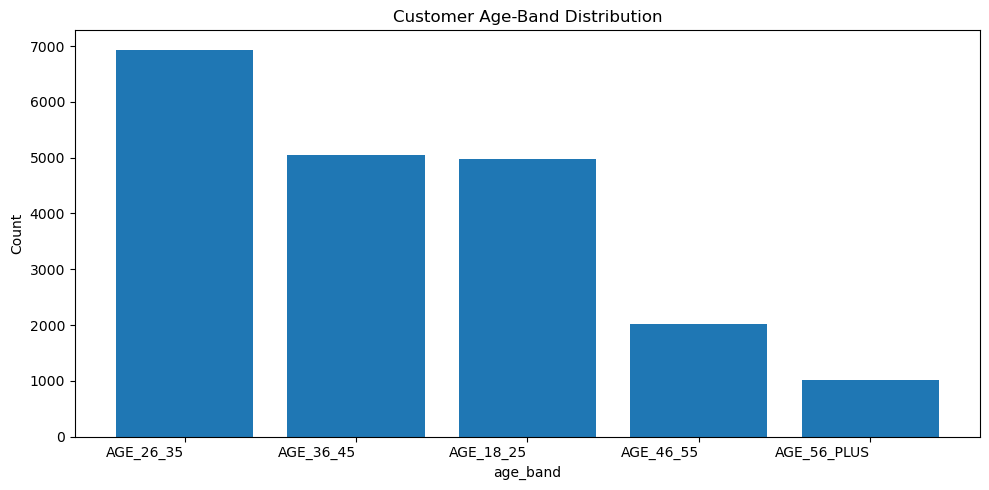

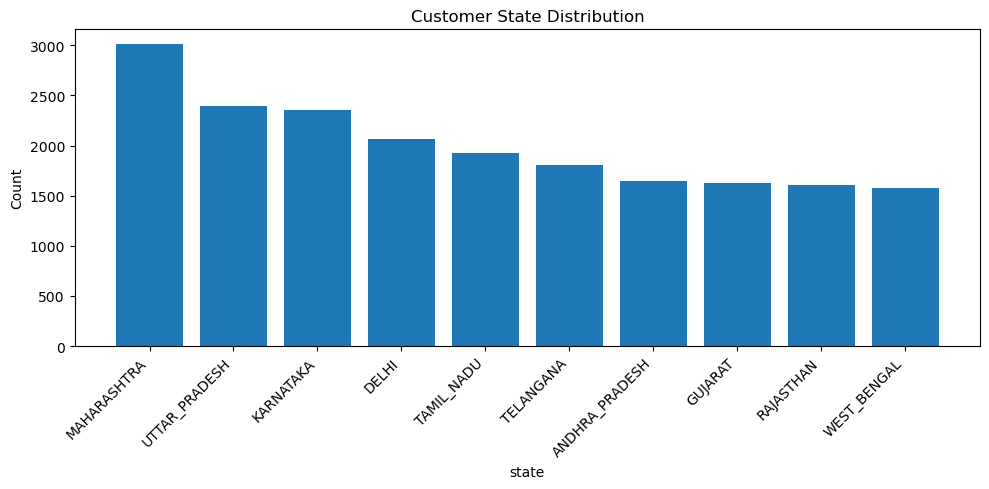

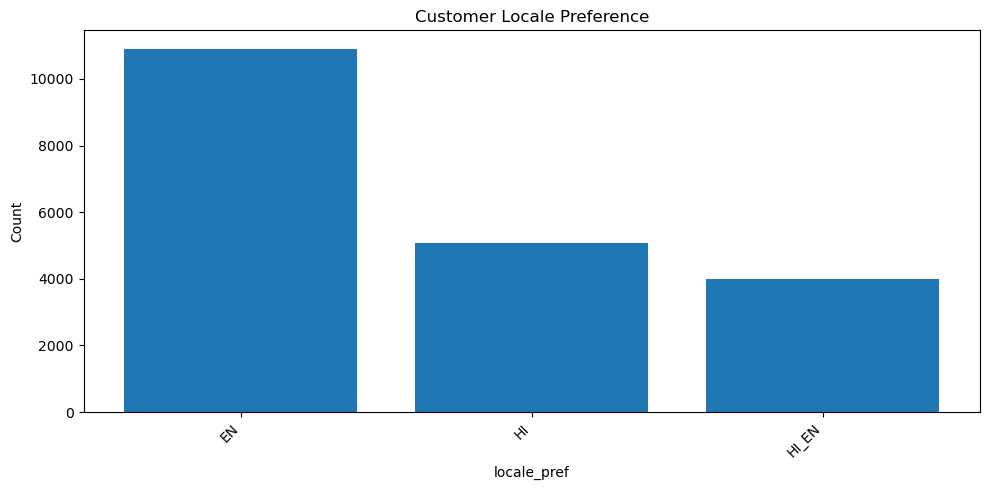

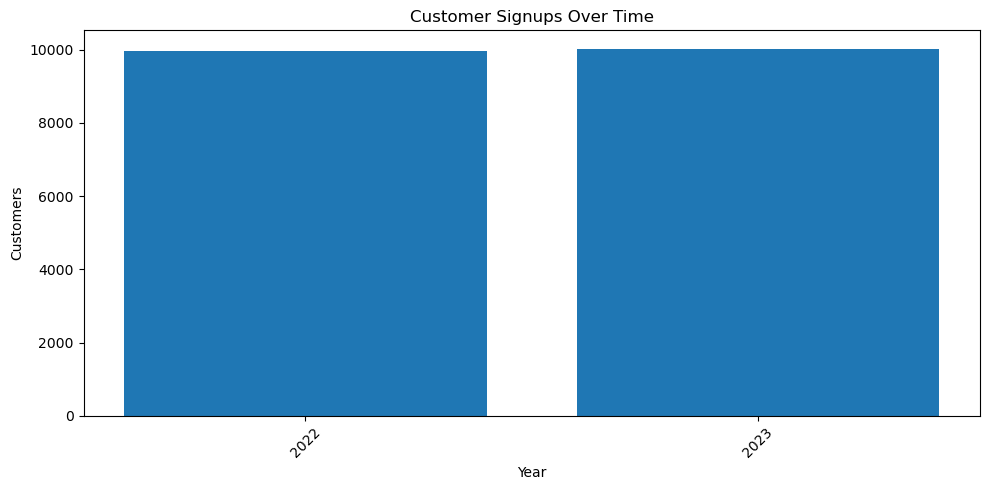

In [3]:

cust = data["customers"]

for col, title, filename in [
    ("age_band", "Customer Age-Band Distribution", "customers_age_band.png"),
    ("state", "Customer State Distribution", "customers_state.png"),
    ("locale_pref", "Customer Locale Preference", "customers_locale.png"),
]:
    if col in cust.columns:
        bar_counts(
            cust[col],
            title,
            filename,
            rotation=45 if col in {"state", "locale_pref"} else 0,
            top_n=20 if col == "state" else None,
        )

# Signup timeline if available
date_col = next(
    (c for c in ["signed_up_date", "signup_date"] if c in cust.columns),
    None
)

if date_col:
    dates = pd.to_datetime(
        cust[date_col],
        errors="coerce"
    ).dropna()

    yearly = dates.dt.to_period("Y").value_counts().sort_index()

    plt.figure(figsize=(10, 5))
    plt.bar(
        yearly.index.astype(str),
        yearly.values
    )
    plt.title("Customer Signups Over Time")
    plt.xlabel("Year")
    plt.ylabel("Customers")
    plt.xticks(rotation=45)
    save_show("customers_signup_timeline.png")


## 2. Subscriptions — Graphical EDA

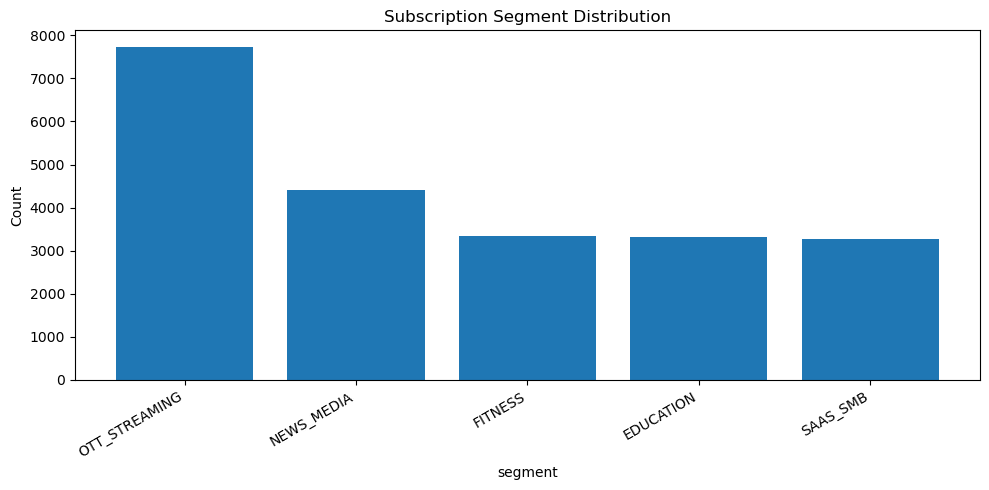

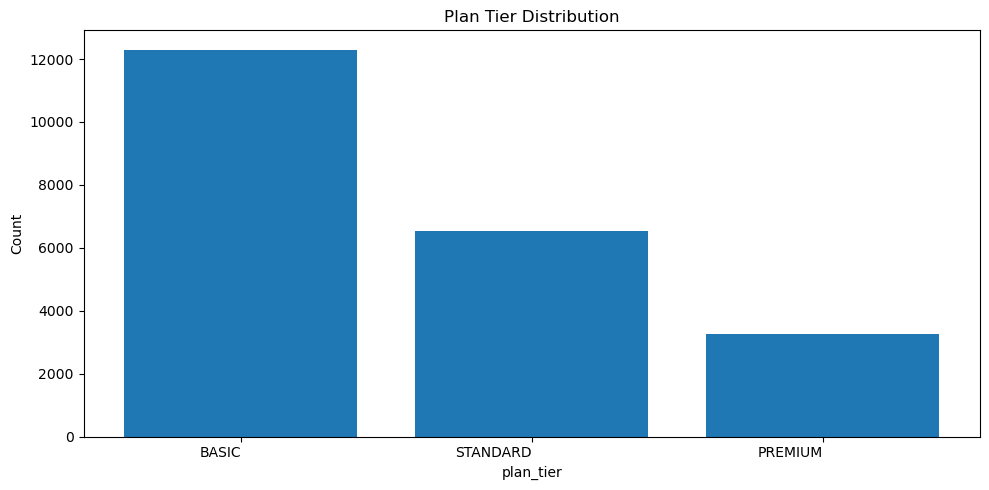

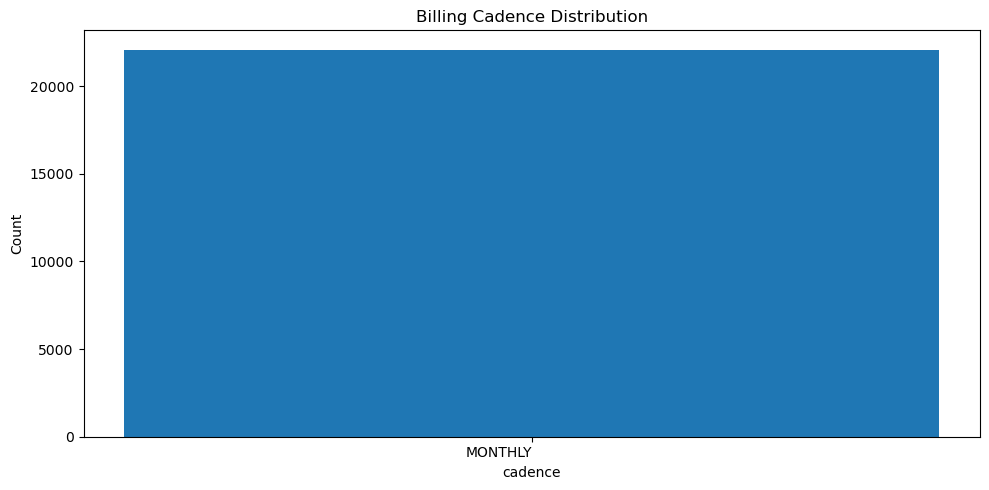

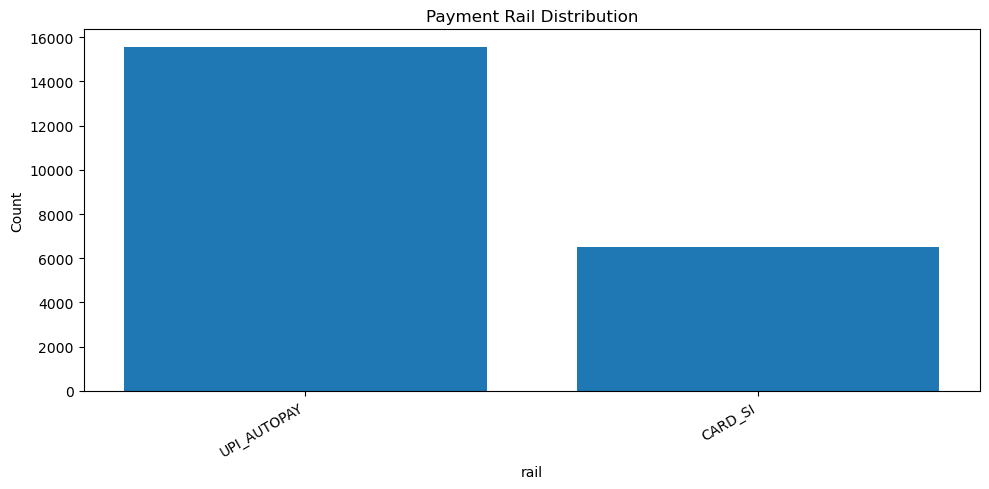

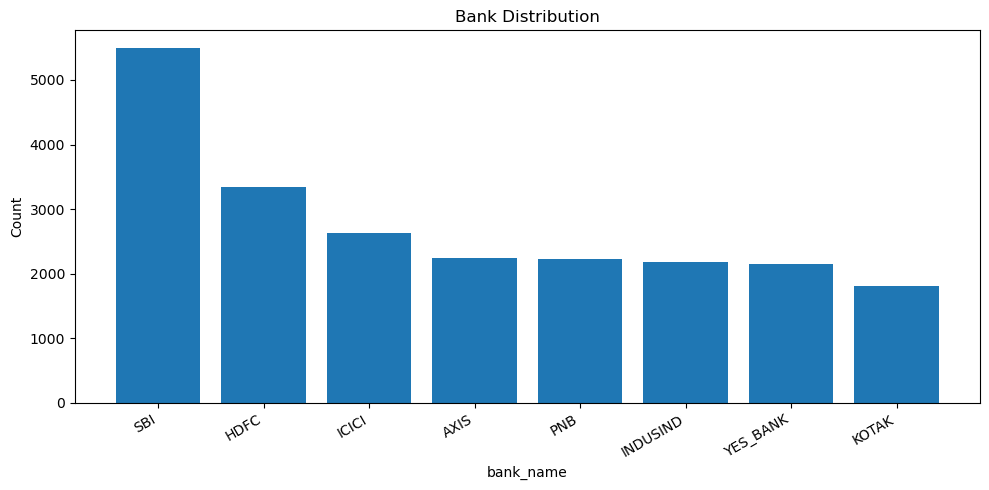

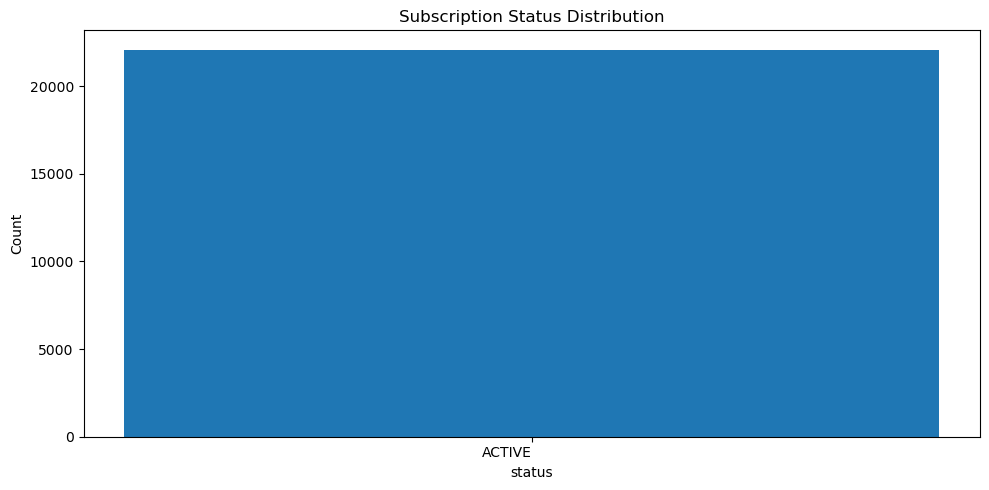

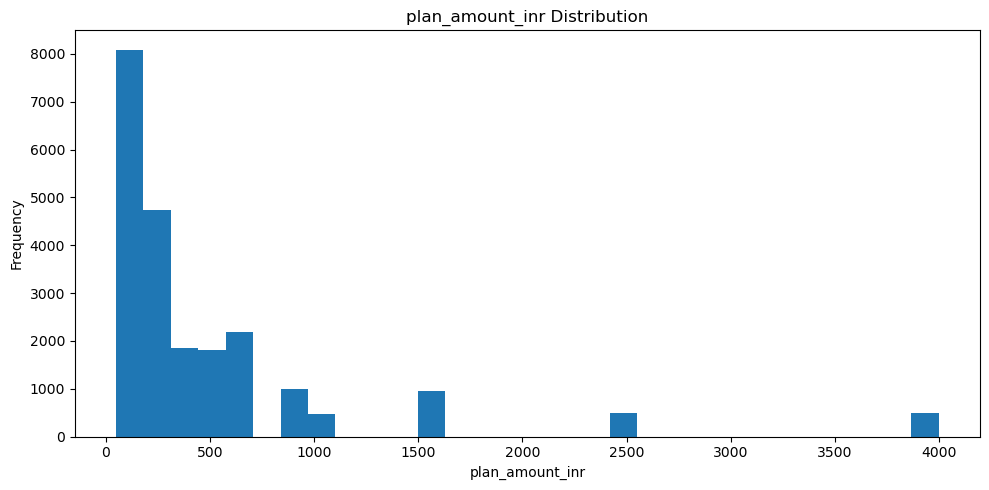

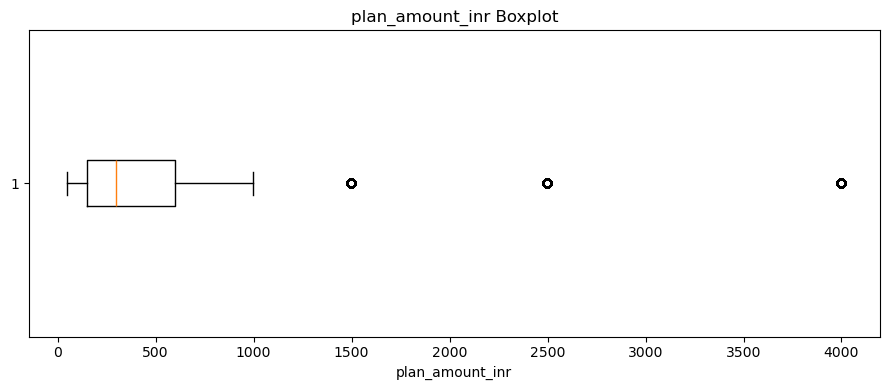

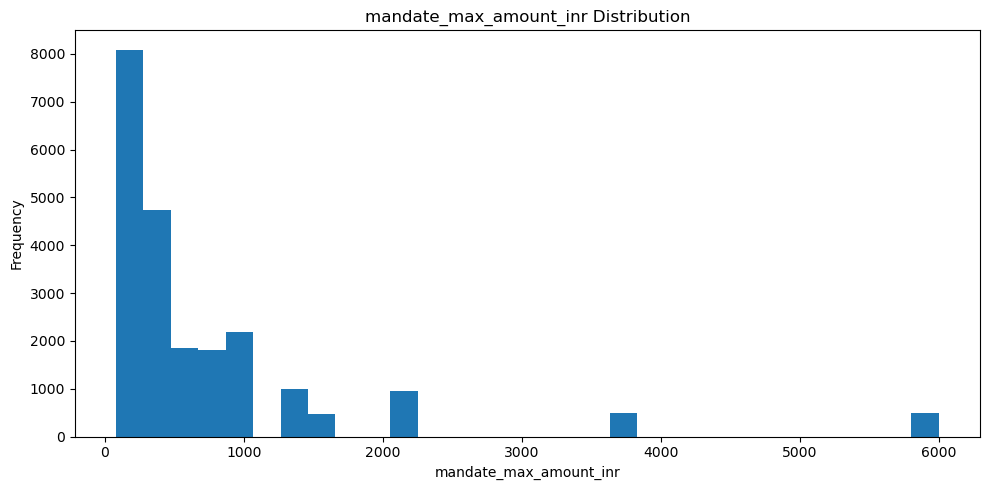

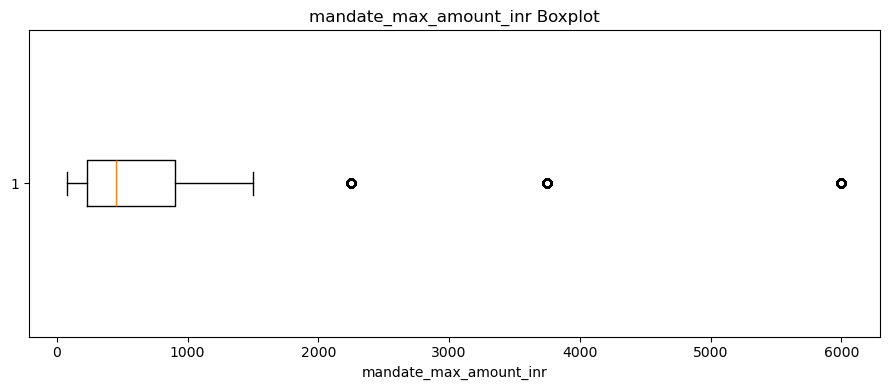

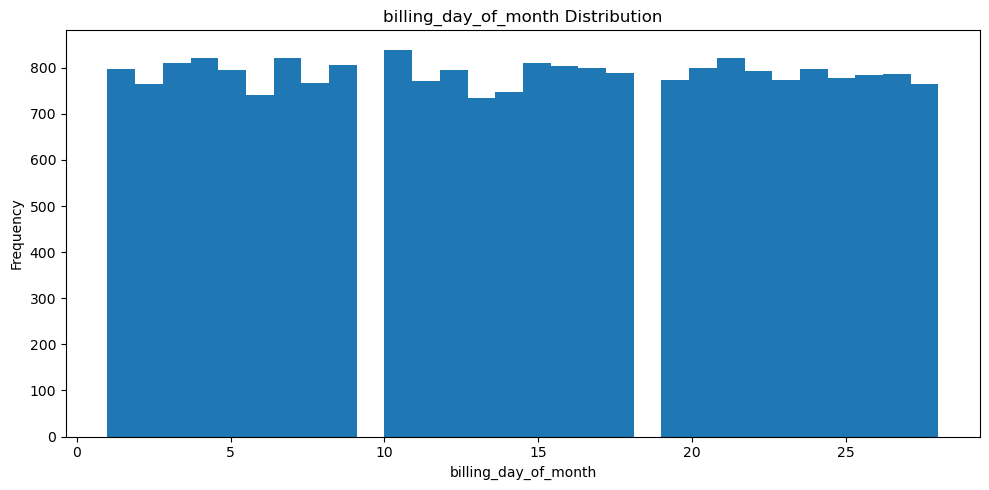

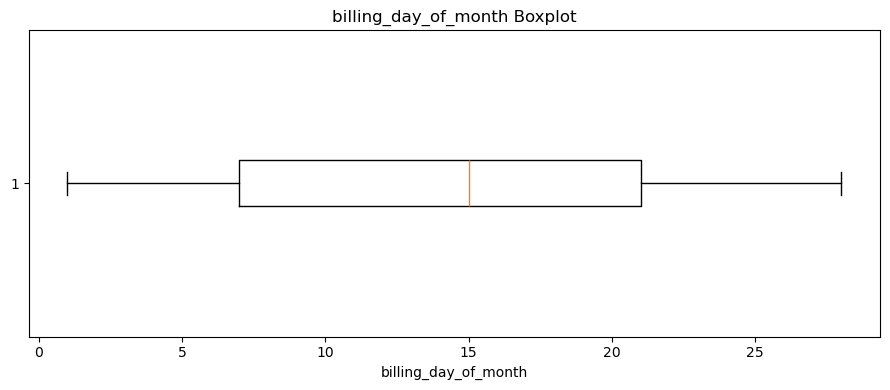

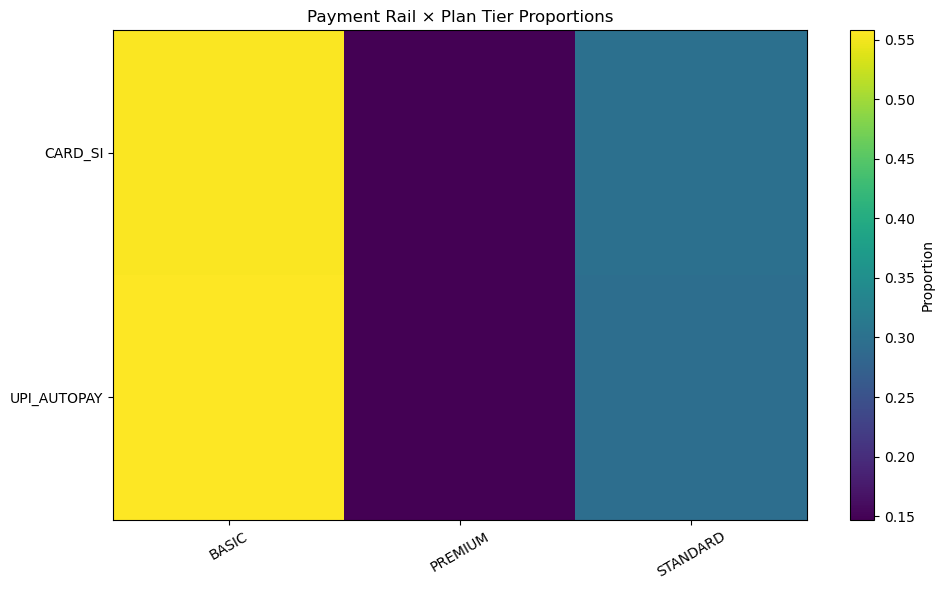

In [4]:

subs = data["subscriptions"]

for col, title, filename, rot in [
    ("segment", "Subscription Segment Distribution", "subscriptions_segment.png", 30),
    ("plan_tier", "Plan Tier Distribution", "subscriptions_plan_tier.png", 0),
    ("cadence", "Billing Cadence Distribution", "subscriptions_cadence.png", 0),
    ("rail", "Payment Rail Distribution", "subscriptions_rail.png", 30),
    ("bank_name", "Bank Distribution", "subscriptions_bank.png", 30),
    ("status", "Subscription Status Distribution", "subscriptions_status.png", 0),
]:
    if col in subs.columns:
        bar_counts(
            subs[col],
            title,
            filename,
            rotation=rot,
            top_n=20 if col == "bank_name" else None,
        )

for col in [
    "plan_amount_inr",
    "mandate_max_amount_inr",
    "billing_day_of_month",
]:
    if col in subs.columns:
        plot_numeric_hist(
            subs[col],
            f"{col} Distribution",
            f"subscriptions_{col}.png",
            bins=30,
        )
        plot_box(
            subs[col],
            f"{col} Boxplot",
            f"subscriptions_{col}_box.png"
        )

if {"rail", "plan_tier"}.issubset(subs.columns):
    ct = pd.crosstab(
        subs["rail"],
        subs["plan_tier"],
        normalize="index"
    )

    plt.figure(figsize=(10, 6))
    plt.imshow(ct.values, aspect="auto")
    plt.colorbar(label="Proportion")
    plt.xticks(
        range(len(ct.columns)),
        ct.columns.astype(str),
        rotation=30
    )
    plt.yticks(
        range(len(ct.index)),
        ct.index.astype(str)
    )
    plt.title("Payment Rail × Plan Tier Proportions")
    save_show("subscriptions_rail_plan_heatmap.png")


## 3. Payment Attempts — Graphical EDA

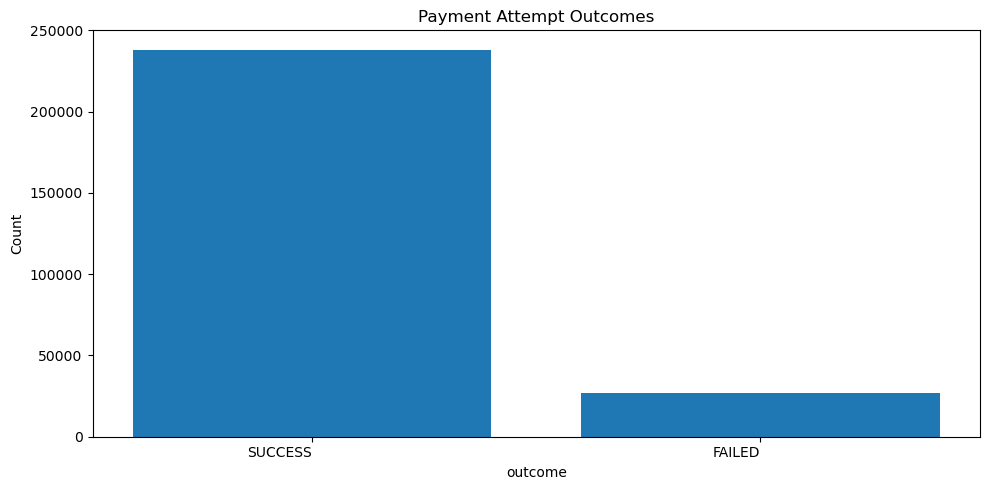

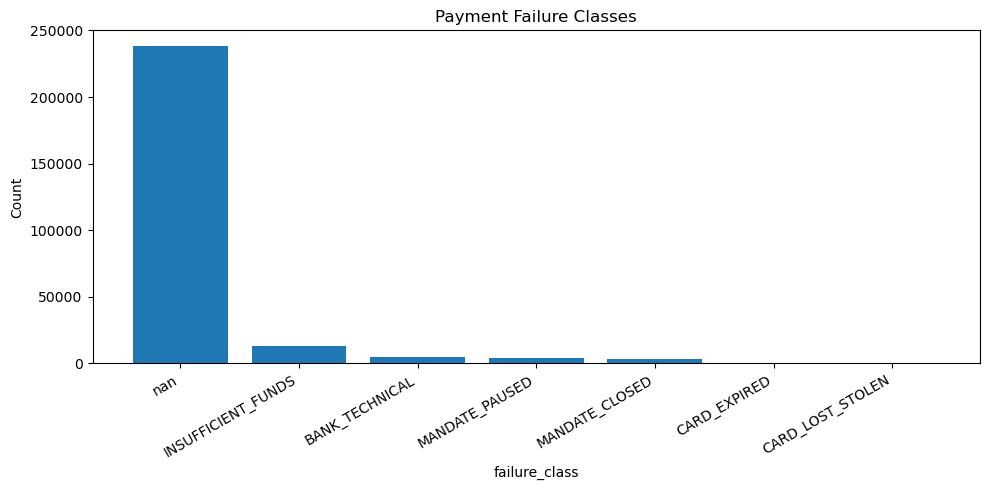

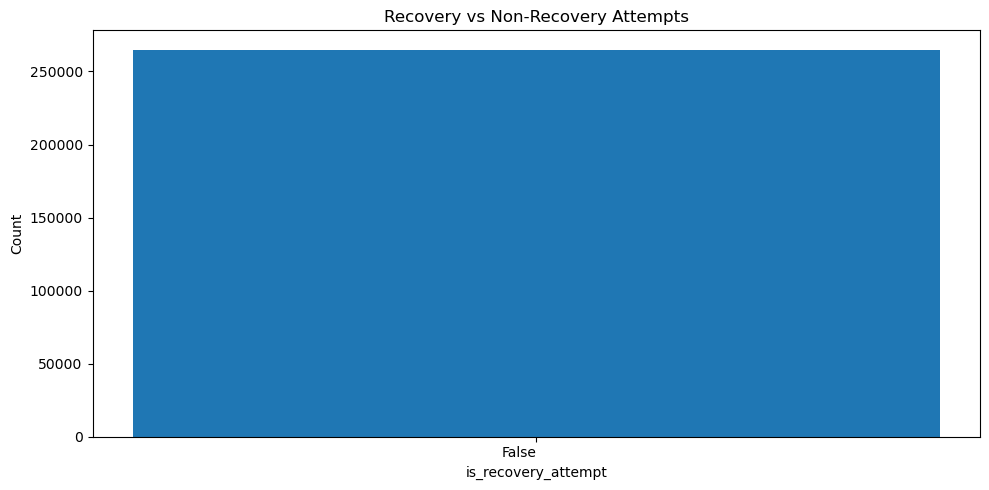

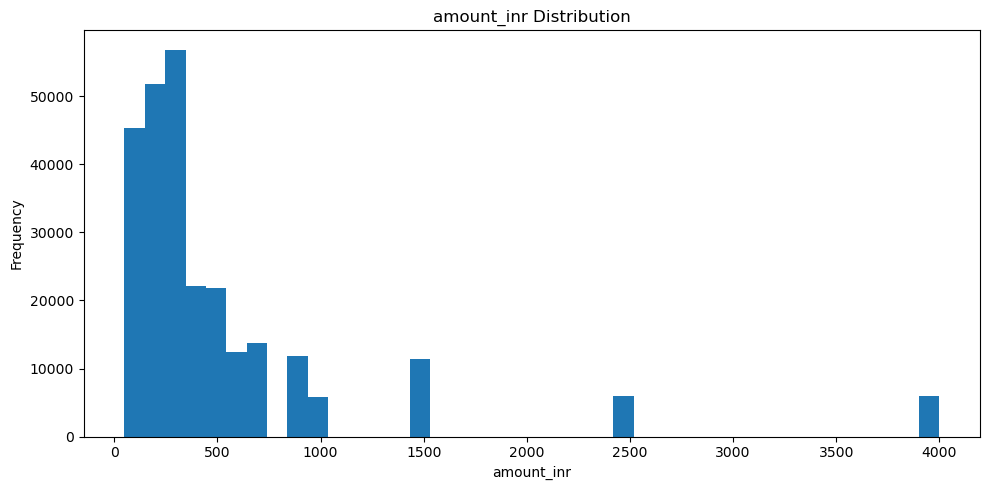

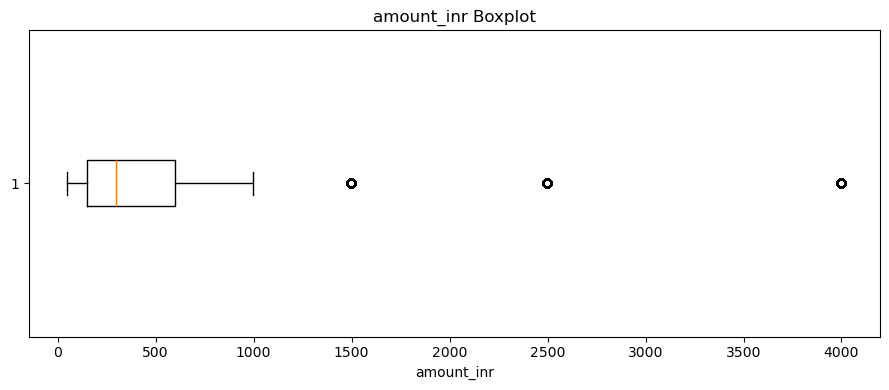

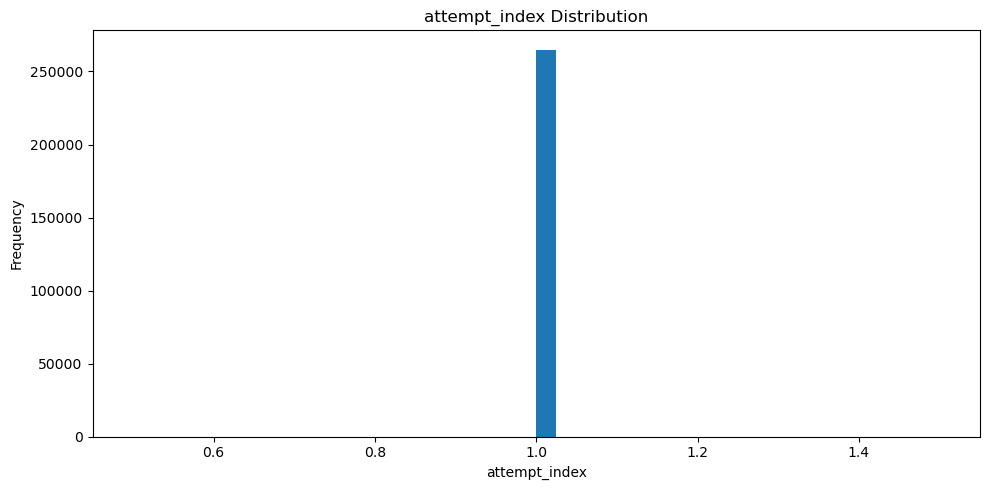

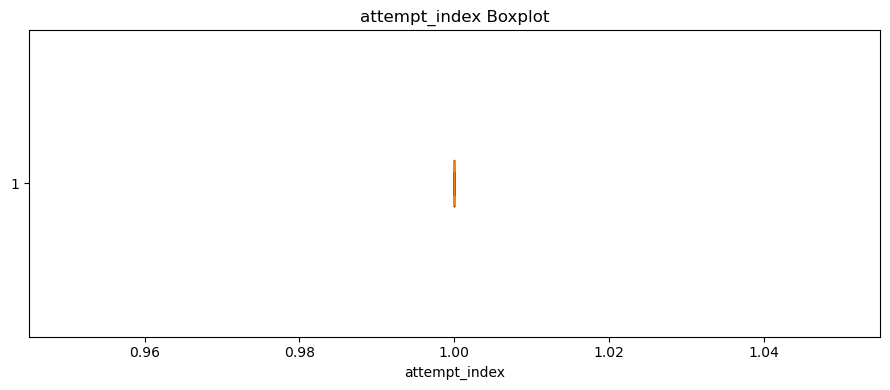

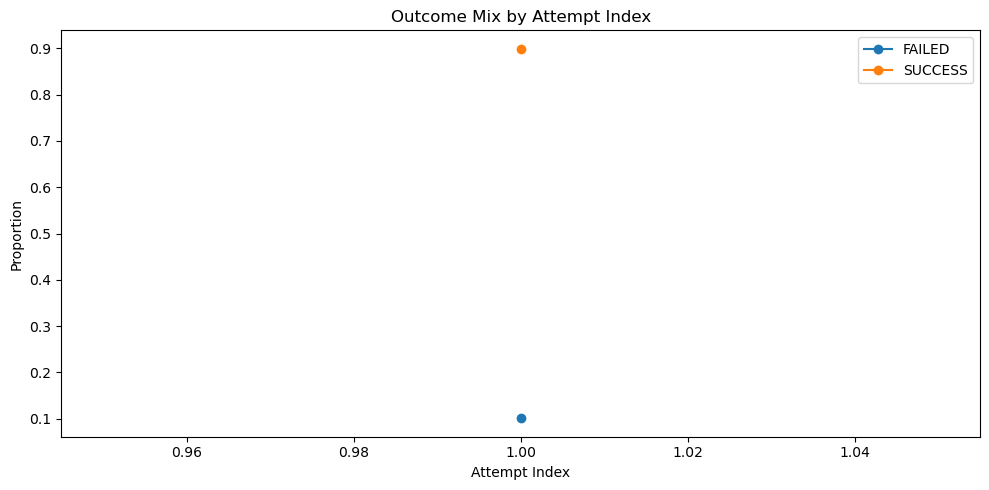

In [5]:

attempts = data["payment_attempts"]

for col, title, filename, rot in [
    ("outcome", "Payment Attempt Outcomes", "attempts_outcome.png", 0),
    ("failure_class", "Payment Failure Classes", "attempts_failure_class.png", 30),
    ("is_recovery_attempt", "Recovery vs Non-Recovery Attempts", "attempts_recovery_flag.png", 0),
]:
    if col in attempts.columns:
        bar_counts(
            attempts[col],
            title,
            filename,
            rotation=rot,
        )

for col in ["amount_inr", "attempt_index"]:
    if col in attempts.columns:
        plot_numeric_hist(
            attempts[col],
            f"{col} Distribution",
            f"attempts_{col}.png",
            bins=40,
        )
        plot_box(
            attempts[col],
            f"{col} Boxplot",
            f"attempts_{col}_box.png"
        )

if {"attempt_index", "outcome"}.issubset(attempts.columns):
    attempt_outcome = pd.crosstab(
        attempts["attempt_index"],
        attempts["outcome"],
        normalize="index"
    )

    plt.figure(figsize=(10, 5))
    for col in attempt_outcome.columns:
        plt.plot(
            attempt_outcome.index,
            attempt_outcome[col],
            marker="o",
            label=str(col)
        )

    plt.title("Outcome Mix by Attempt Index")
    plt.xlabel("Attempt Index")
    plt.ylabel("Proportion")
    plt.legend()
    save_show("attempts_outcome_by_index.png")


## 4. Recovery Cases — Graphical EDA

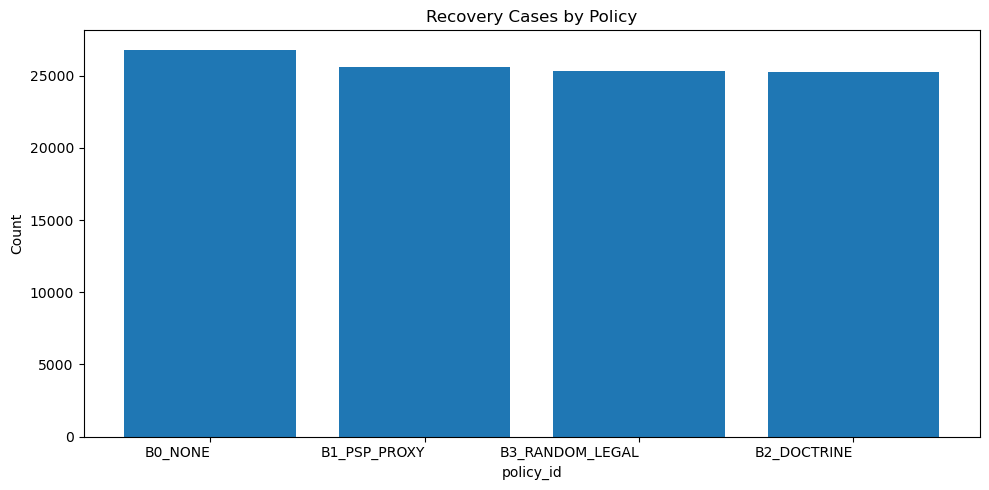

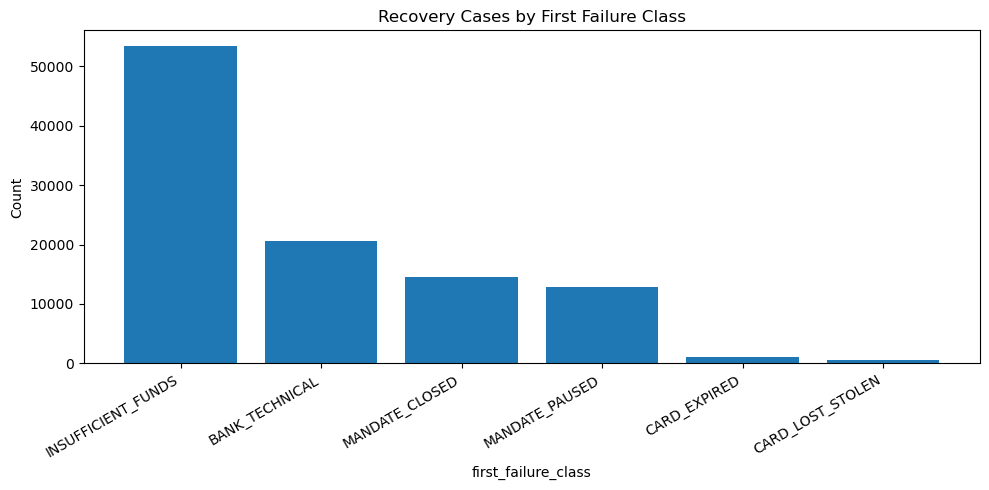

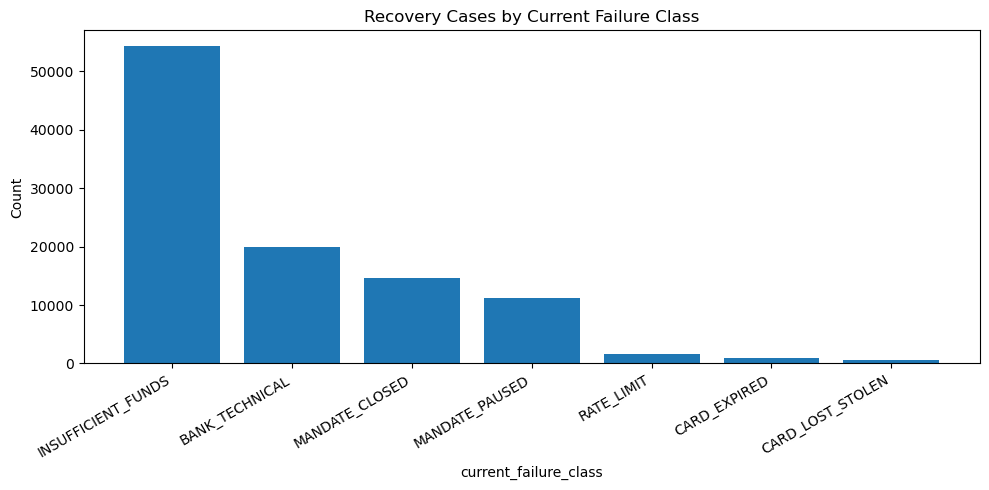

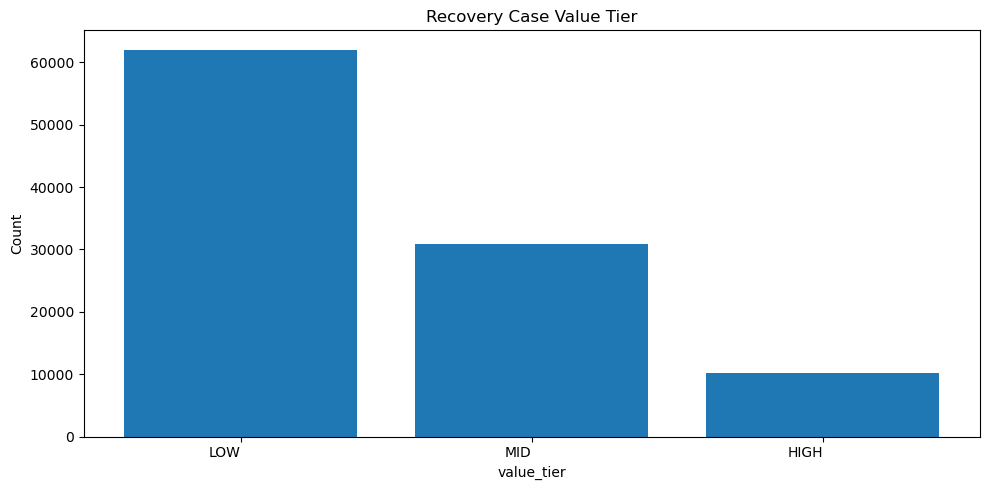

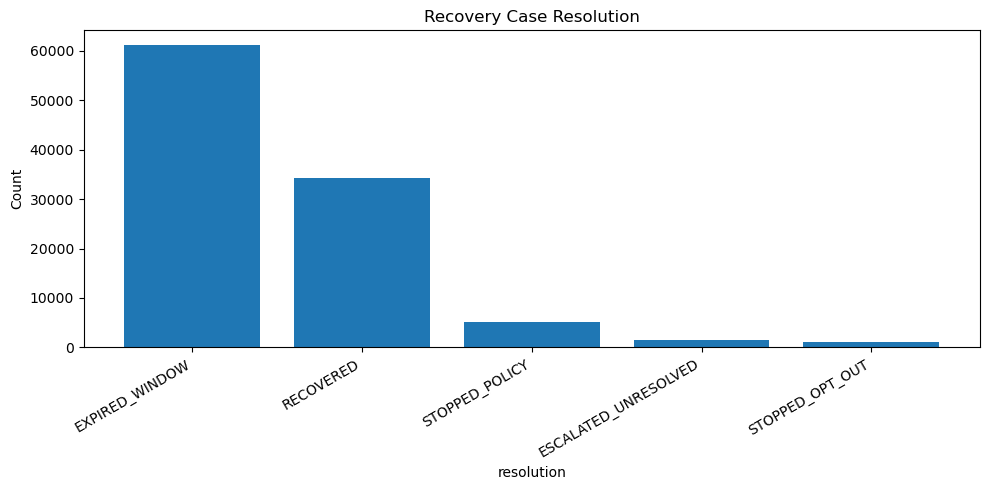

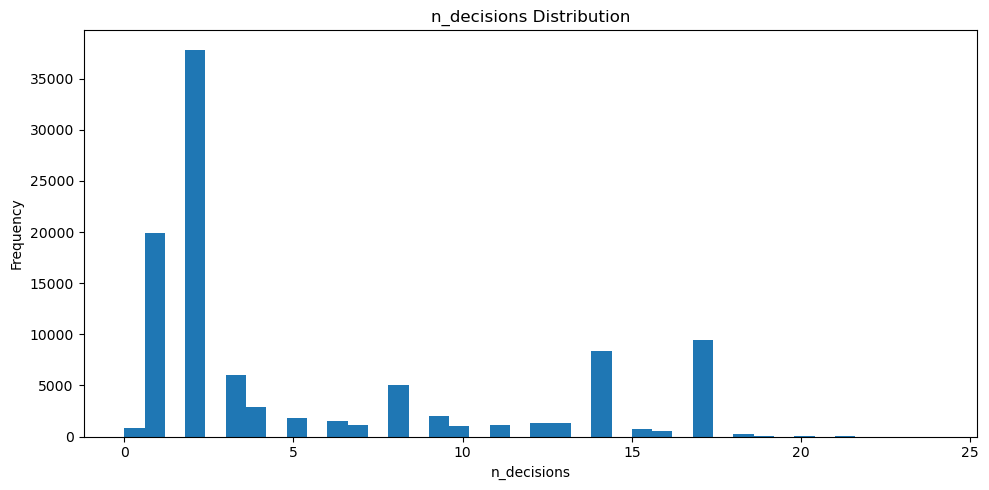

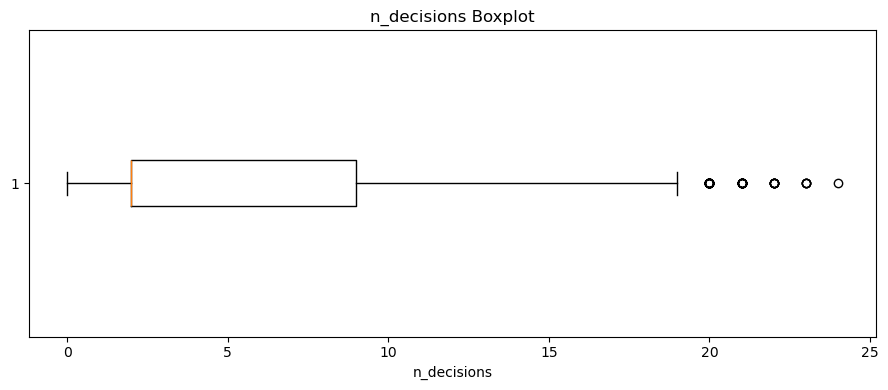

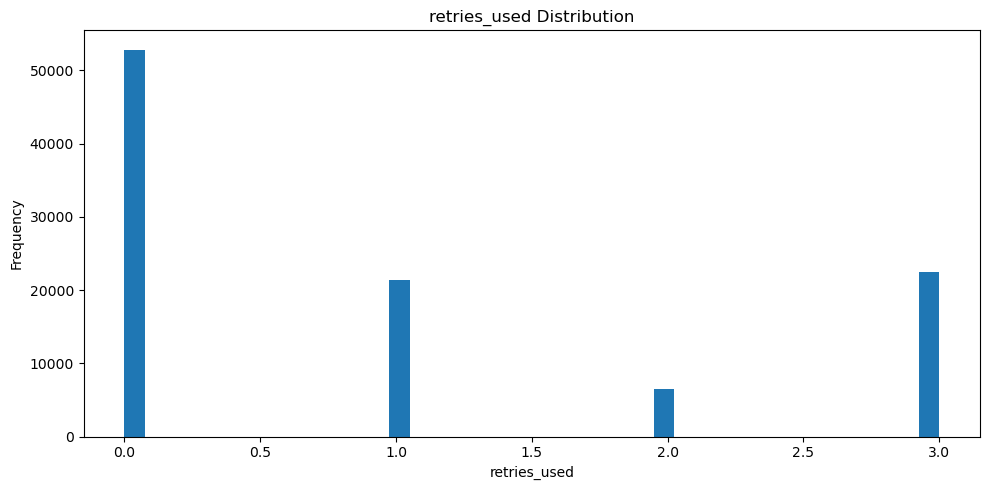

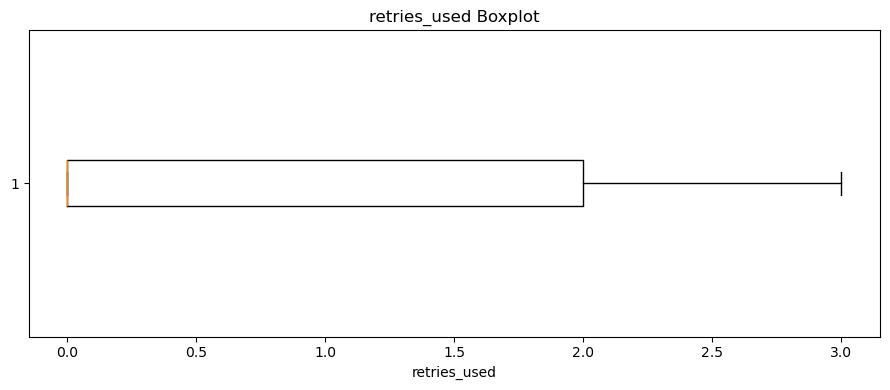

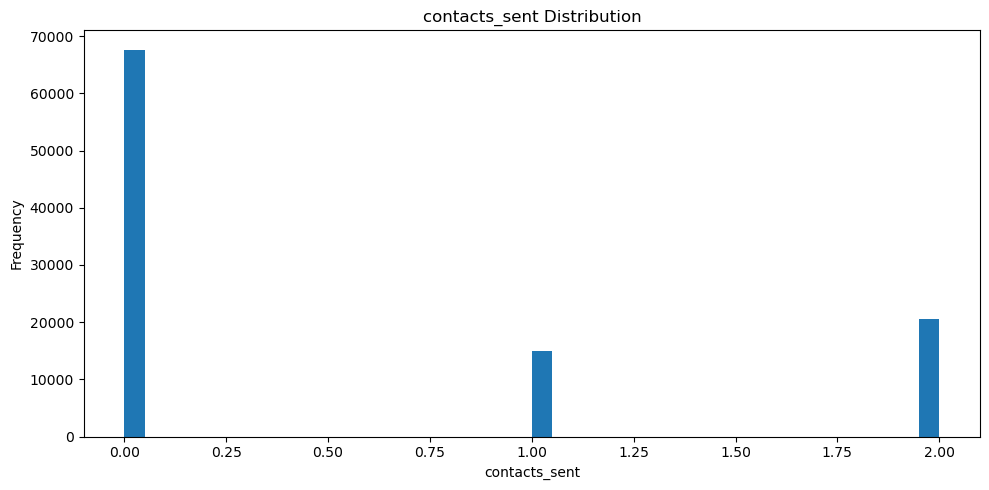

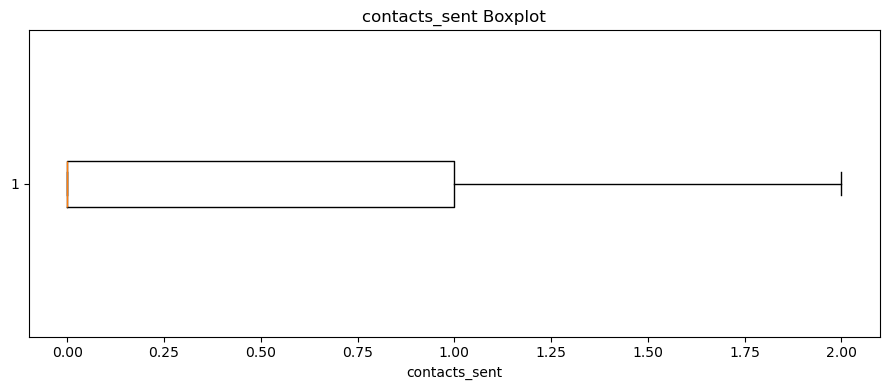

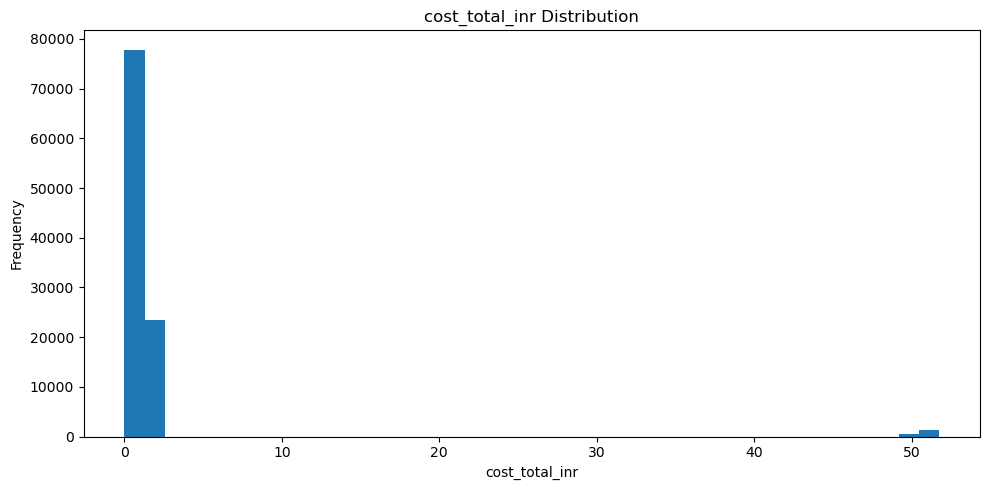

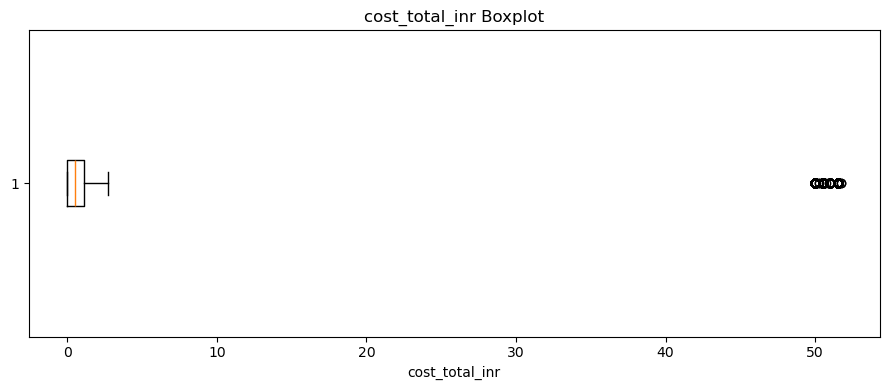

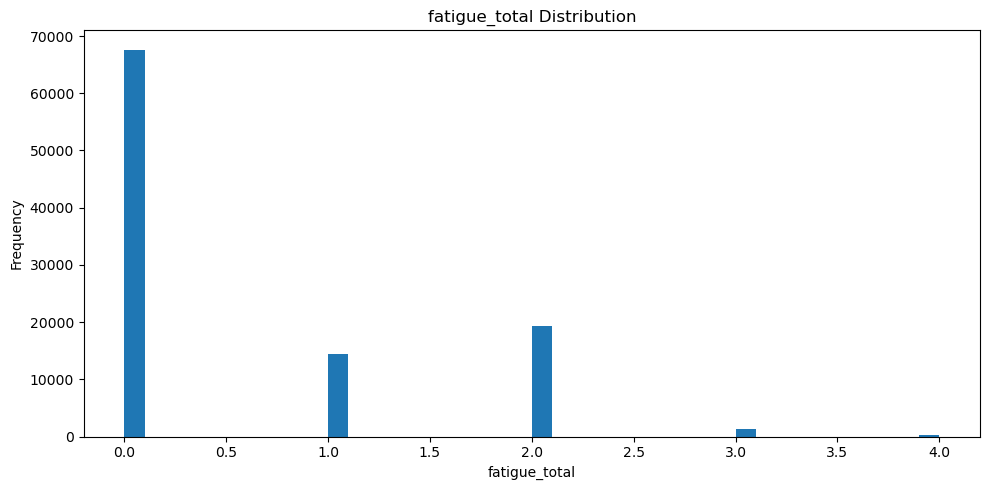

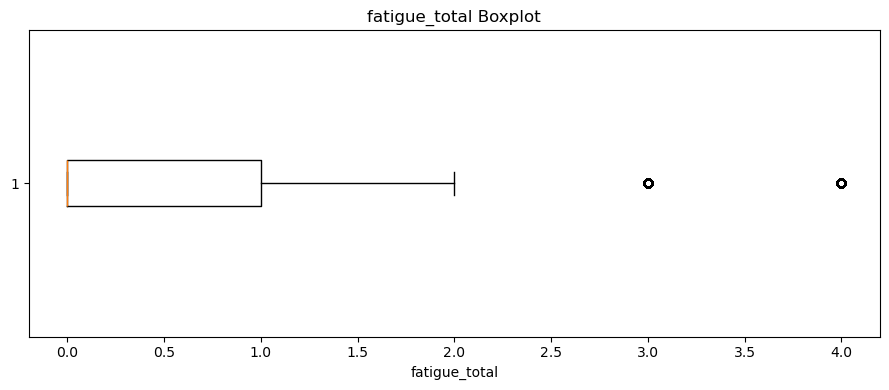

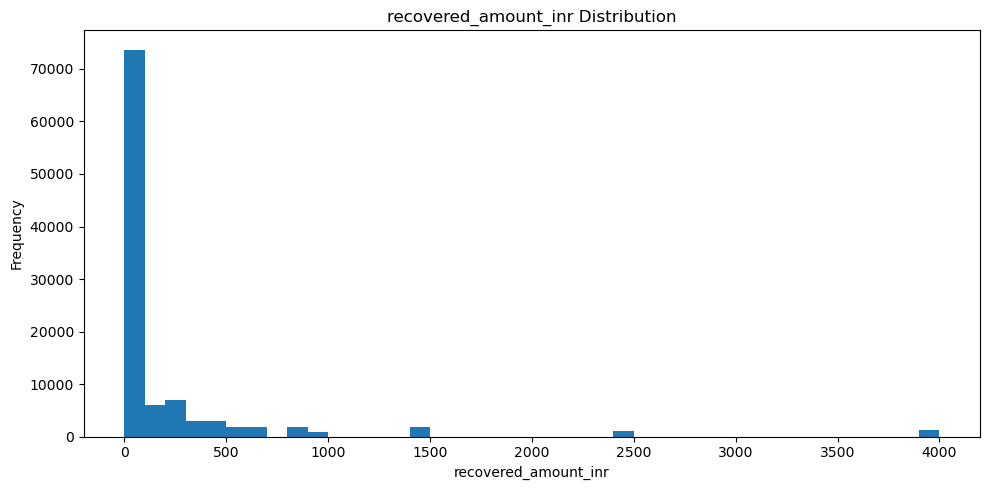

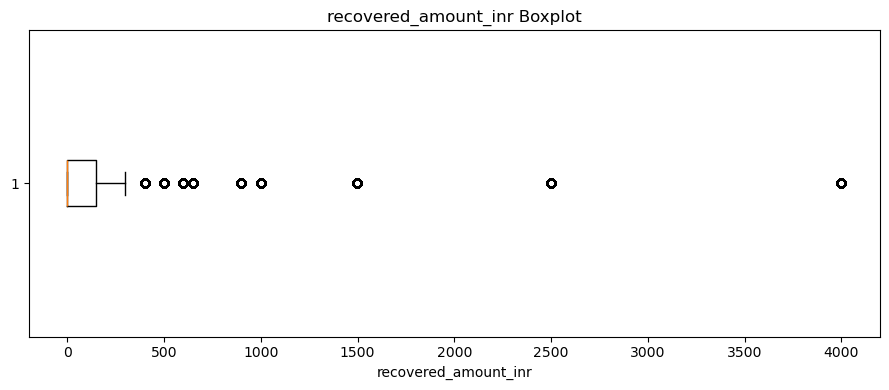

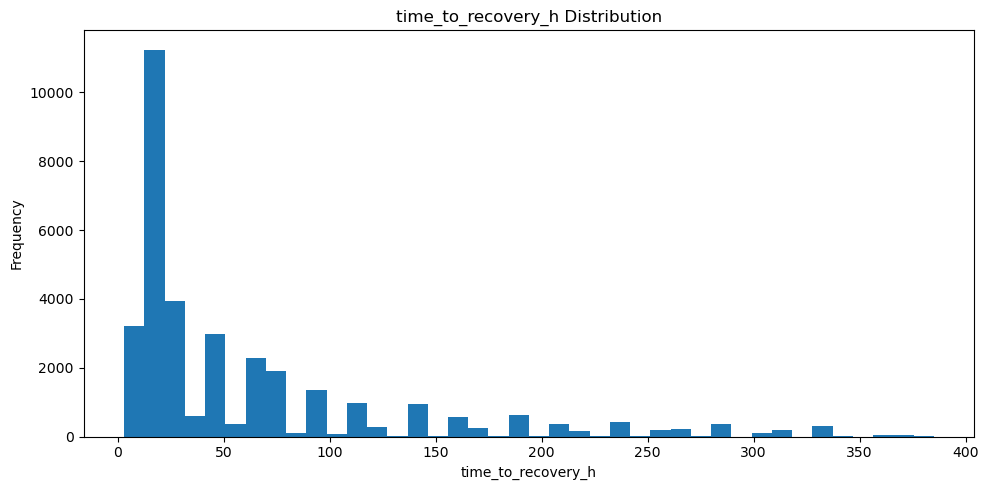

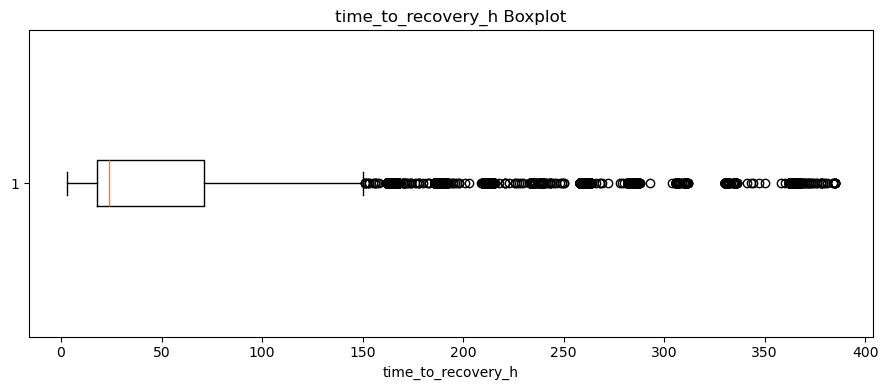

In [6]:

cases = data["recovery_cases"]

for col, title, filename, rot in [
    ("policy_id", "Recovery Cases by Policy", "cases_policy.png", 0),
    ("first_failure_class", "Recovery Cases by First Failure Class", "cases_failure_class.png", 30),
    ("current_failure_class", "Recovery Cases by Current Failure Class", "cases_current_failure.png", 30),
    ("value_tier", "Recovery Case Value Tier", "cases_value_tier.png", 0),
    ("resolution", "Recovery Case Resolution", "cases_resolution.png", 30),
]:
    if col in cases.columns:
        bar_counts(
            cases[col],
            title,
            filename,
            rotation=rot,
        )

for col in [
    "amount_at_risk",
    "n_decisions",
    "retries_used",
    "contacts_sent",
    "cost_total_inr",
    "fatigue_total",
    "recovered_amount_inr",
    "time_to_recovery_h",
]:
    if col in cases.columns:
        plot_numeric_hist(
            cases[col],
            f"{col} Distribution",
            f"cases_{col}.png",
            bins=40,
            log_x=col in {"amount_at_risk", "cost_total_inr"},
        )
        plot_box(
            cases[col],
            f"{col} Boxplot",
            f"cases_{col}_box.png",
        )


## 5. Recovery Events — Graphical EDA

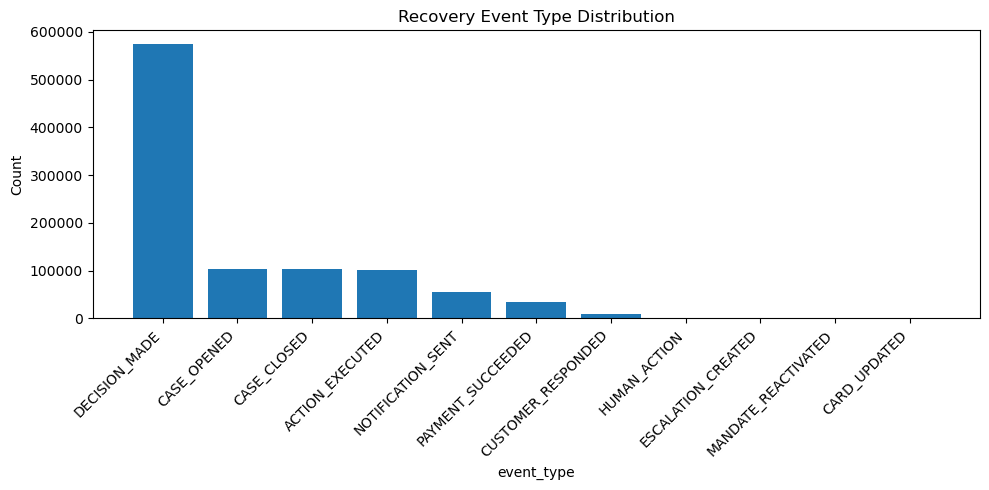

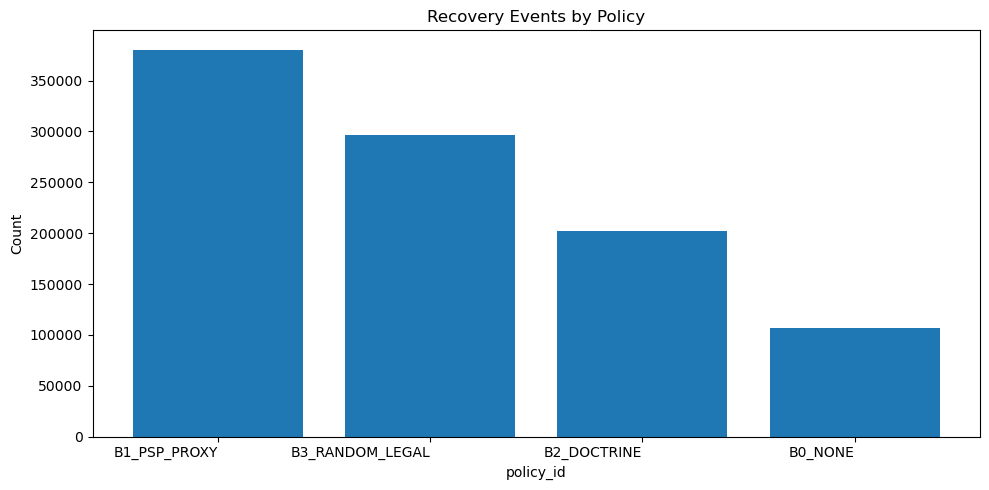

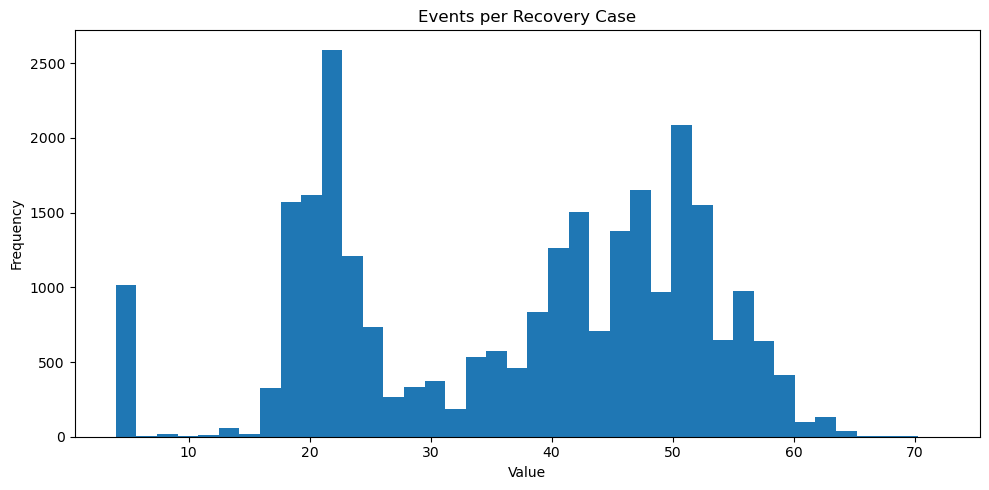

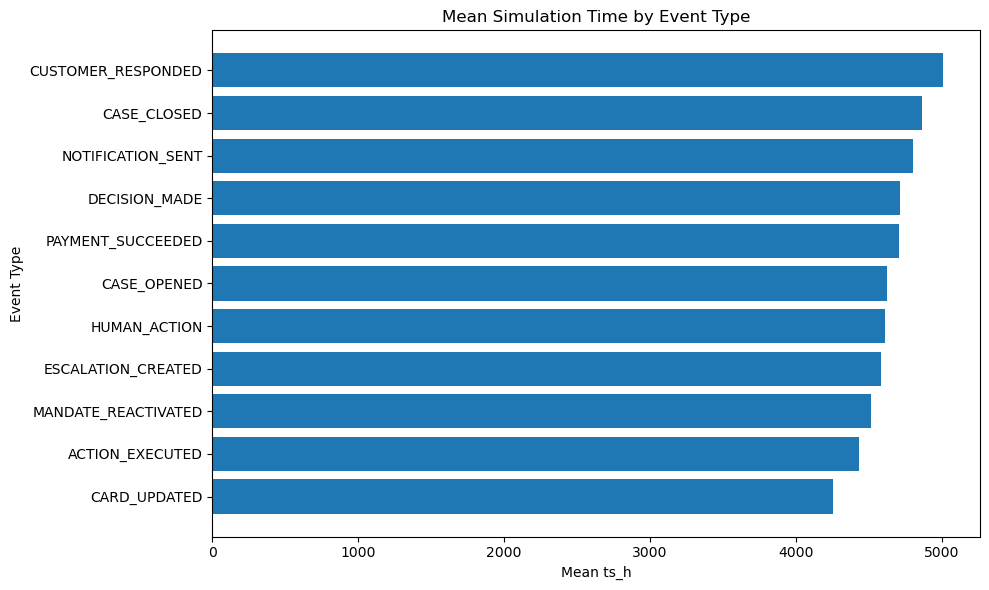

In [7]:

events = data["recovery_events"]

if "event_type" in events.columns:
    bar_counts(
        events["event_type"],
        "Recovery Event Type Distribution",
        "events_event_type.png",
        rotation=45,
    )

if "policy_id" in events.columns:
    bar_counts(
        events["policy_id"],
        "Recovery Events by Policy",
        "events_policy.png",
    )

if "case_id" in events.columns:
    event_counts = events.groupby("case_id").size()

    plot_numeric_hist(
        event_counts,
        "Events per Recovery Case",
        "events_per_case.png",
        bins=40,
    )

if {"event_type", "ts_h"}.issubset(events.columns):
    event_times = (
        events.groupby("event_type")["ts_h"]
        .mean()
        .sort_values()
    )

    plt.figure(figsize=(10, 6))
    plt.barh(
        event_times.index.astype(str),
        event_times.values
    )
    plt.title("Mean Simulation Time by Event Type")
    plt.xlabel("Mean ts_h")
    plt.ylabel("Event Type")
    save_show("events_mean_time_by_type.png")


## 6. Actions and Logging Policies — Graphical EDA

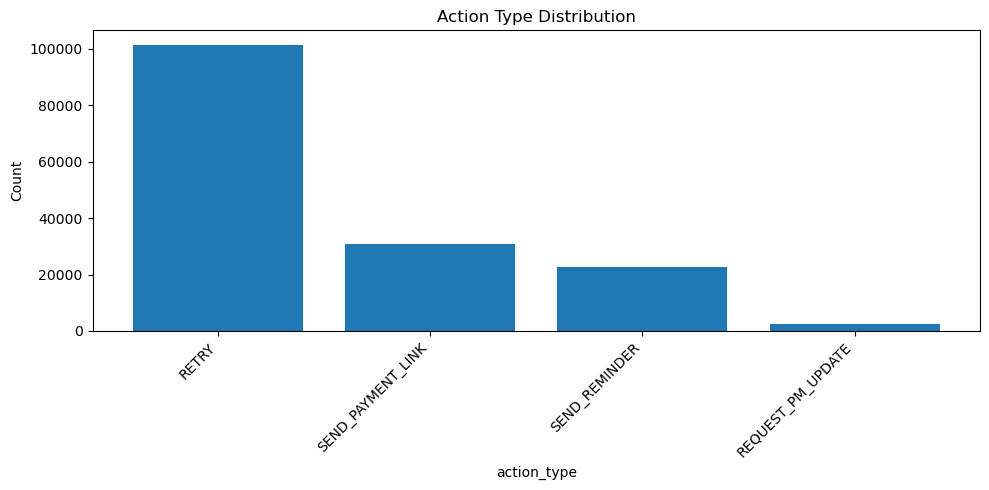

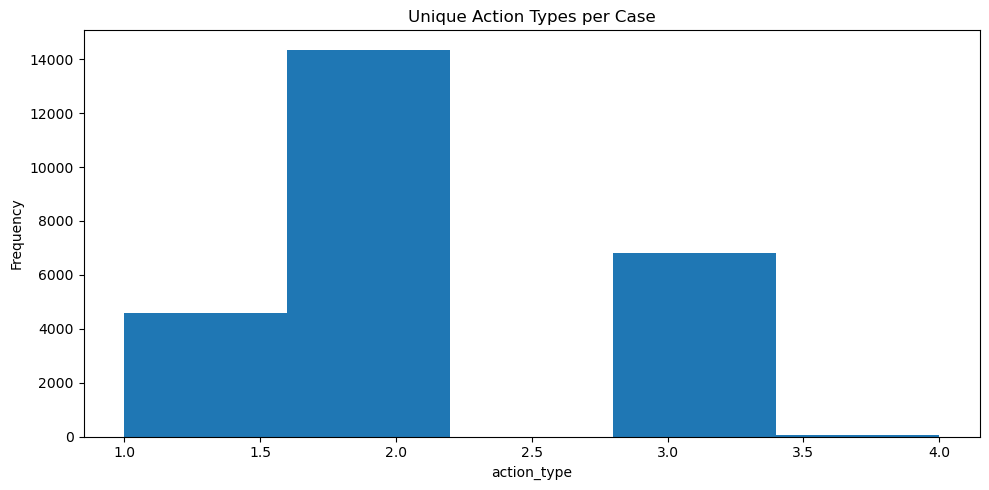

In [8]:

actions = data["action_log"]

if {"logging_policy", "action_type"}.issubset(actions.columns):
    ct = pd.crosstab(
        actions["logging_policy"],
        actions["action_type"],
        normalize="index"
    )

    plt.figure(figsize=(12, 6))
    plt.imshow(ct.values, aspect="auto")
    plt.colorbar(label="Action proportion")
    plt.xticks(
        range(len(ct.columns)),
        ct.columns.astype(str),
        rotation=45,
        ha="right"
    )
    plt.yticks(
        range(len(ct.index)),
        ct.index.astype(str)
    )
    plt.title("Policy × Action Proportion Heatmap")
    plt.xlabel("Action")
    plt.ylabel("Logging Policy")
    save_show("policy_action_heatmap.png")

if "action_type" in actions.columns:
    bar_counts(
        actions["action_type"],
        "Action Type Distribution",
        "actions_action_type.png",
        rotation=45,
    )

if "candidate_window_days_offset" in actions.columns:
    bar_counts(
        actions["candidate_window_days_offset"],
        "Candidate Execution Window Distribution",
        "actions_candidate_window.png",
        rotation=45,
    )

if {"case_id", "action_type"}.issubset(actions.columns):
    unique_actions_per_case = (
        actions.groupby("case_id")["action_type"]
        .nunique()
    )

    plot_numeric_hist(
        unique_actions_per_case,
        "Unique Action Types per Case",
        "actions_unique_types_per_case.png",
        bins=max(
            5,
            int(unique_actions_per_case.max())
            if len(unique_actions_per_case)
            else 5
        ),
    )


## 7. Terminal Outcomes — Graphical EDA

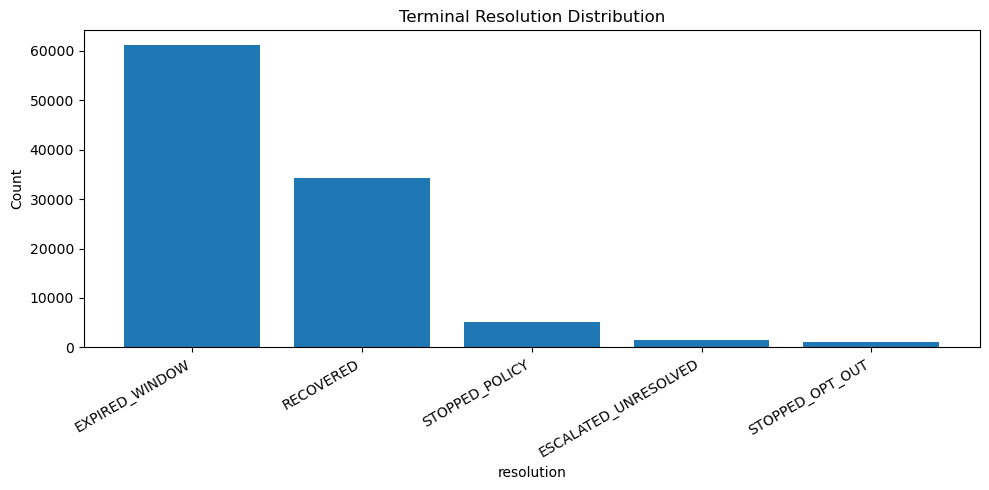

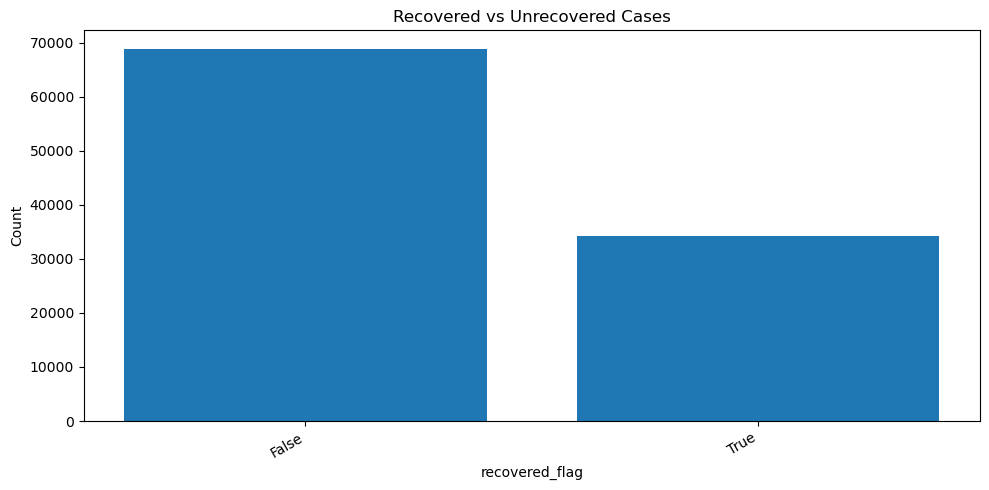

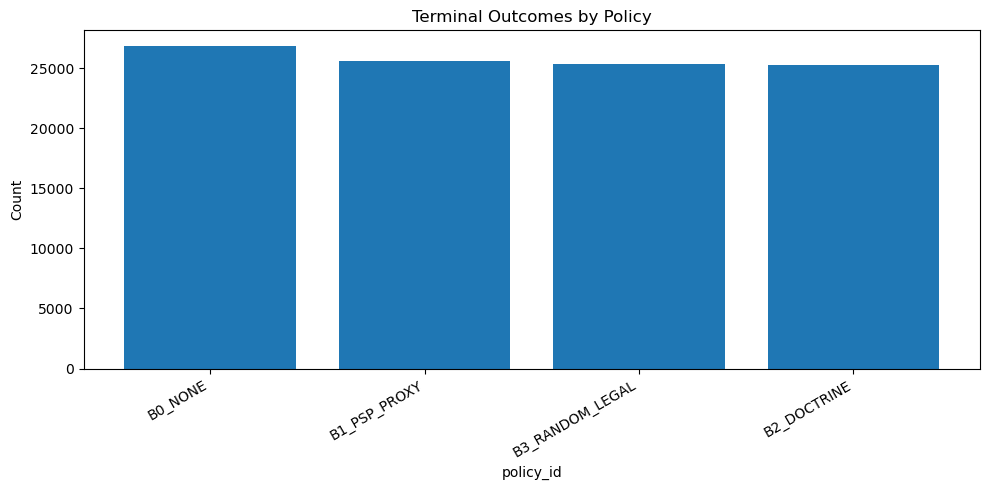

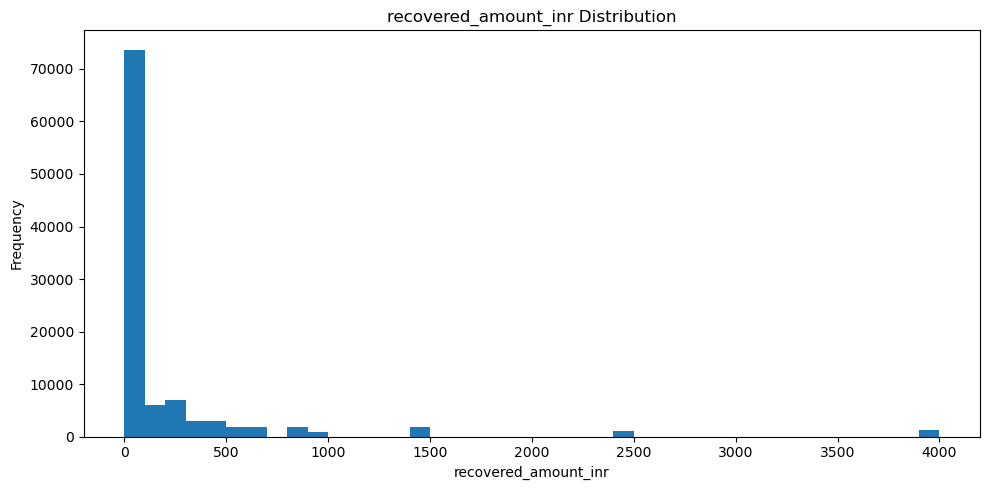

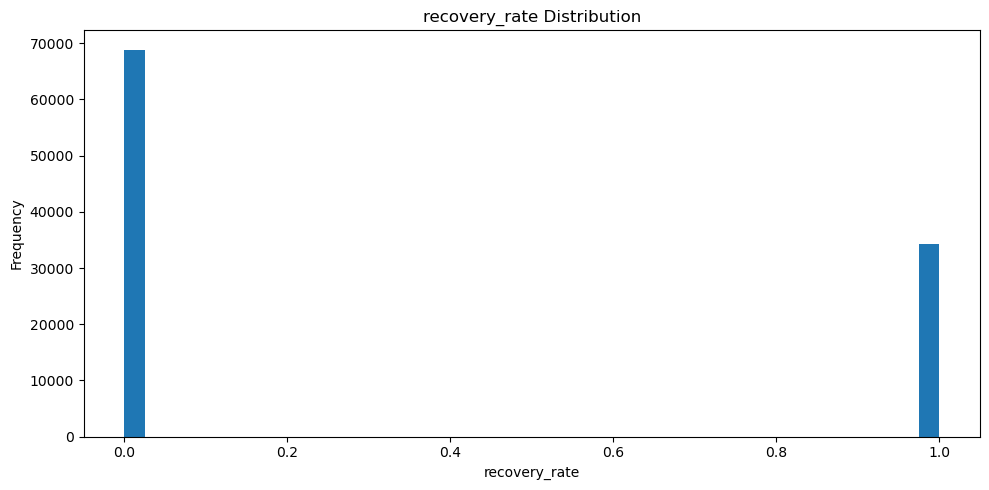

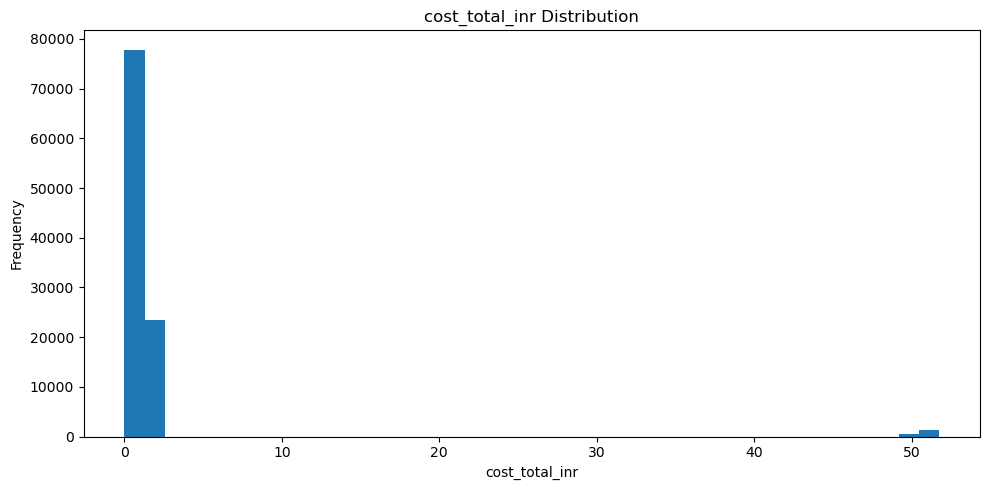

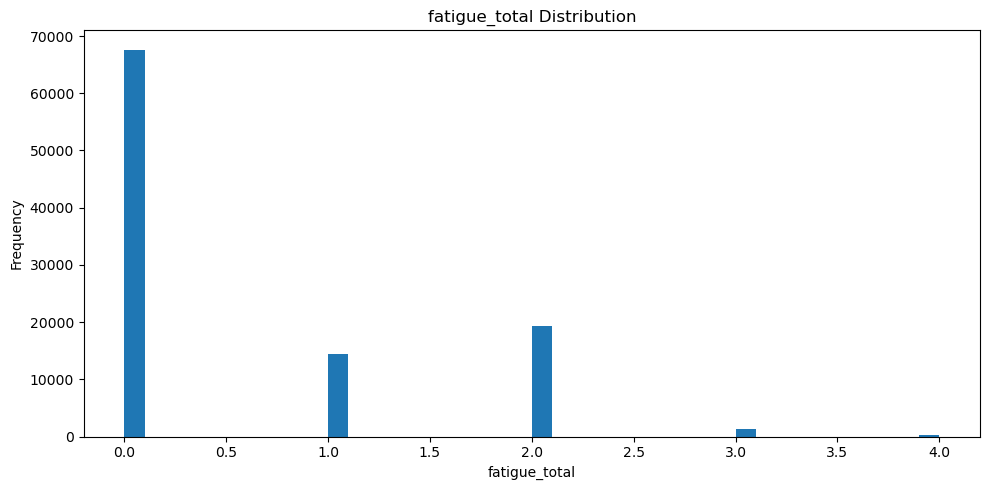

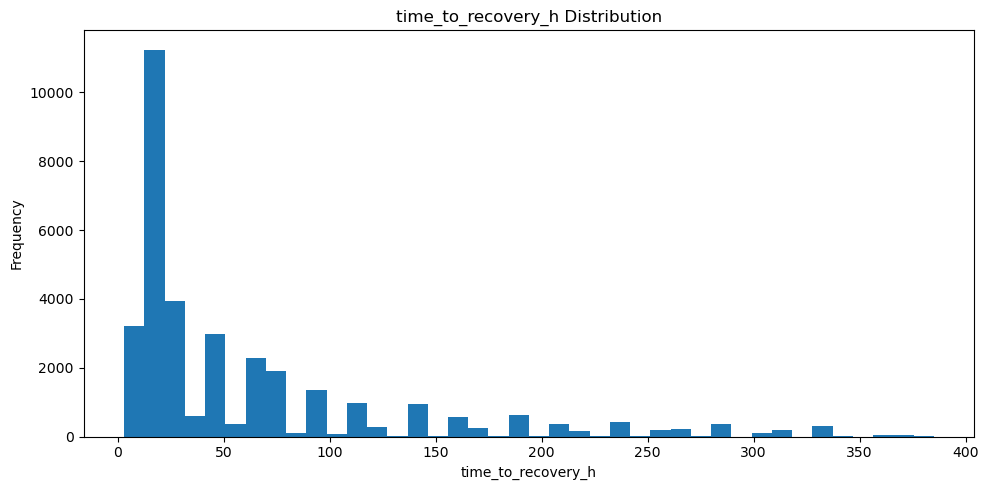

In [9]:

outcomes = data["case_outcomes"]

for col, title, filename in [
    ("resolution", "Terminal Resolution Distribution", "outcomes_resolution.png"),
    ("recovered_flag", "Recovered vs Unrecovered Cases", "outcomes_recovered_flag.png"),
    ("policy_id", "Terminal Outcomes by Policy", "outcomes_policy.png"),
]:
    if col in outcomes.columns:
        bar_counts(
            outcomes[col],
            title,
            filename,
            rotation=30,
        )

for col in [
    "recovered_amount_inr",
    "recovery_rate",
    "attempts_used",
    "contacts_used",
    "cost_total_inr",
    "fatigue_total",
    "time_to_recovery_h",
]:
    if col in outcomes.columns:
        plot_numeric_hist(
            outcomes[col],
            f"{col} Distribution",
            f"outcomes_{col}.png",
            bins=40,
        )


## 8. ML Target — Observed Outcome Graphs

These are **observed associations** in the logged dataset.
They are not causal treatment effects.

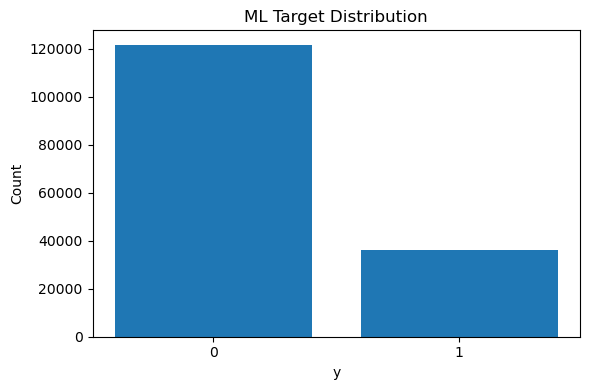

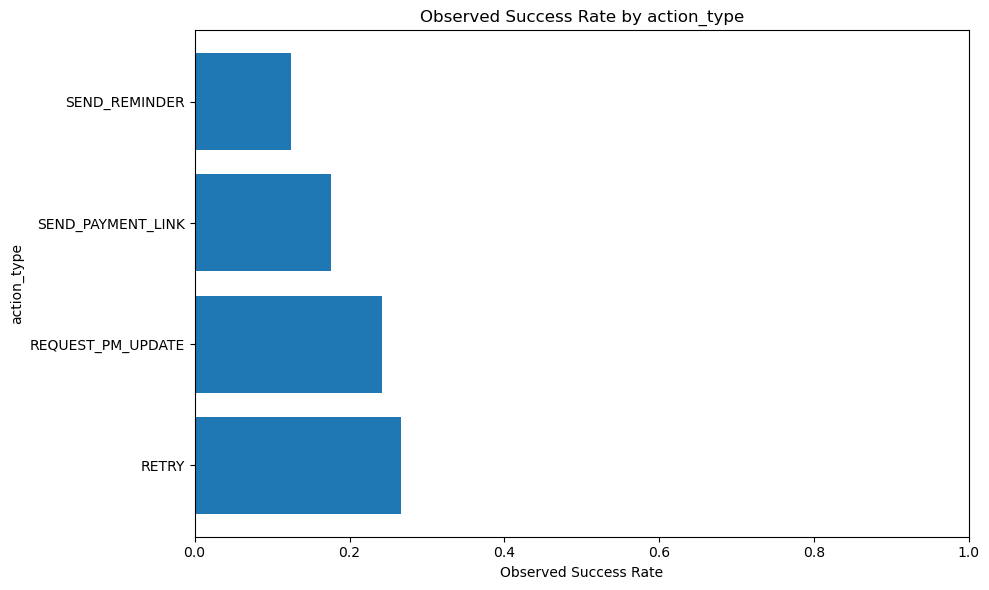

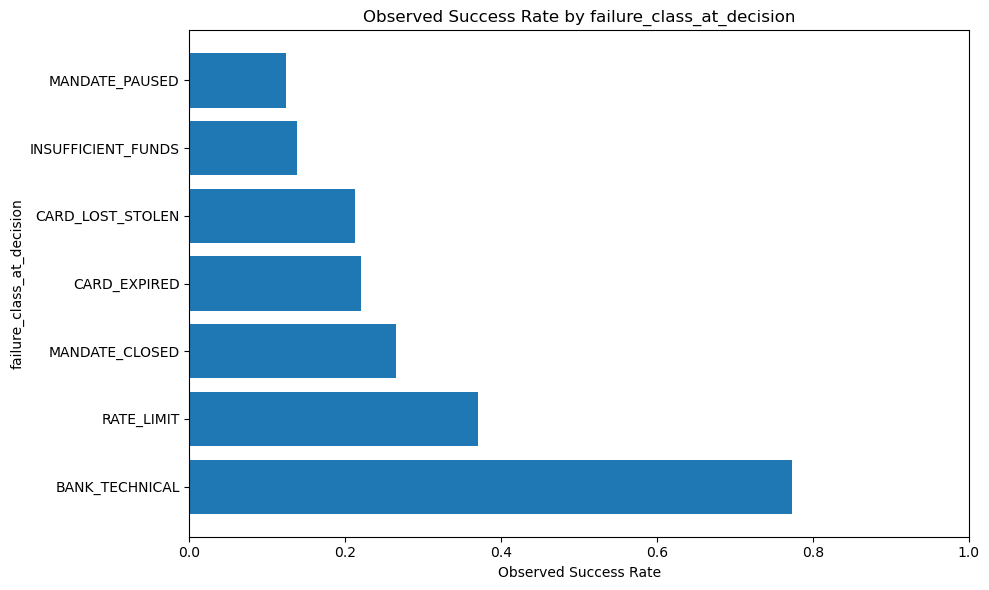

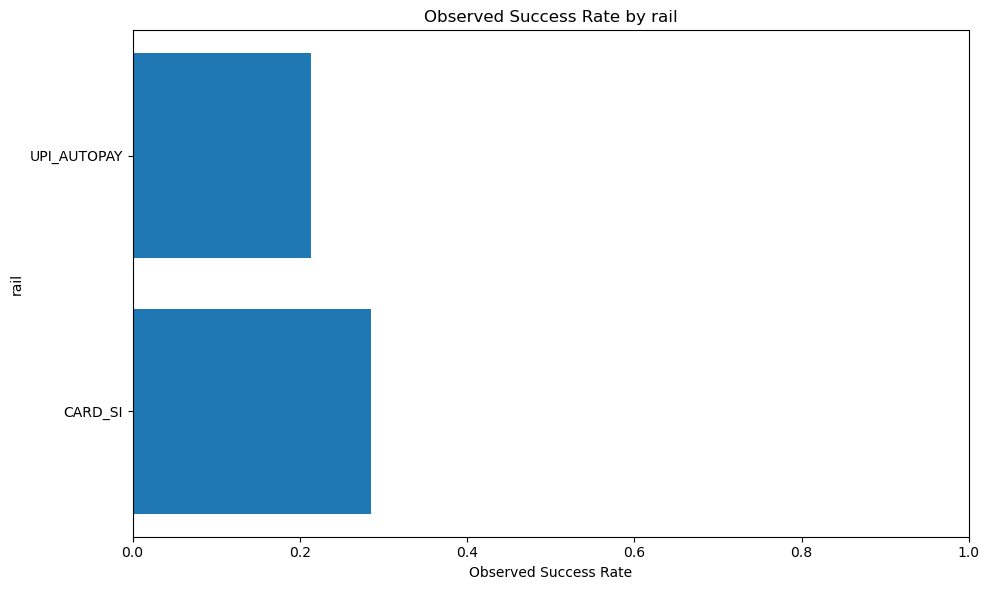

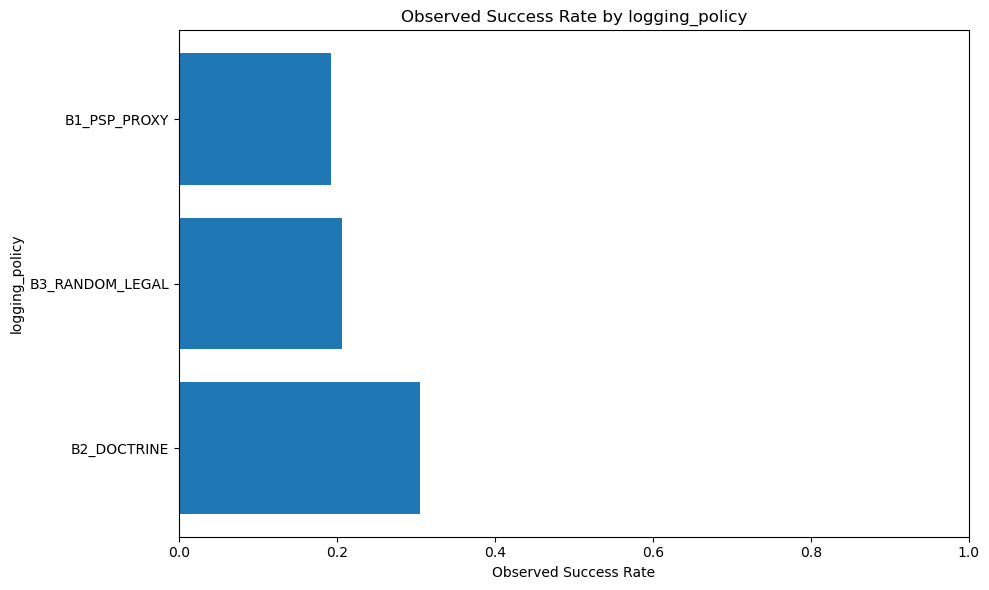

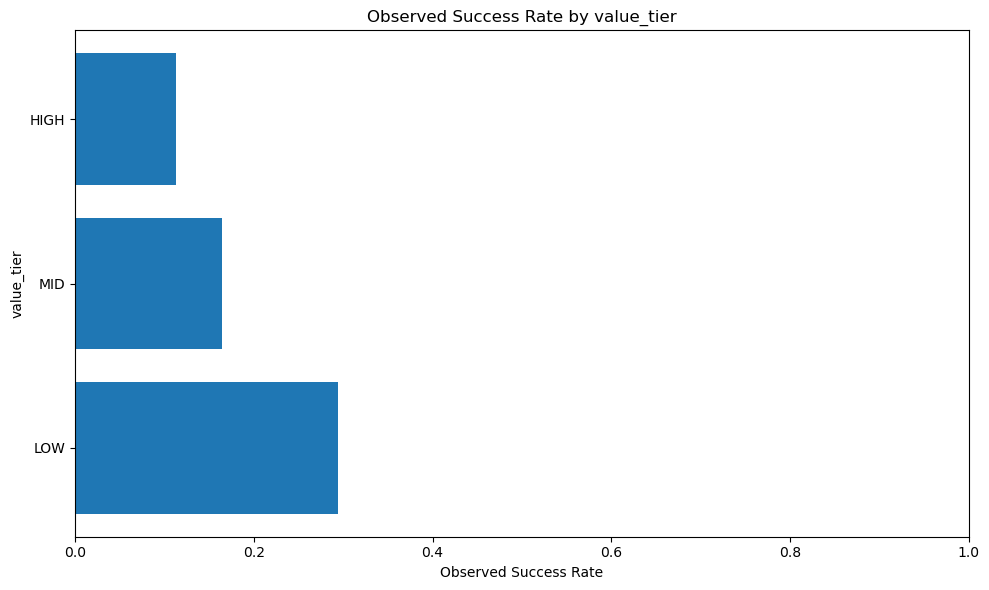

In [10]:

# Overall target
target_counts = ml[target_col].value_counts(dropna=False).sort_index()

plt.figure(figsize=(6, 4))
plt.bar(
    target_counts.index.astype(str),
    target_counts.values
)
plt.title("ML Target Distribution")
plt.xlabel(target_col)
plt.ylabel("Count")
save_show("ml_target_distribution.png")

for col, filename in [
    ("action_type", "success_by_action.png"),
    ("failure_class", "success_by_failure_class.png"),
    ("failure_class_at_decision", "success_by_failure_at_decision.png"),
    ("rail", "success_by_rail.png"),
    ("logging_policy", "success_by_policy.png"),
    ("amount_bucket", "success_by_amount_bucket.png"),
    ("value_tier", "success_by_value_tier.png"),
]:
    if col in ml.columns:
        summary = observed_success_by_category(
            ml,
            col,
            target_col,
            f"Observed Success Rate by {col}",
            filename,
            min_count=30,
            top_n=20 if col == "rail" else None,
        )
        summary.to_csv(
            REPORT_DIR / f"success_by_{col}.csv",
            index=False,
        )


## 9. Candidate Feature Distributions

This section produces graphical EDA for the candidate ML features from C0.
It separates numeric, boolean, and categorical variables.

In [11]:

candidate_path = (
    PROJECT_ROOT
    / "reports"
    / "ml_contract"
    / "candidate_features.csv"
)

if not candidate_path.exists():
    raise FileNotFoundError(
        f"Missing C0 candidate feature file: {candidate_path}"
    )

candidates = pd.read_csv(candidate_path)

candidate_cols = [
    c for c in candidates["column"].dropna().unique()
    if c in ml.columns
]

numeric_candidates = []
categorical_candidates = []

for col in candidate_cols:
    s = ml[col]

    if (
        pd.api.types.is_numeric_dtype(s)
        and not pd.api.types.is_bool_dtype(s)
    ):
        numeric_candidates.append(col)
    else:
        categorical_candidates.append(col)

print("Numeric candidates:", numeric_candidates)
print("Categorical/binary candidates:", categorical_candidates)


Numeric candidates: ['amount_inr', 'subscription_age_days', 'sub_billing_day', 'decision_seq', 'retries_used_before', 'contacts_sent_before', 'hours_since_open', 'customer_tenure_days', 'prior_cycles_seen', 'prior_successes', 'prior_success_rate', 'prior_failed_cases_before', 'prior_recovered_cases_before', 'day_of_month', 'day_of_week', 'hour_of_day', 'hours_to_next_cluster_slot', 'salary_day_proxy_dom']
Categorical/binary candidates: ['rail', 'bank_name', 'segment', 'plan_tier', 'value_tier', 'failure_class_at_decision', 'first_failure_class', 'instrument_fixed', 'age_band', 'state', 'locale_pref', 'in_salary_cluster', 'action_type', 'channel']


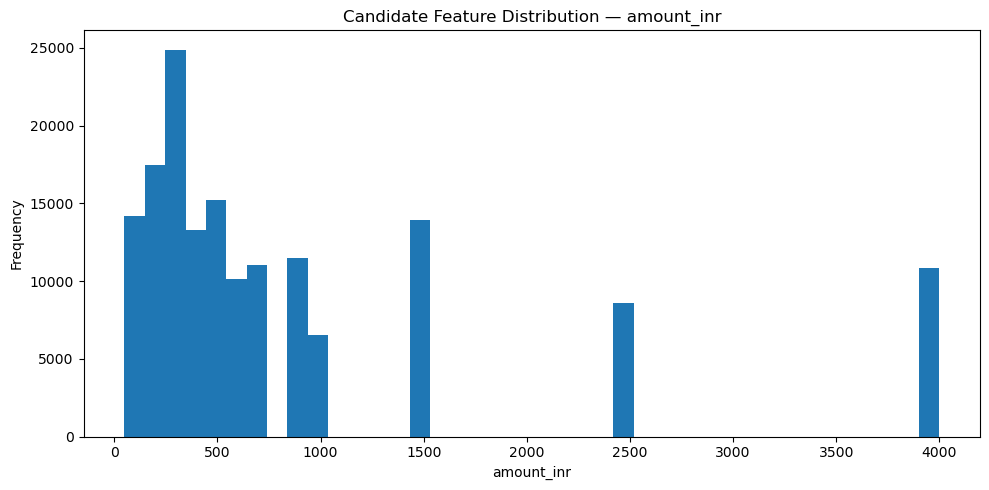

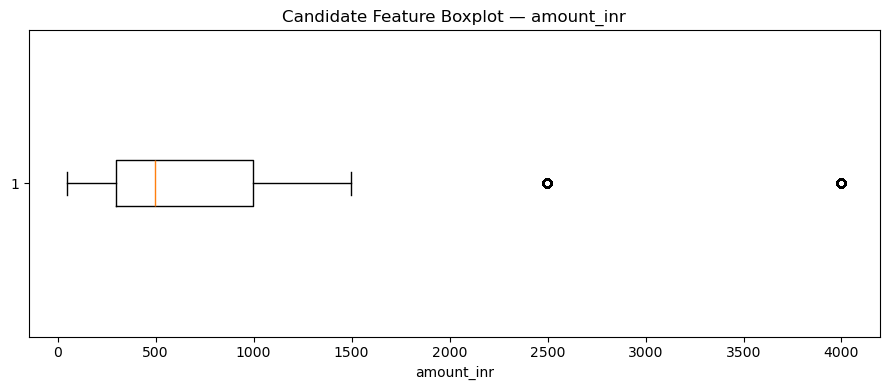

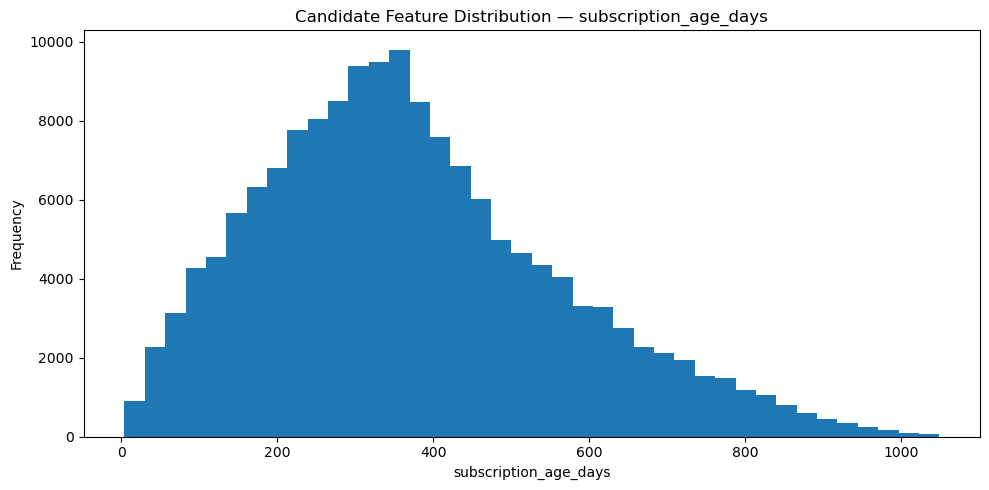

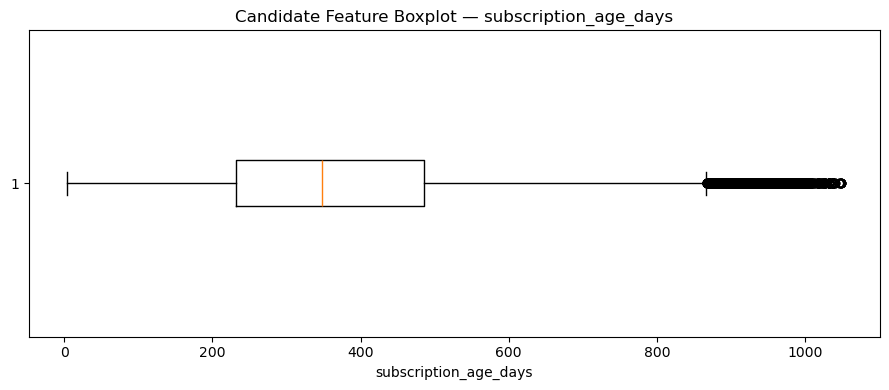

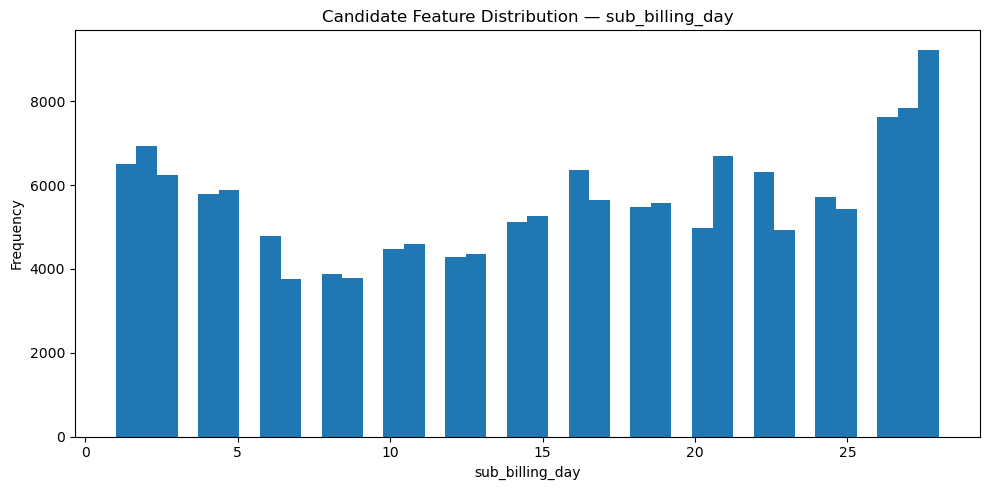

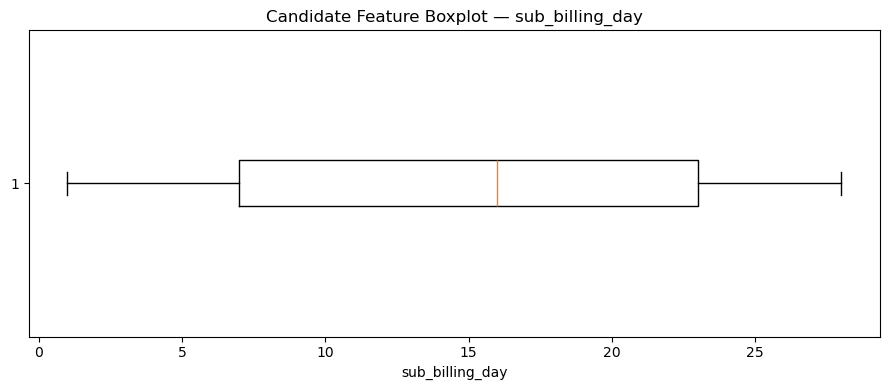

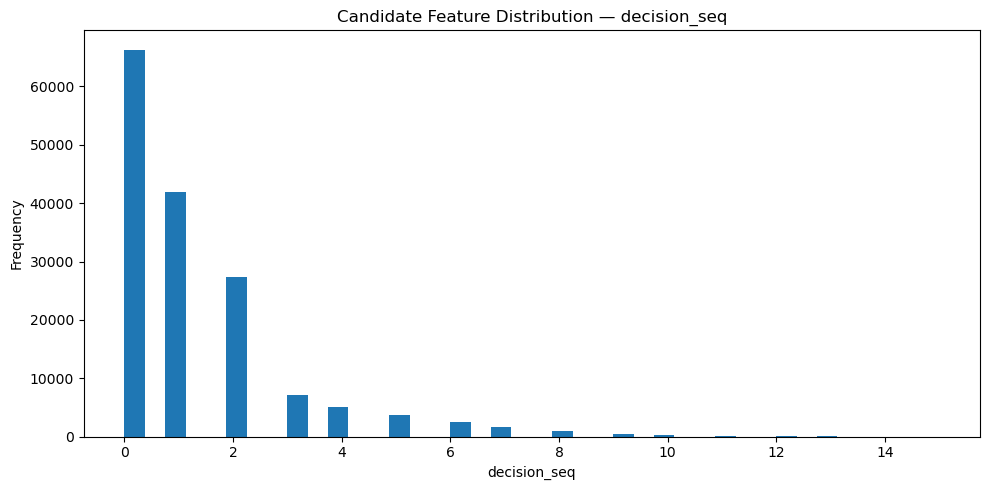

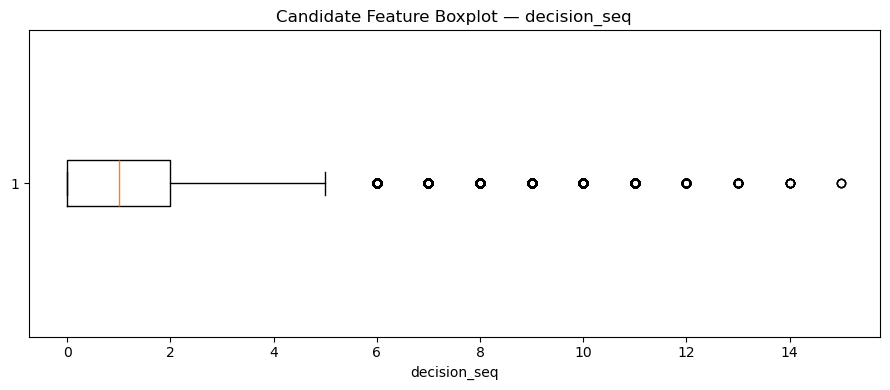

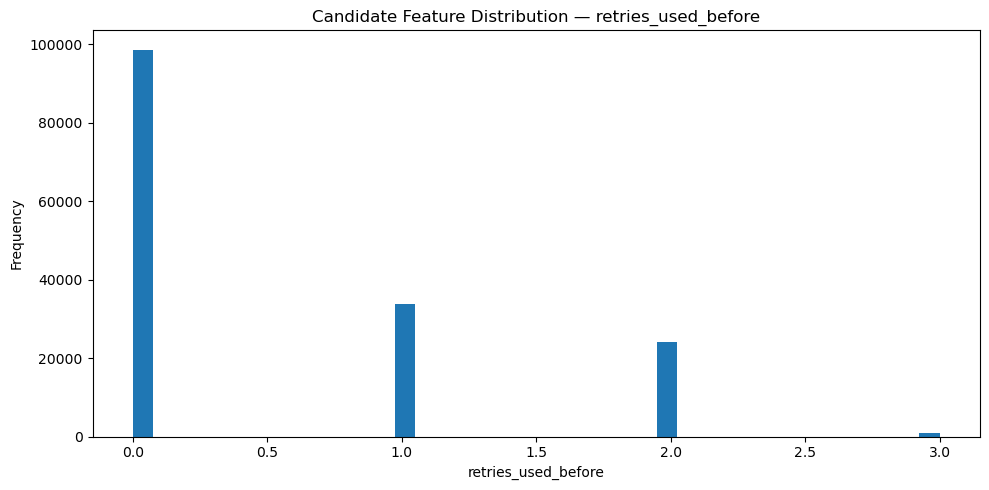

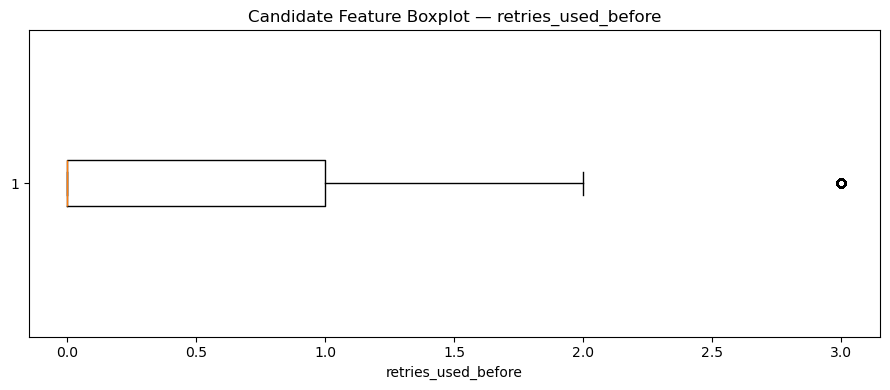

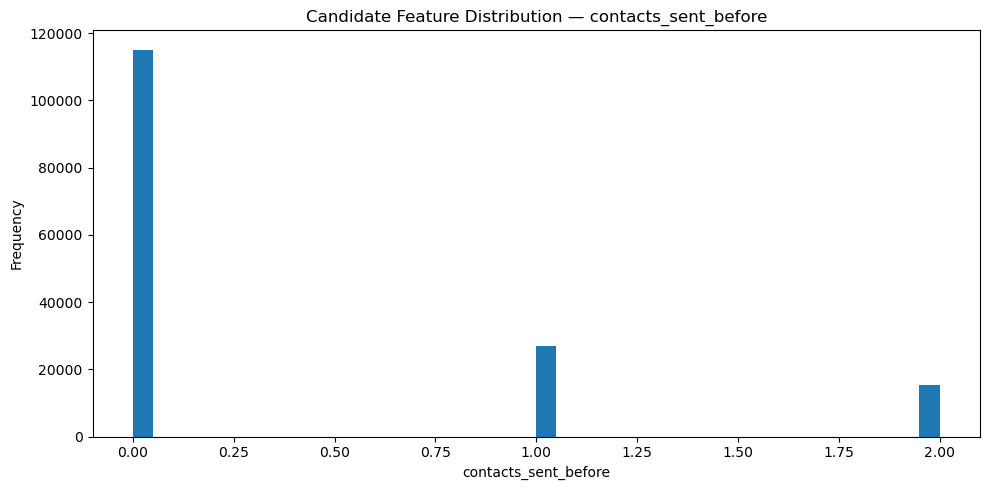

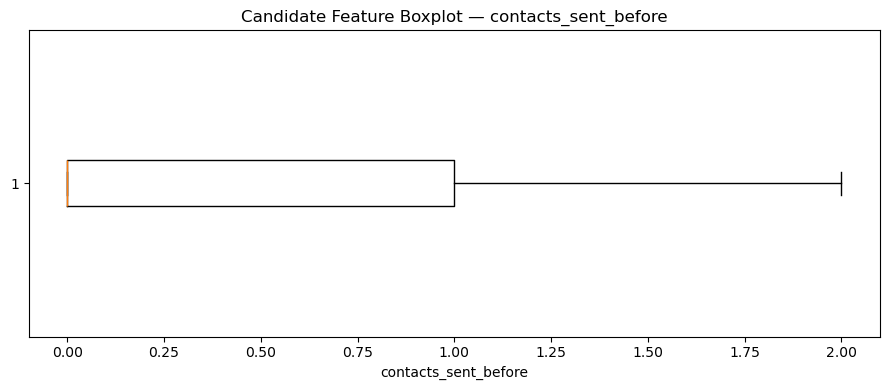

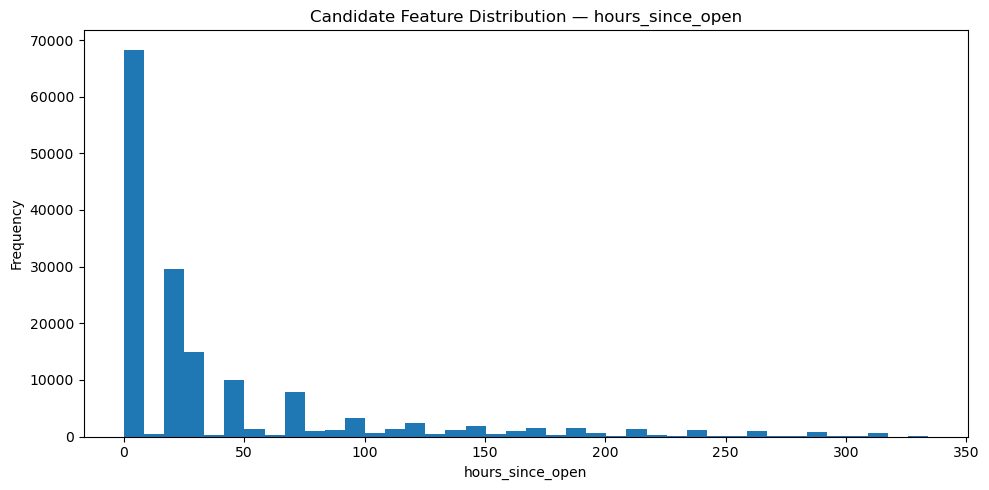

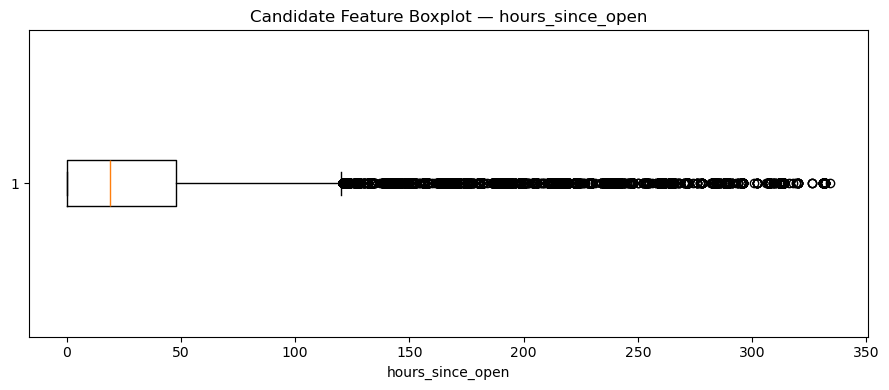

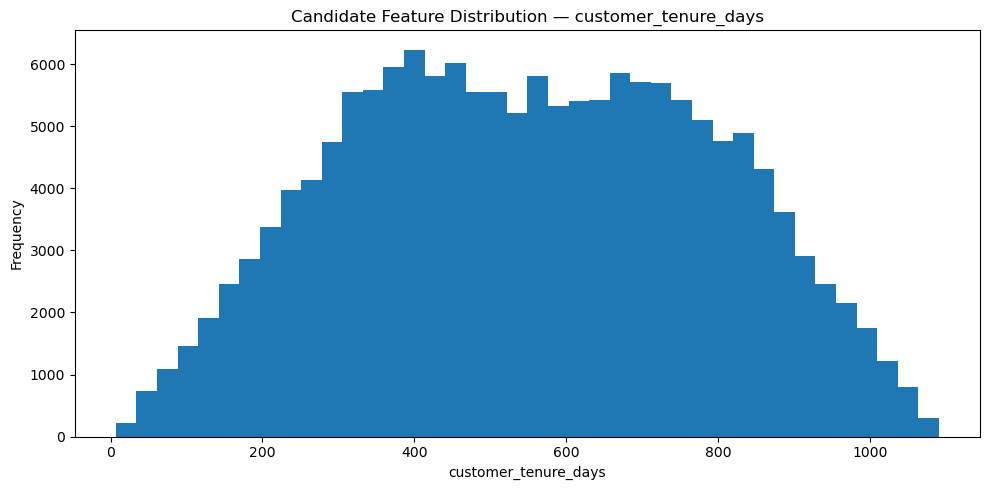

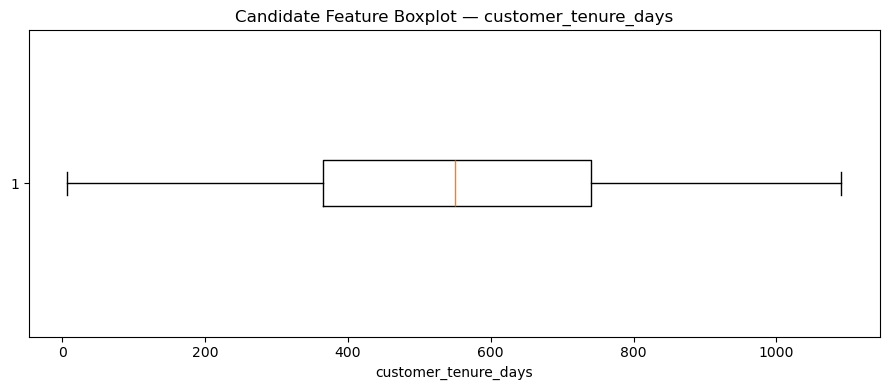

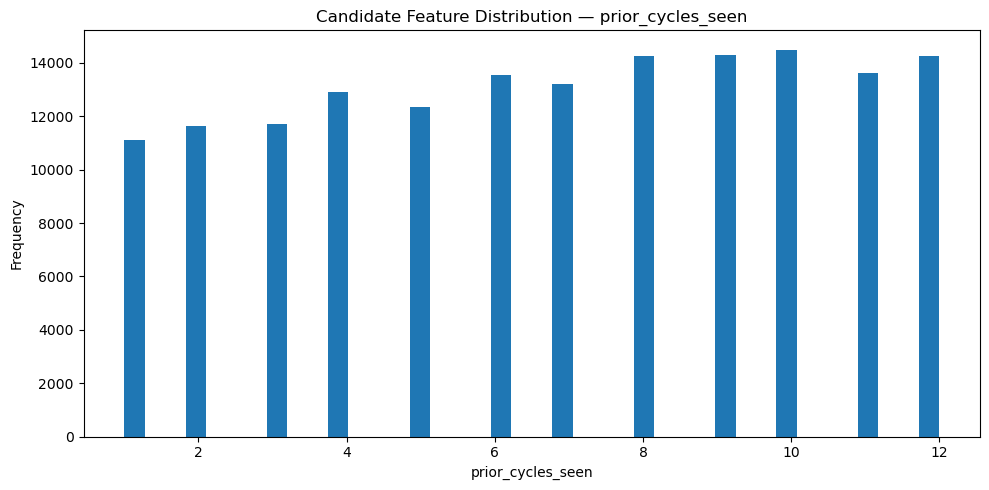

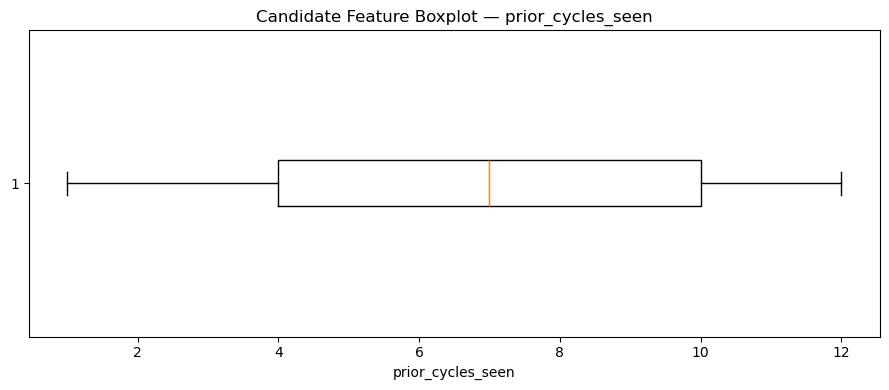

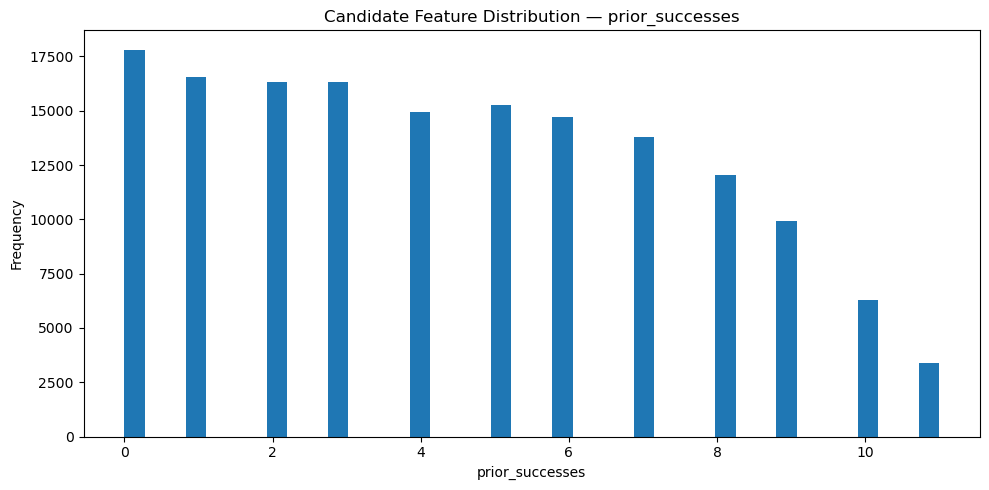

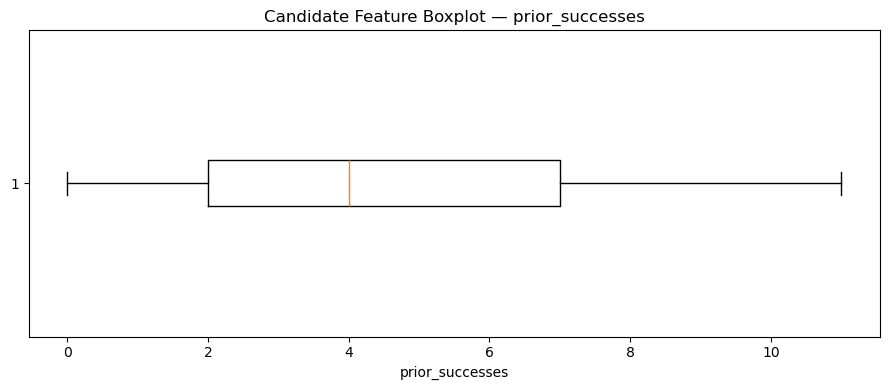

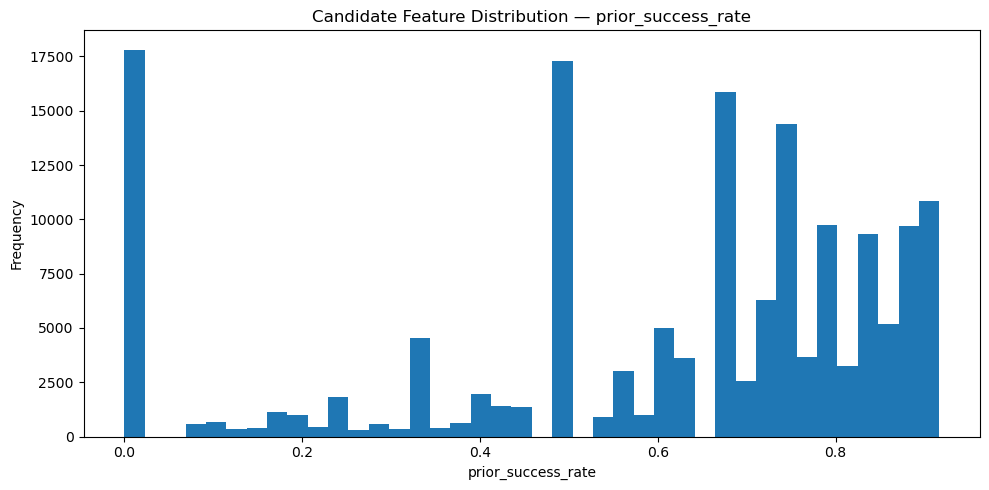

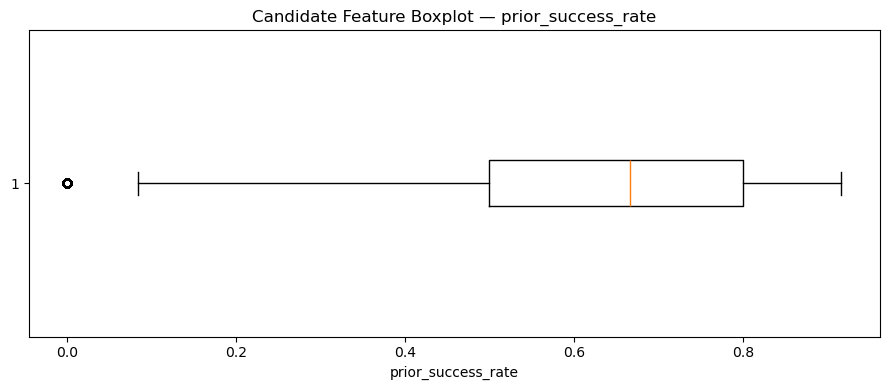

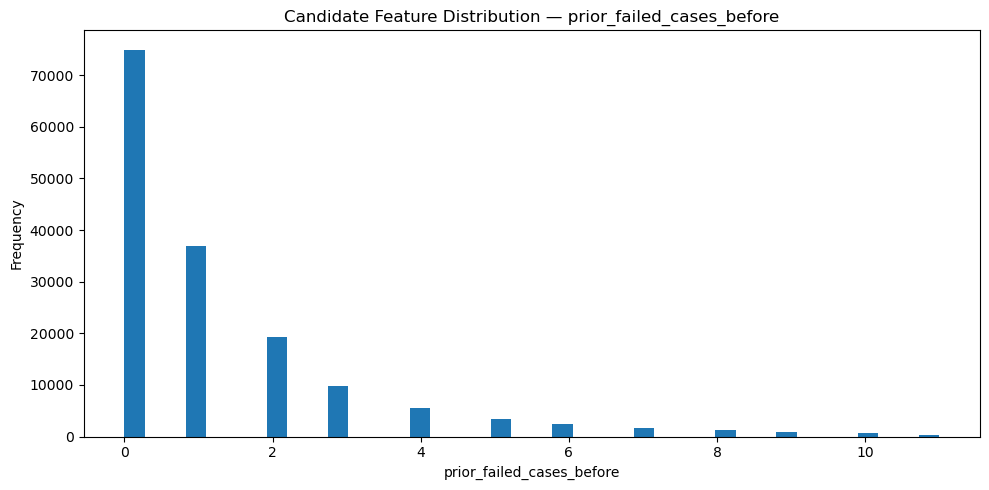

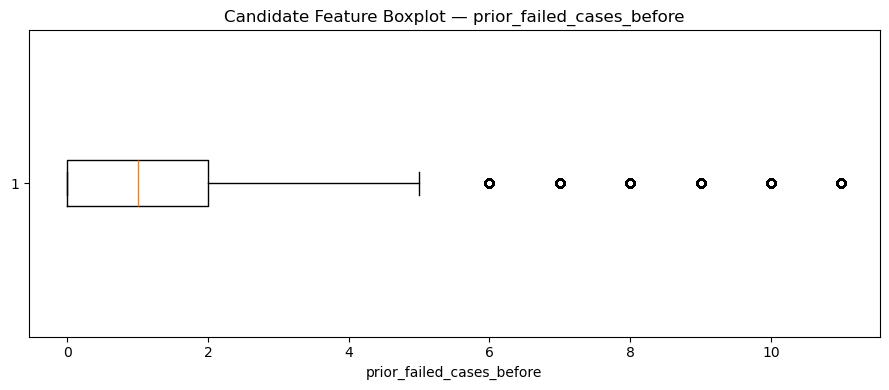

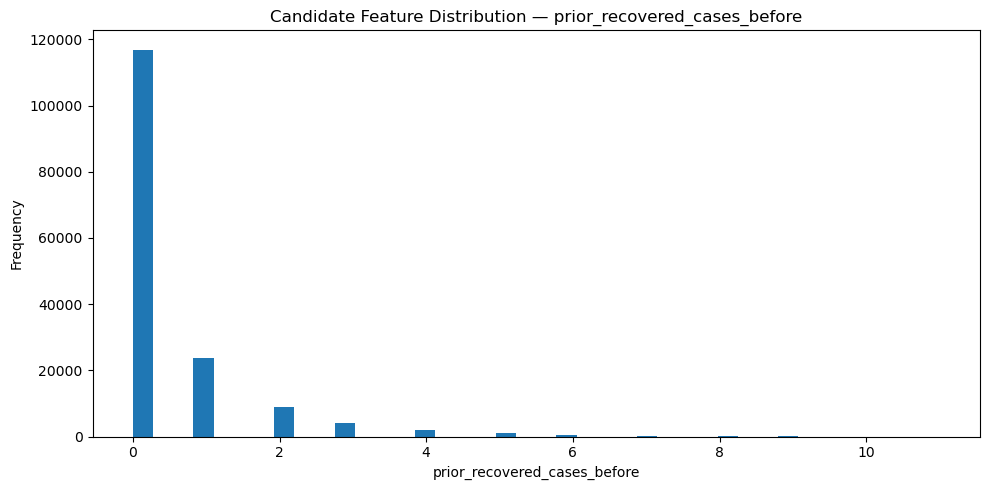

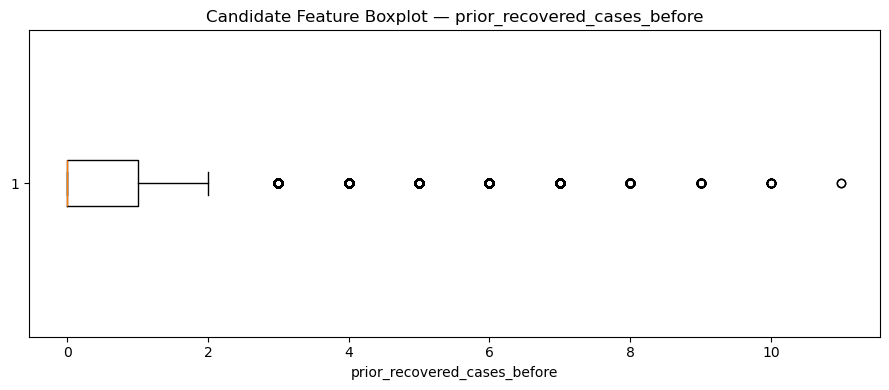

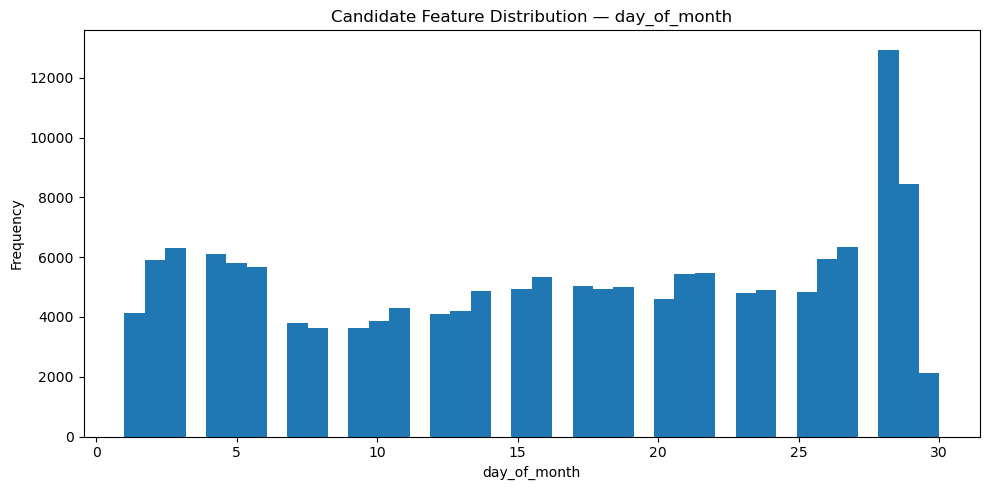

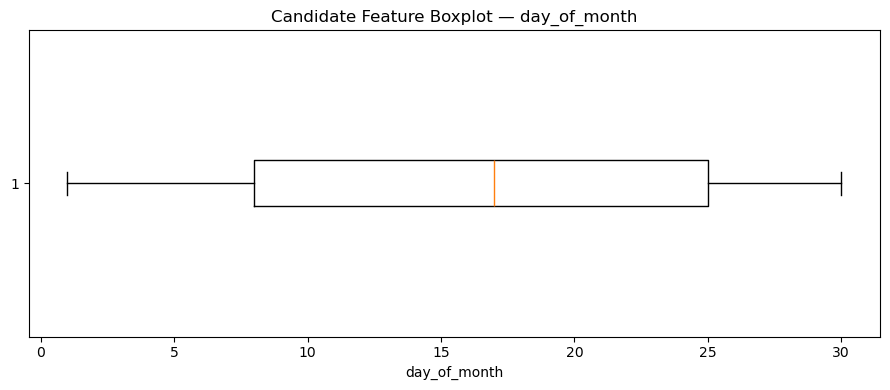

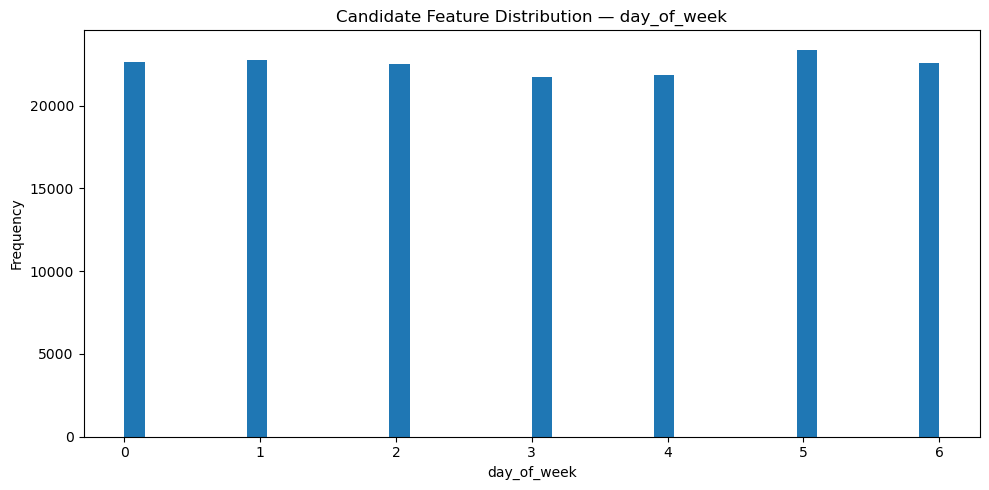

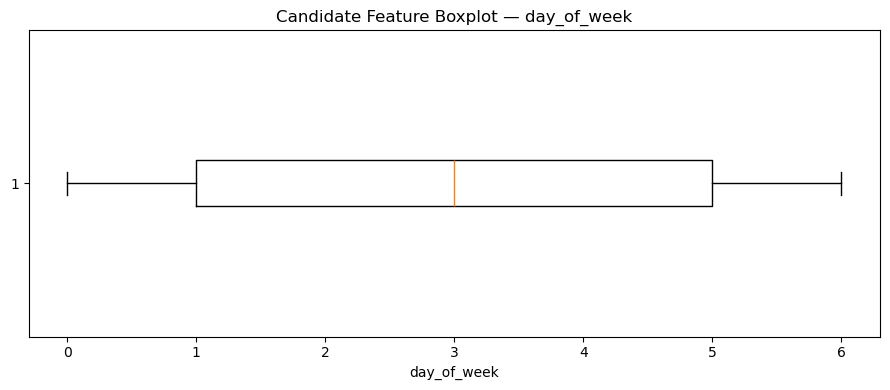

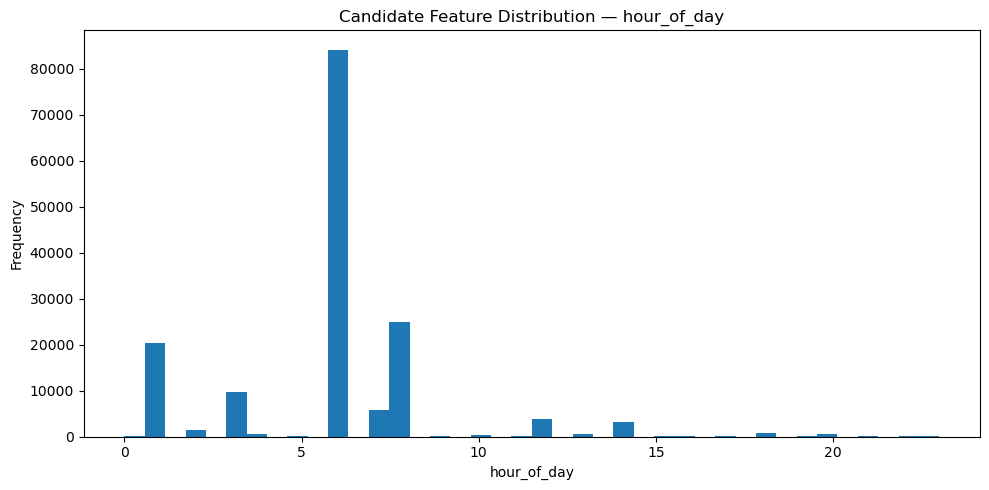

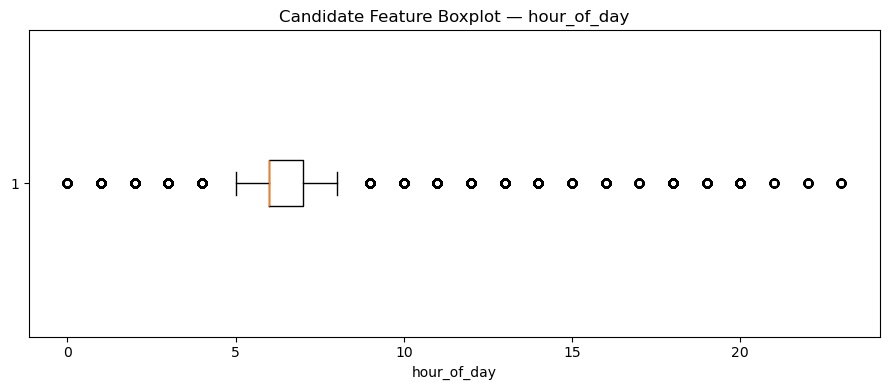

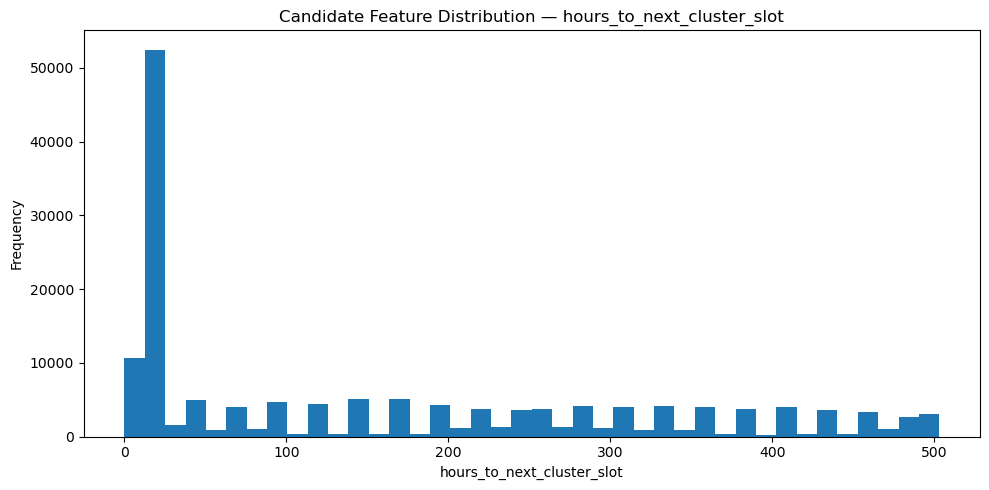

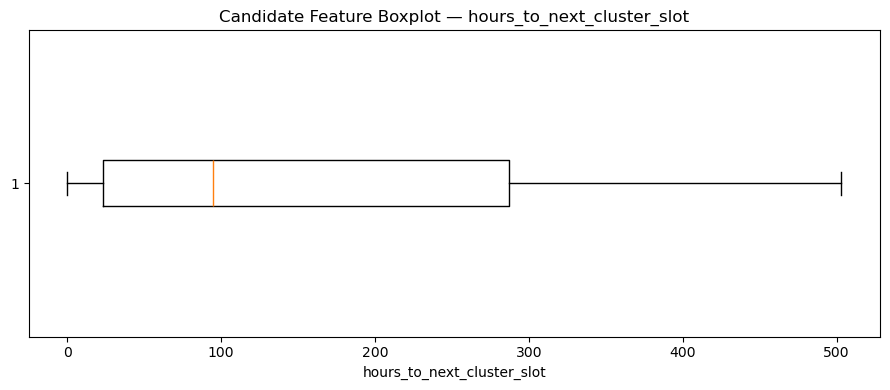

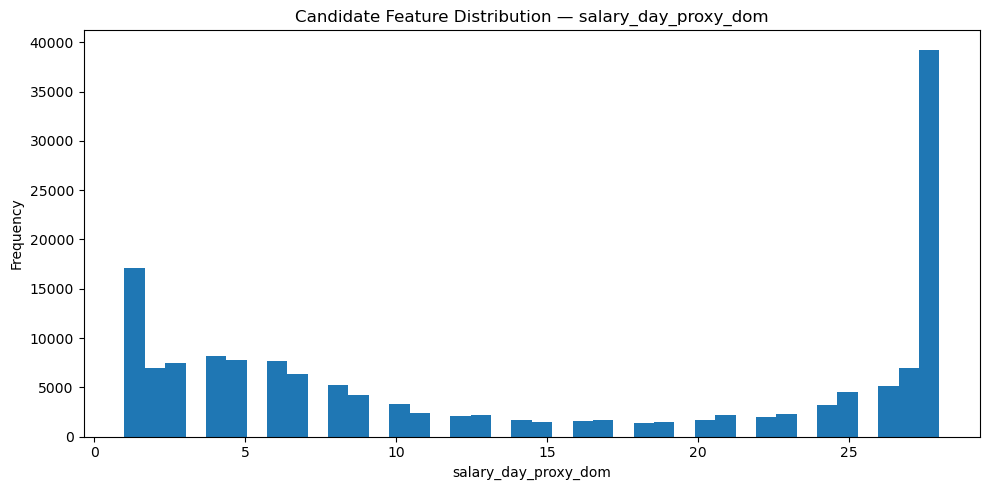

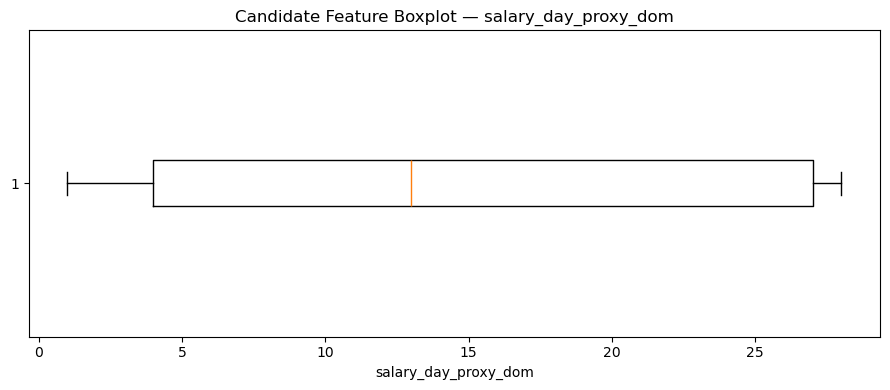

In [12]:

# Numeric candidate distributions
for col in numeric_candidates:

    plot_numeric_hist(
        ml[col],
        f"Candidate Feature Distribution — {col}",
        f"feature_{col}_hist.png",
        bins=40,
        log_x=False,
    )

    plot_box(
        ml[col],
        f"Candidate Feature Boxplot — {col}",
        f"feature_{col}_box.png",
    )


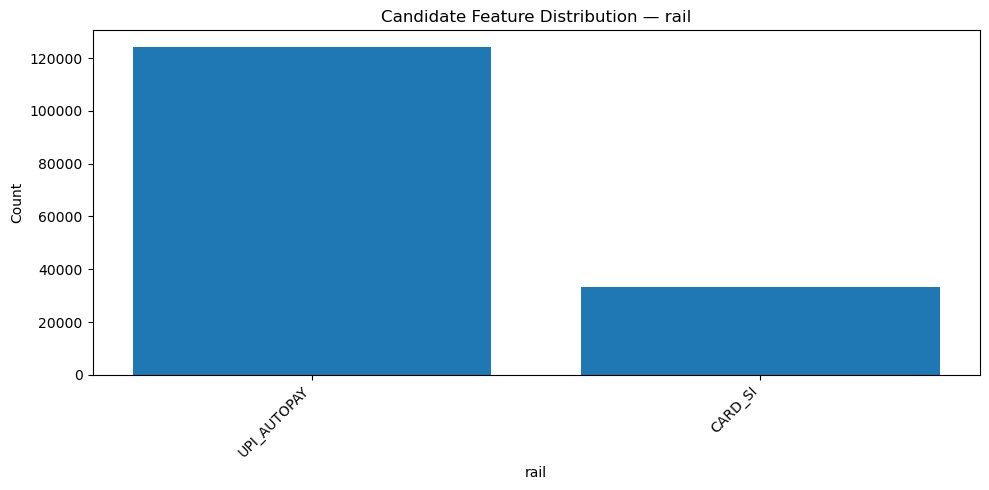

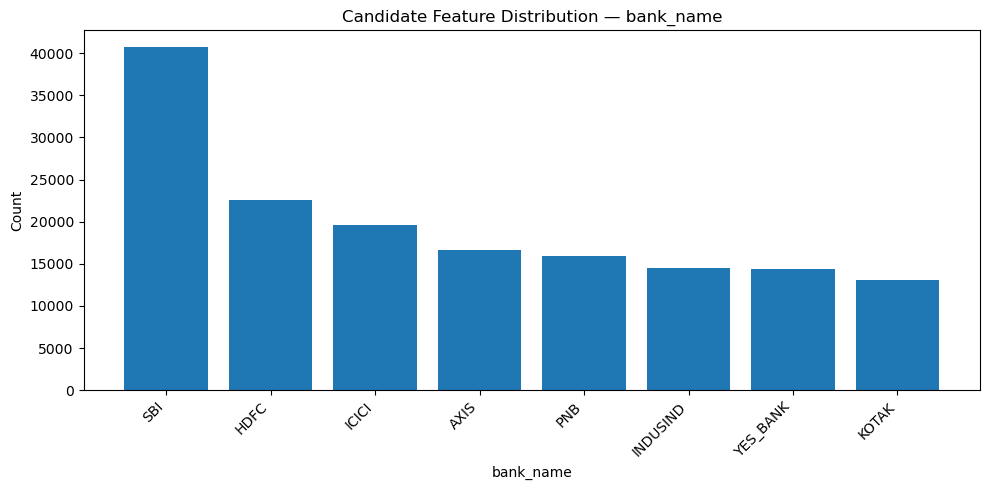

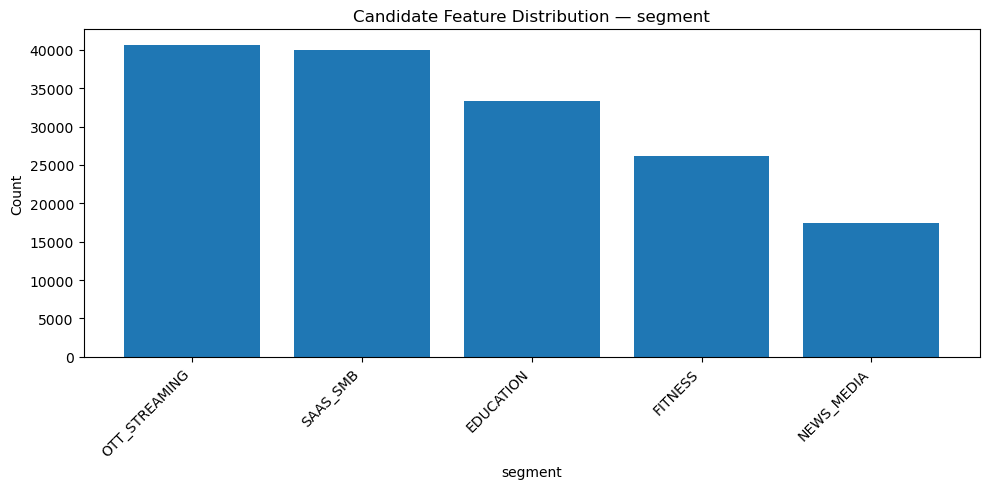

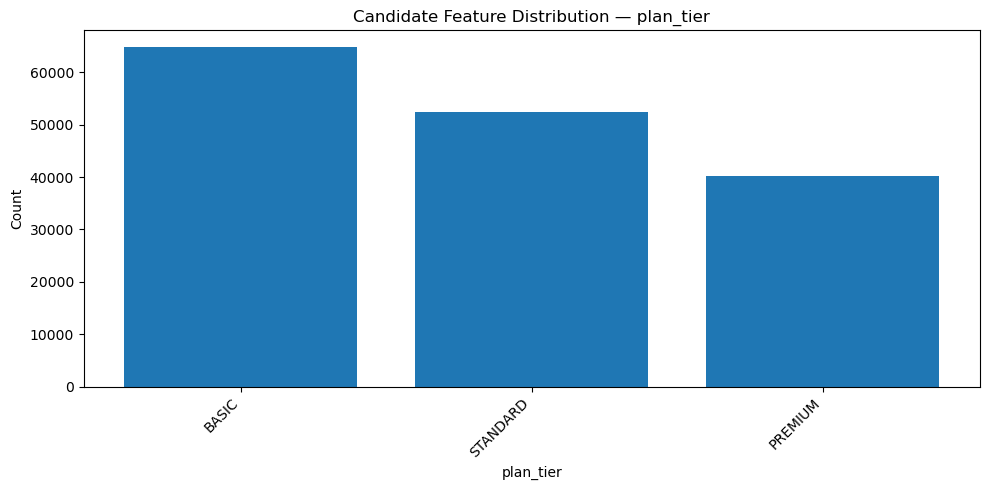

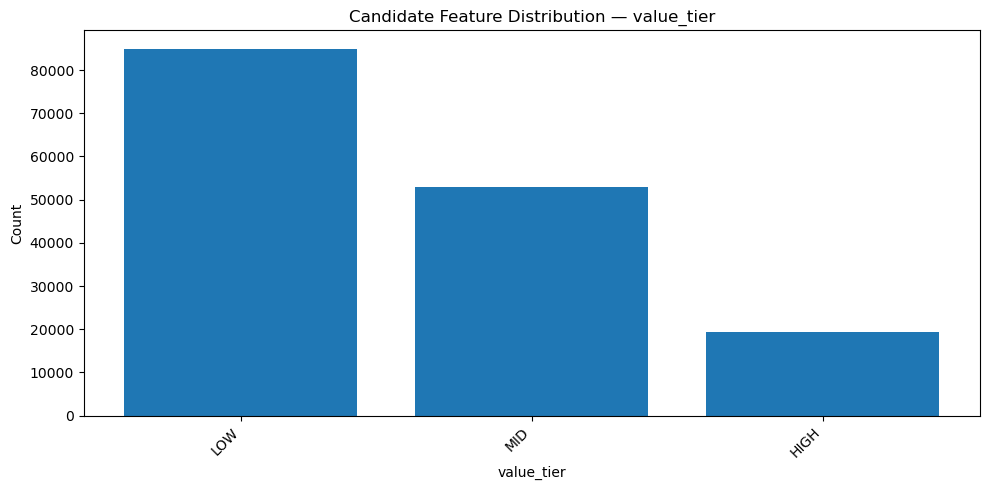

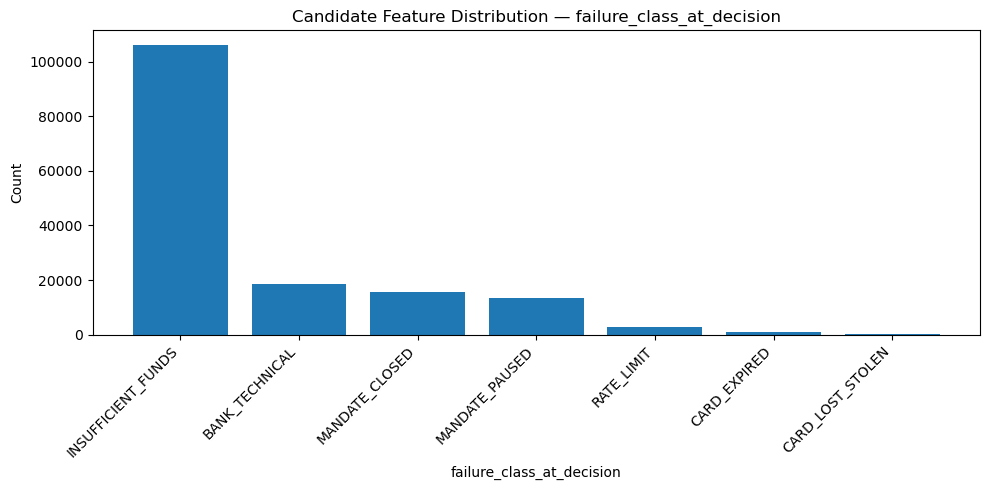

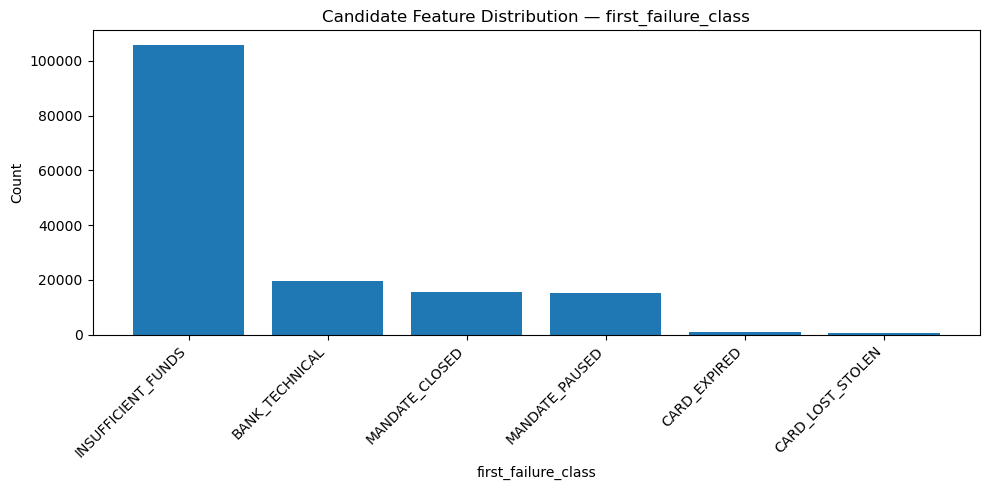

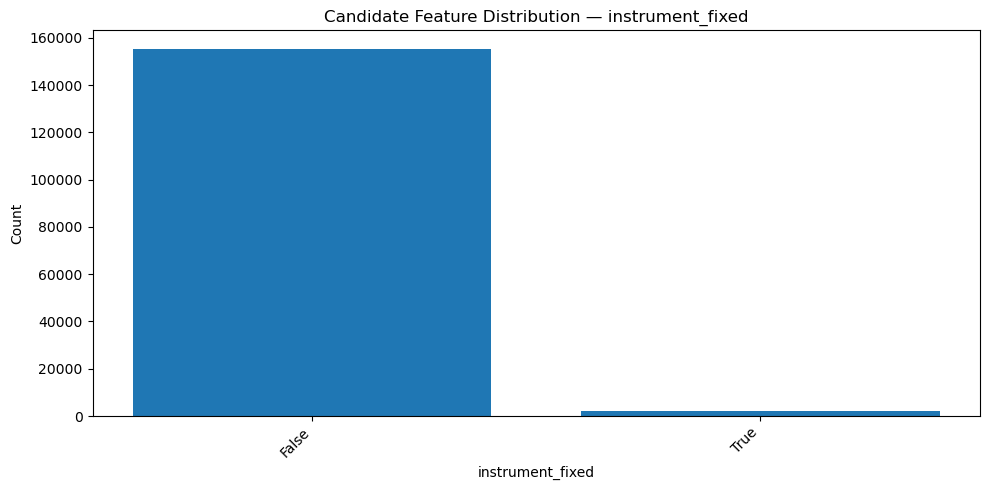

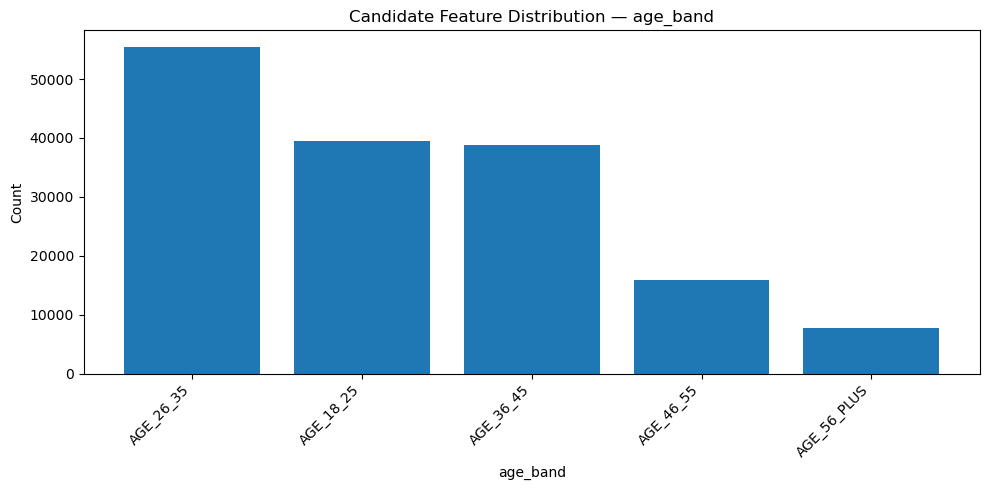

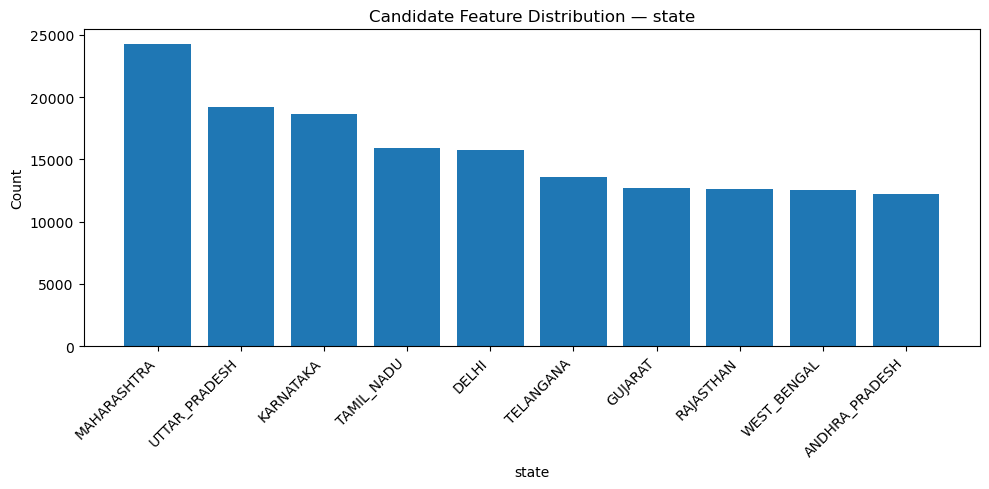

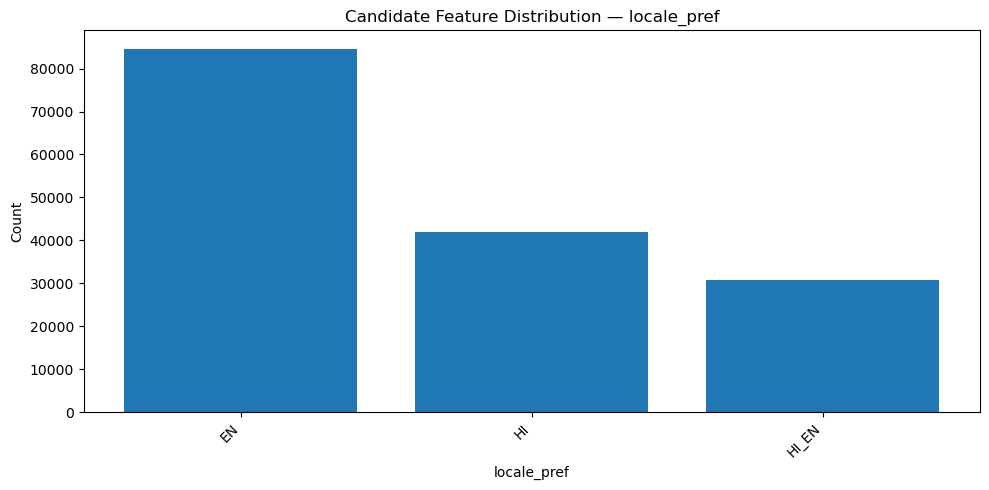

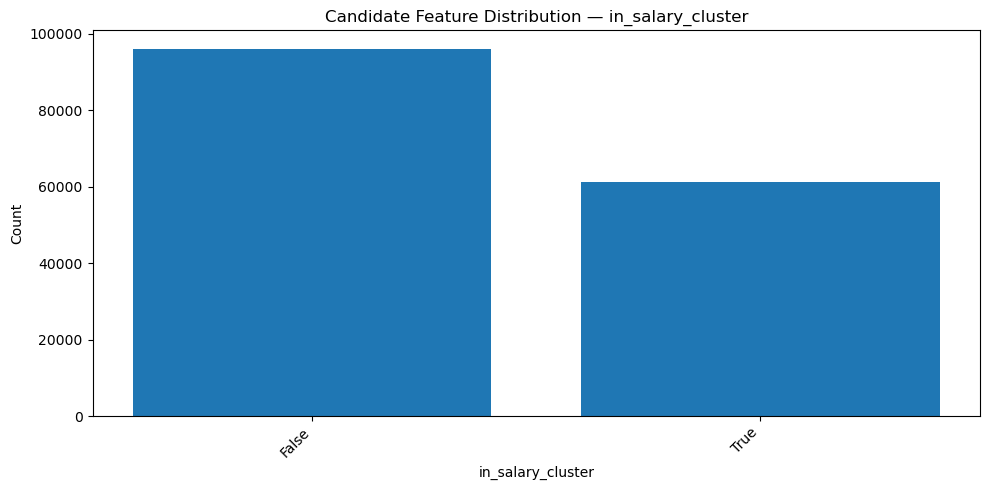

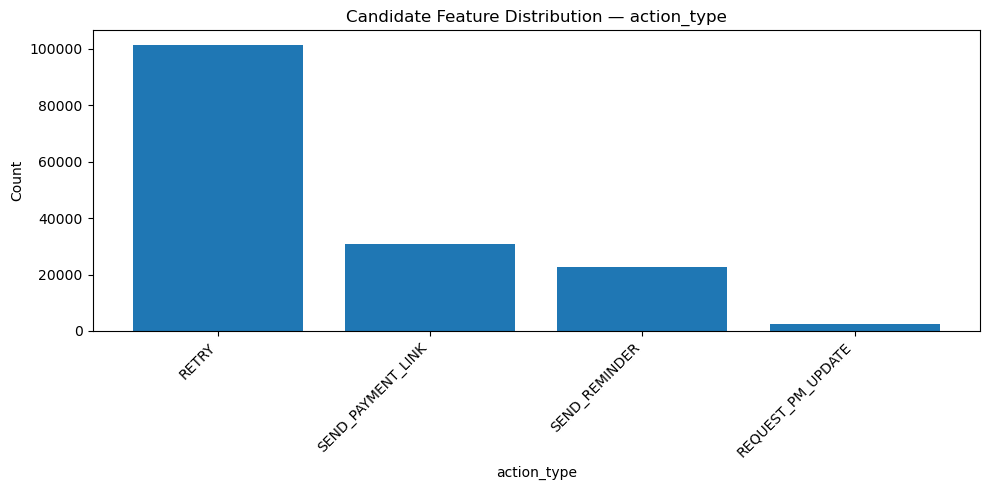

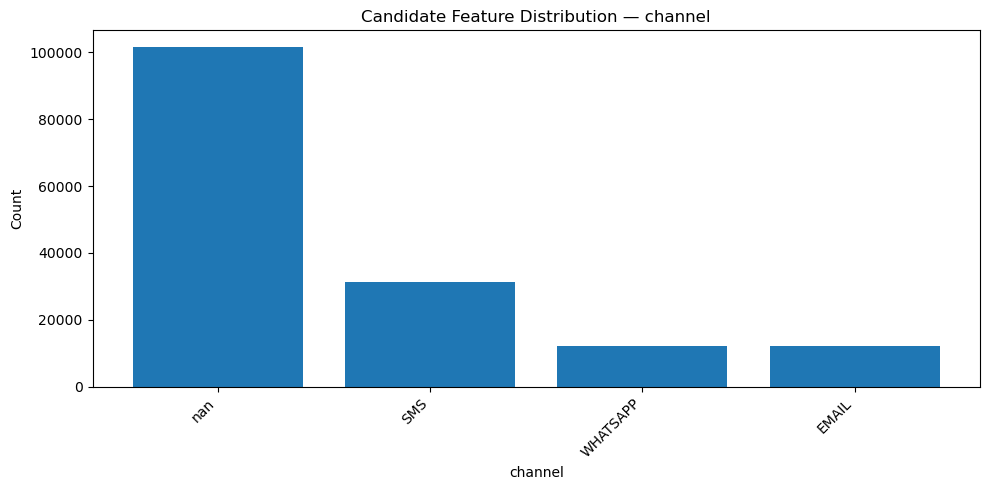

In [13]:

# Categorical / binary candidate distributions
for col in categorical_candidates:

    s = ml[col]

    counts = (
        s.value_counts(dropna=False)
        .head(20)
    )

    plt.figure(figsize=(10, 5))
    plt.bar(
        counts.index.astype(str),
        counts.values
    )
    plt.title(
        f"Candidate Feature Distribution — {col}"
    )
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(
        rotation=45,
        ha="right"
    )
    save_show(
        f"feature_{col}_categories.png"
    )


## 10. Feature × Target Graphical Analysis

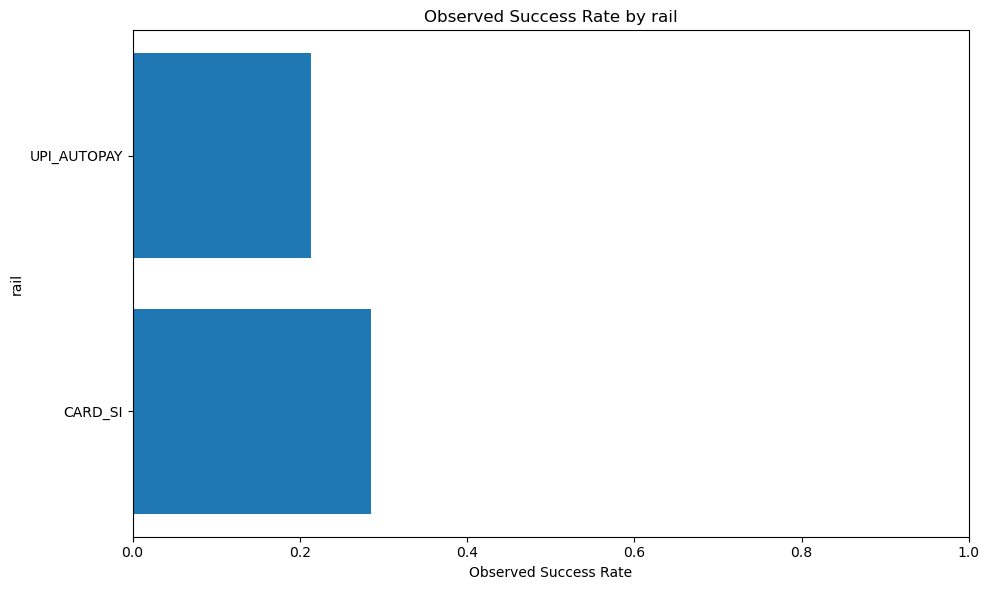

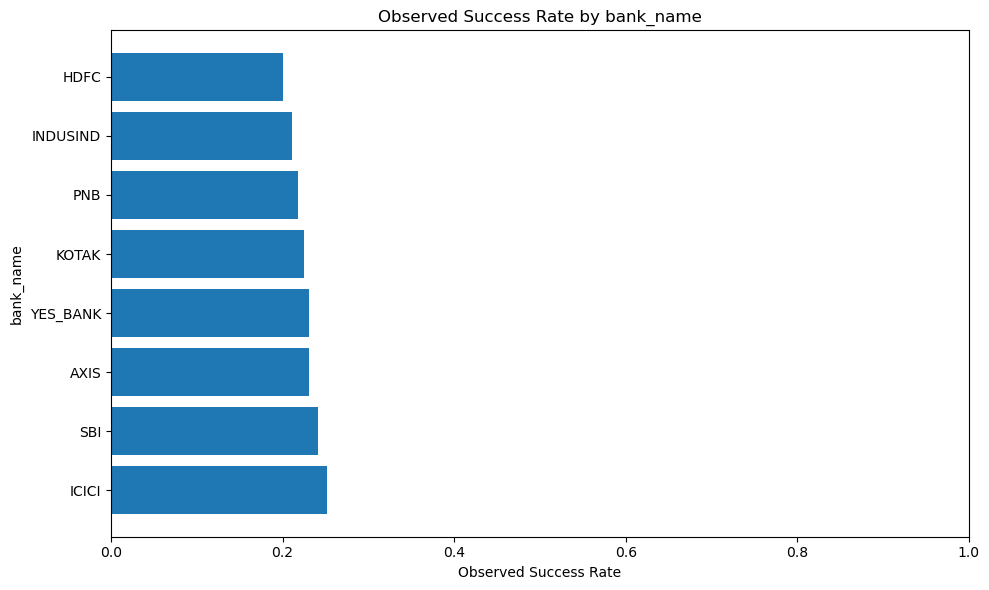

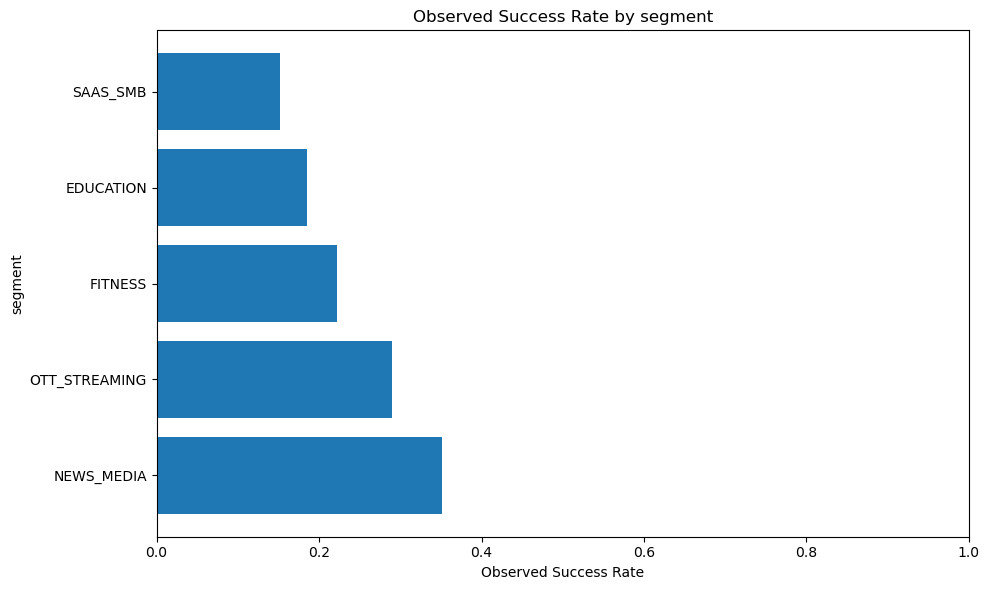

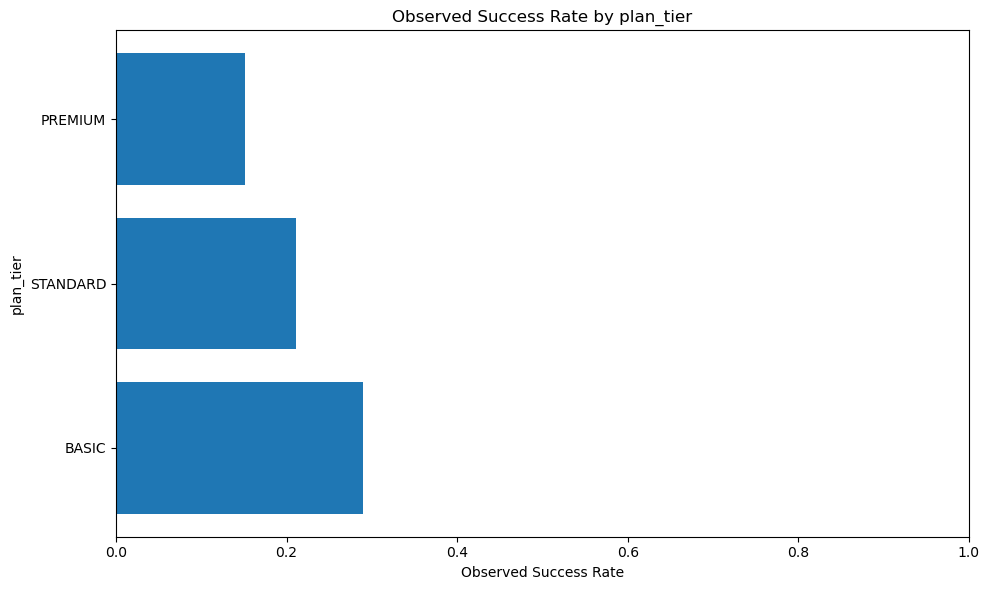

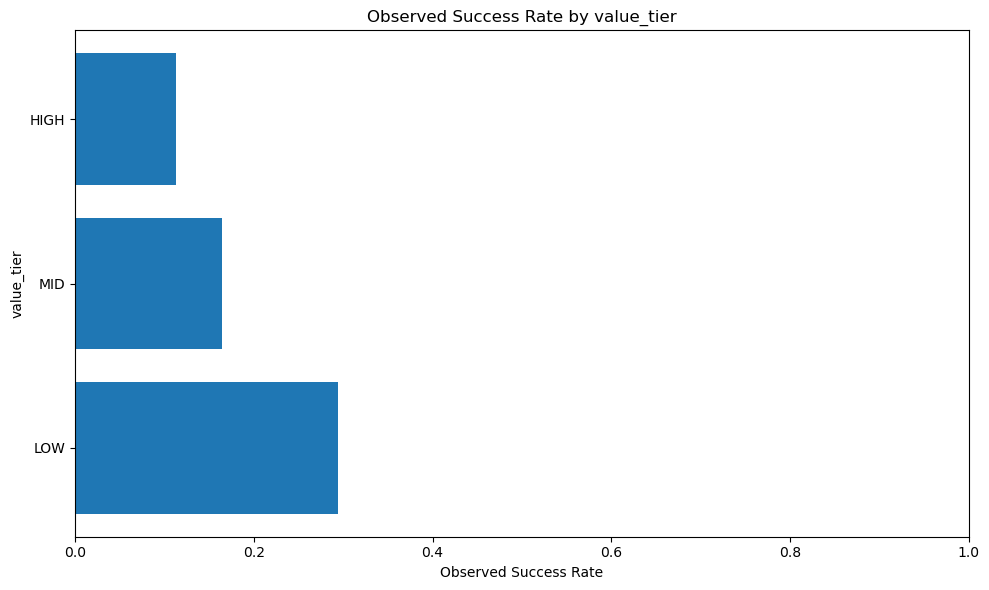

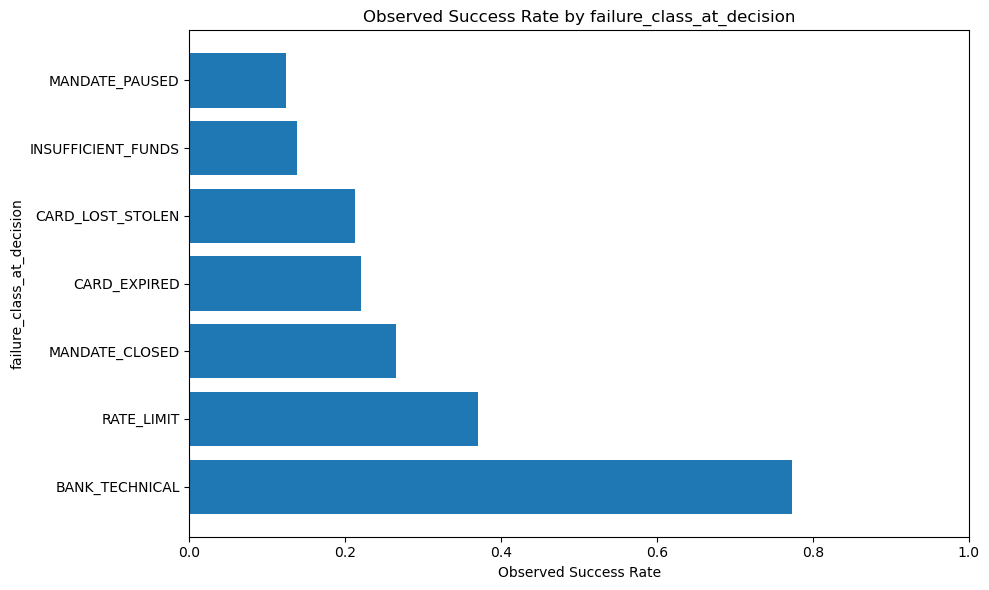

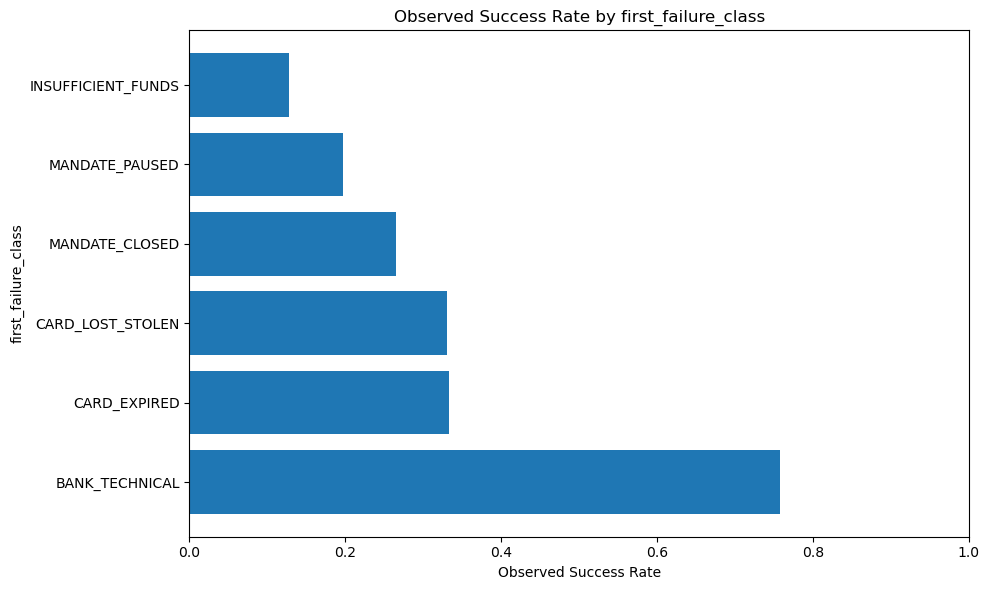

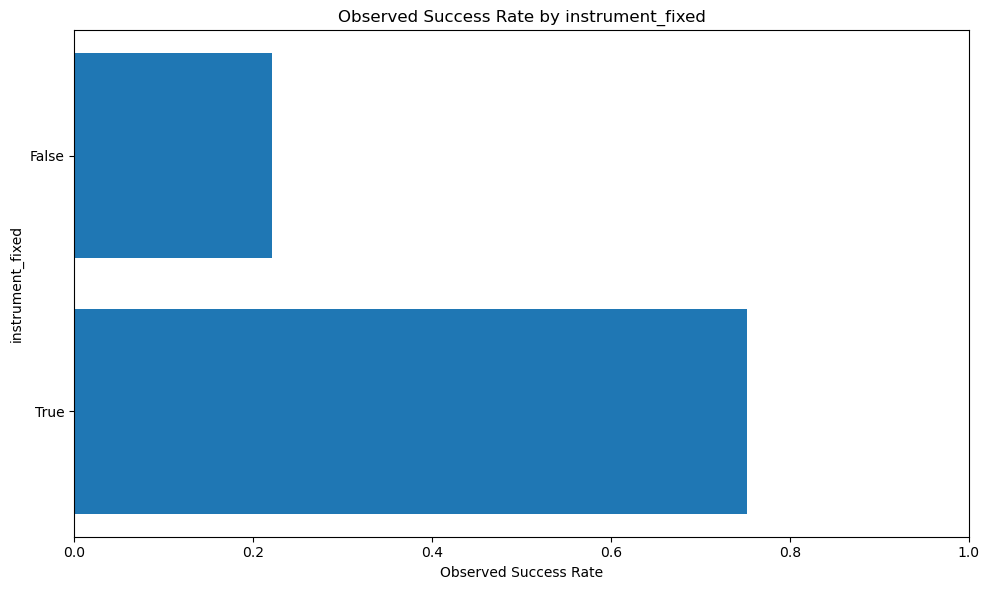

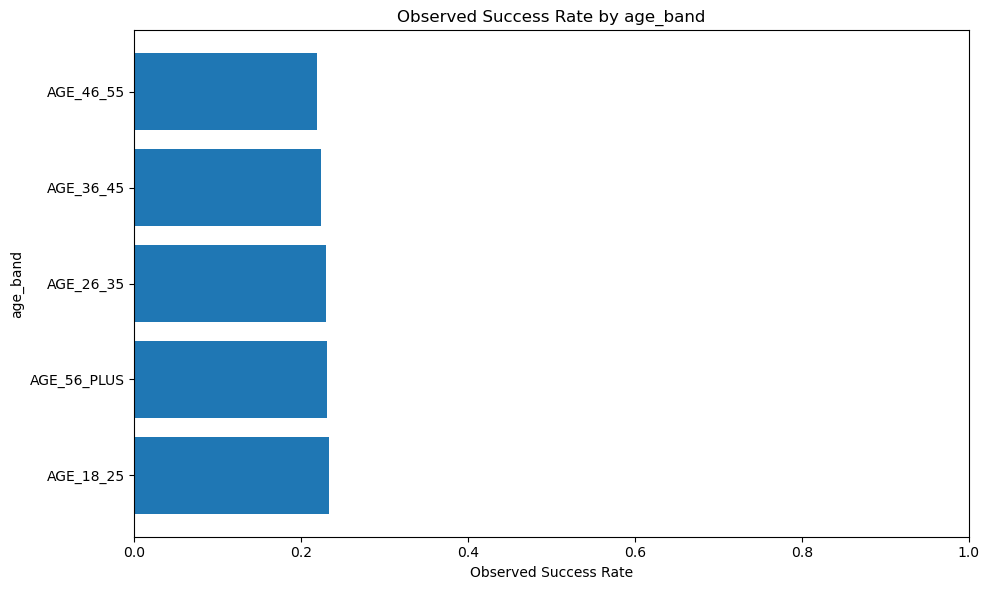

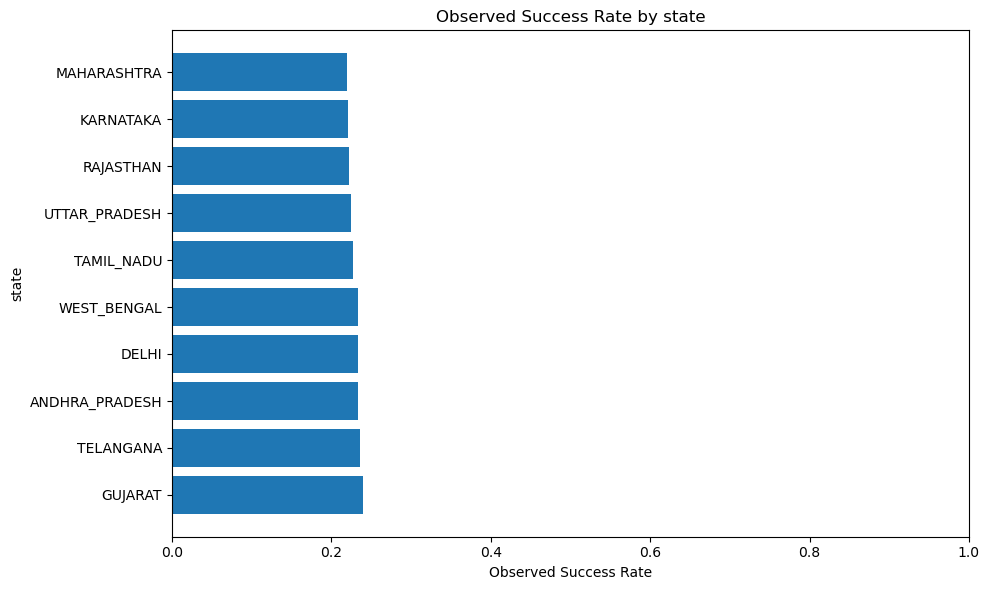

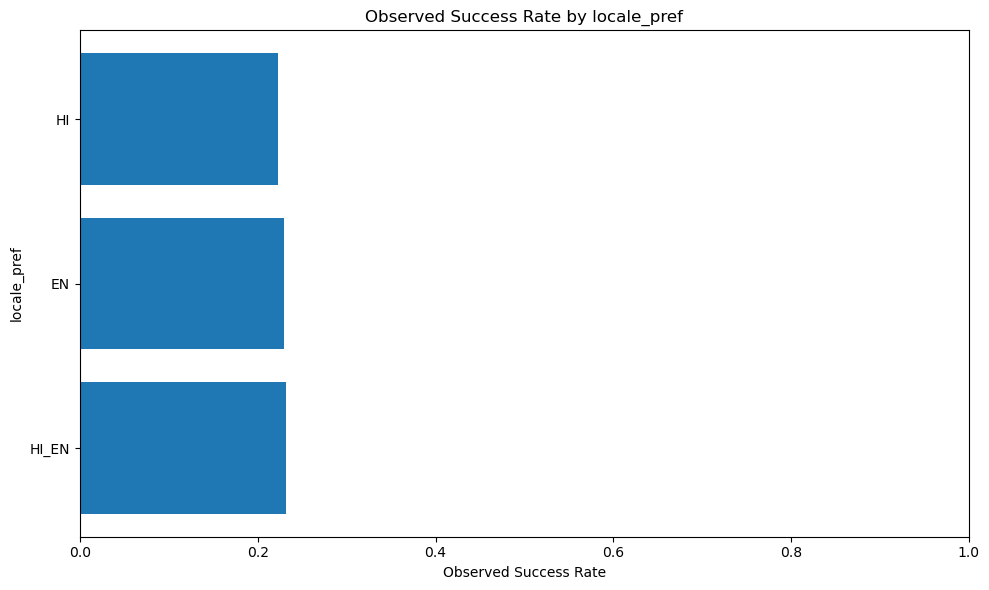

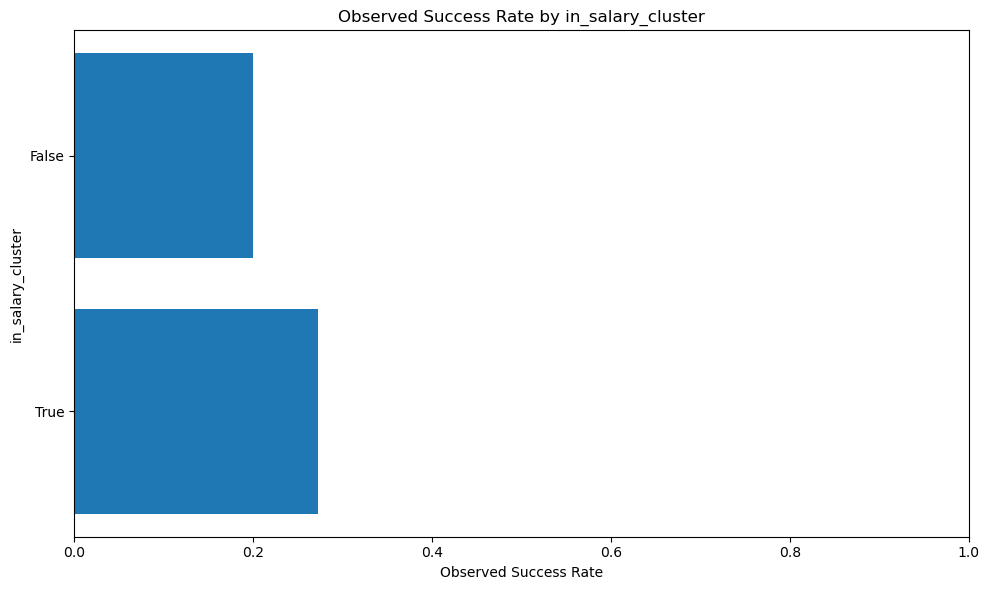

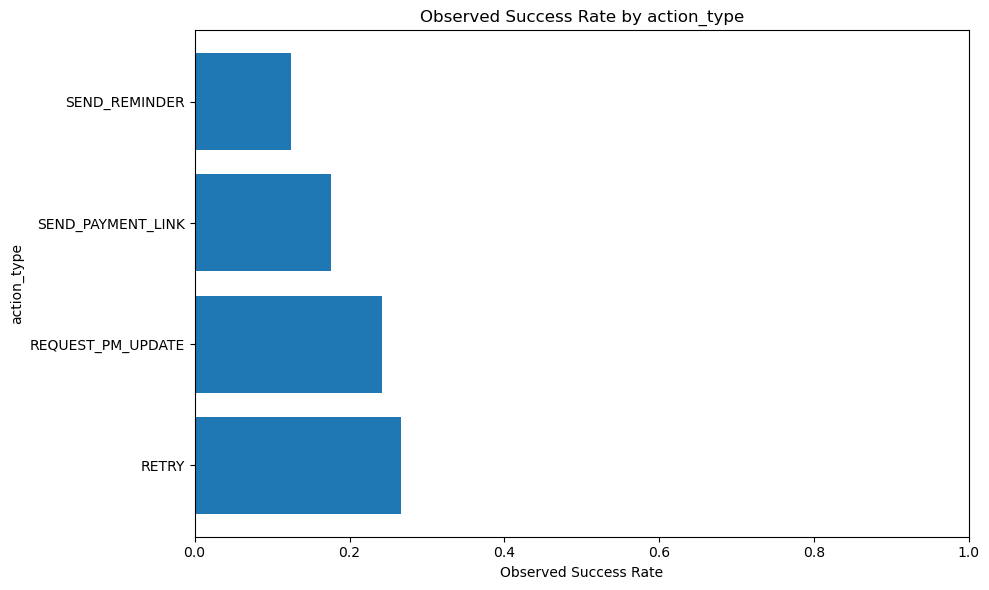

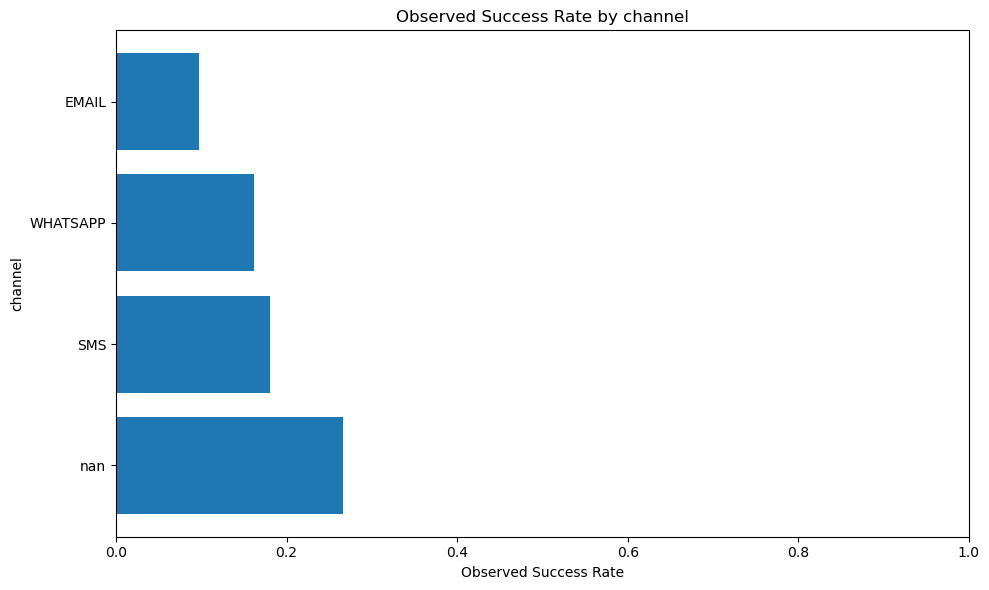

In [14]:

# Categorical/binary features: observed success by category
for col in categorical_candidates:

    if col == target_col:
        continue

    summary = (
        ml.groupby(col, dropna=False)[target_col]
        .agg(
            observations="size",
            observed_success_rate="mean",
        )
        .reset_index()
    )

    summary = summary[
        summary["observations"] >= 30
    ].sort_values(
        "observed_success_rate",
        ascending=False,
    )

    if len(summary) >= 2:

        plt.figure(figsize=(10, 6))
        plt.barh(
            summary[col].astype(str),
            summary["observed_success_rate"]
        )
        plt.xlim(0, 1)
        plt.xlabel("Observed Success Rate")
        plt.ylabel(col)
        plt.title(
            f"Observed Success Rate by {col}"
        )
        save_show(
            f"feature_target_{col}.png"
        )


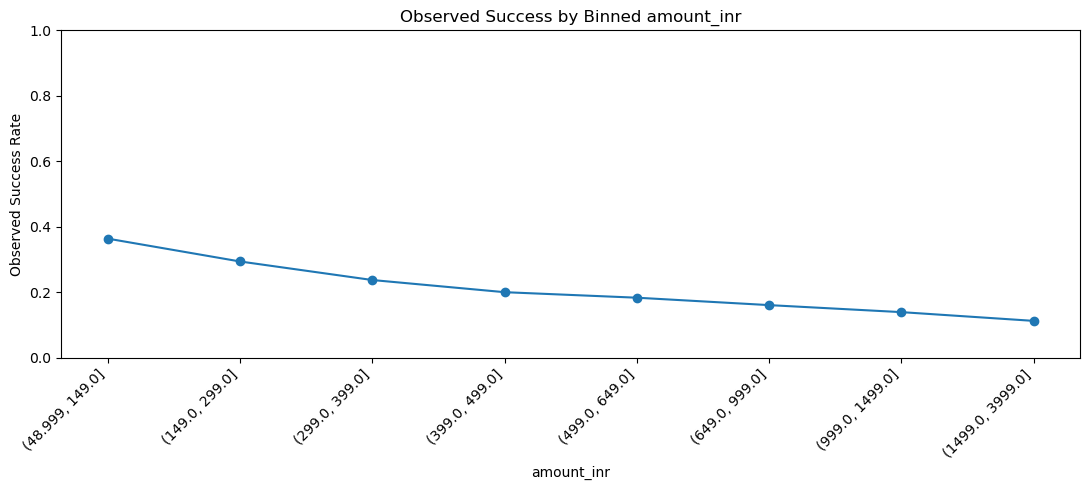

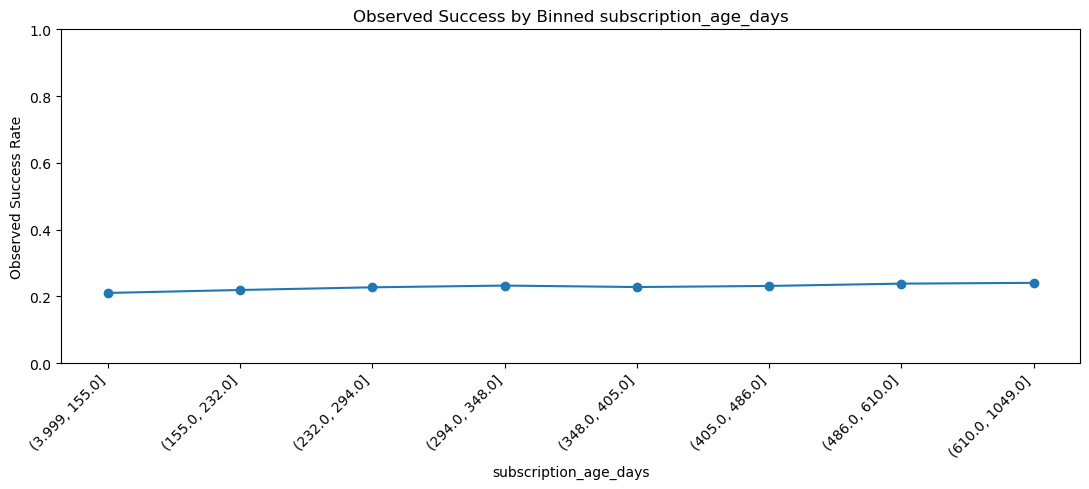

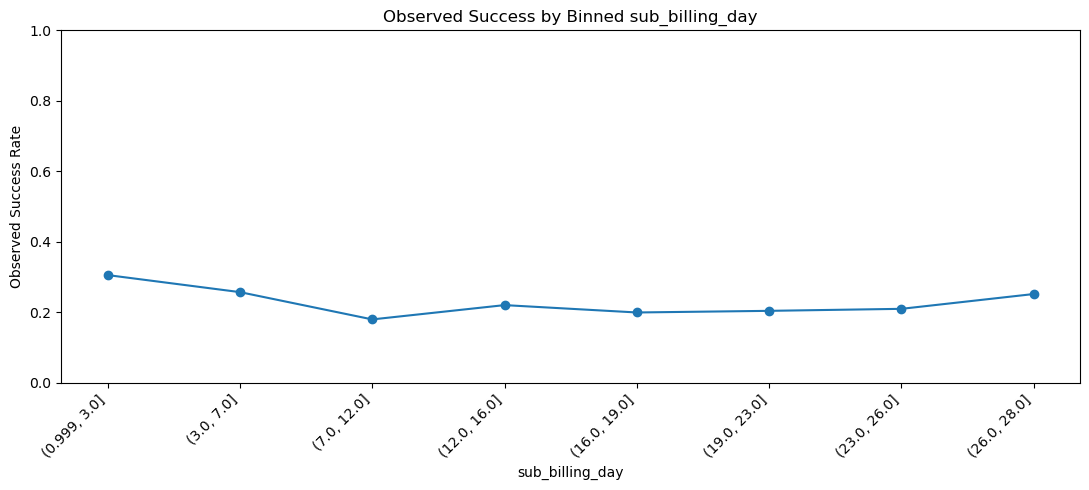

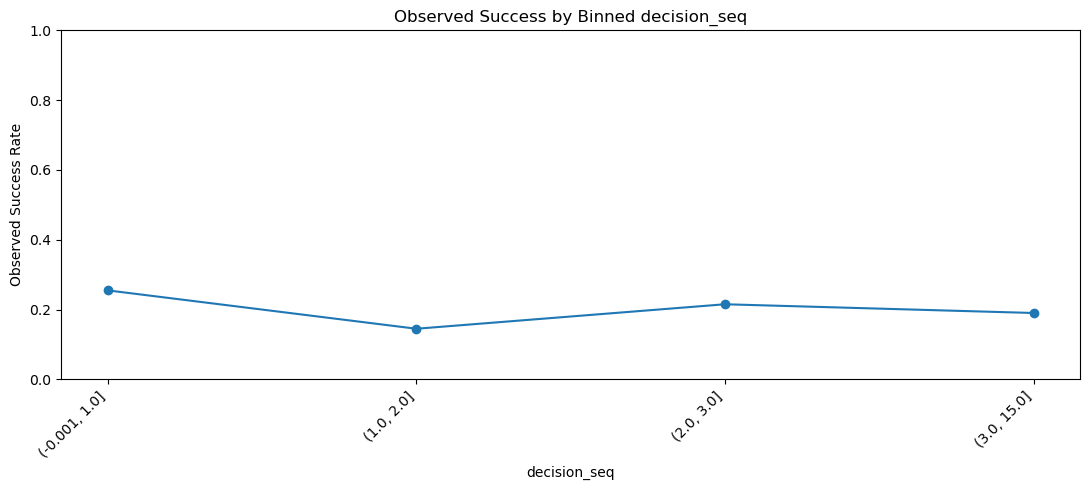

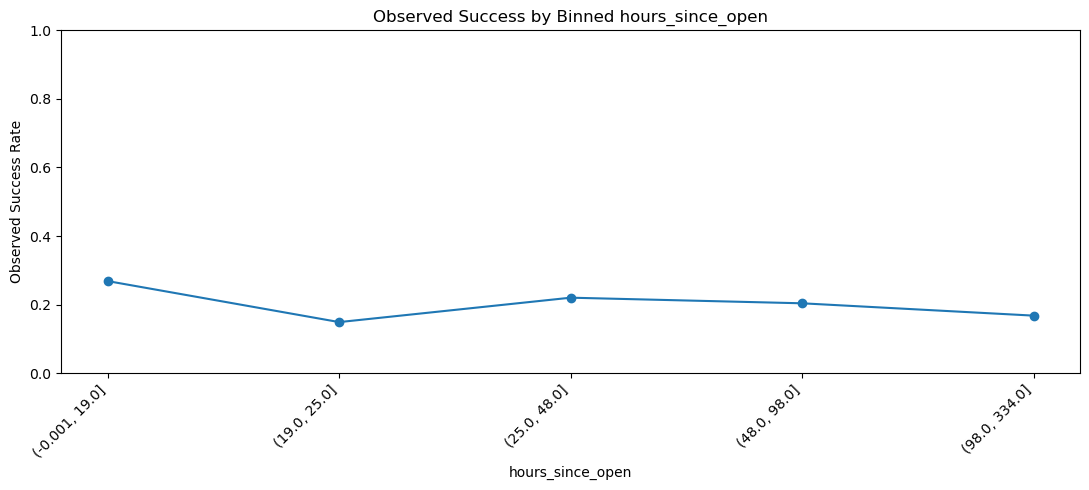

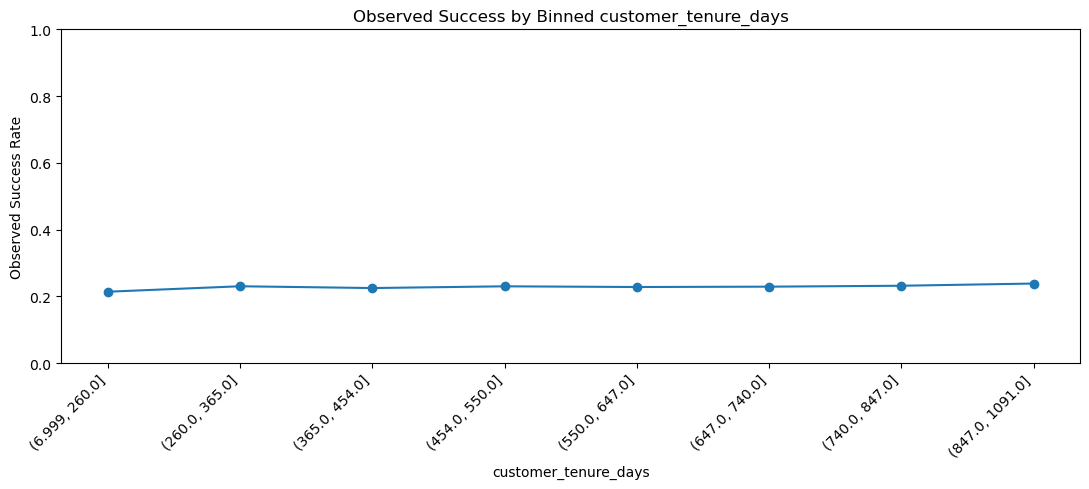

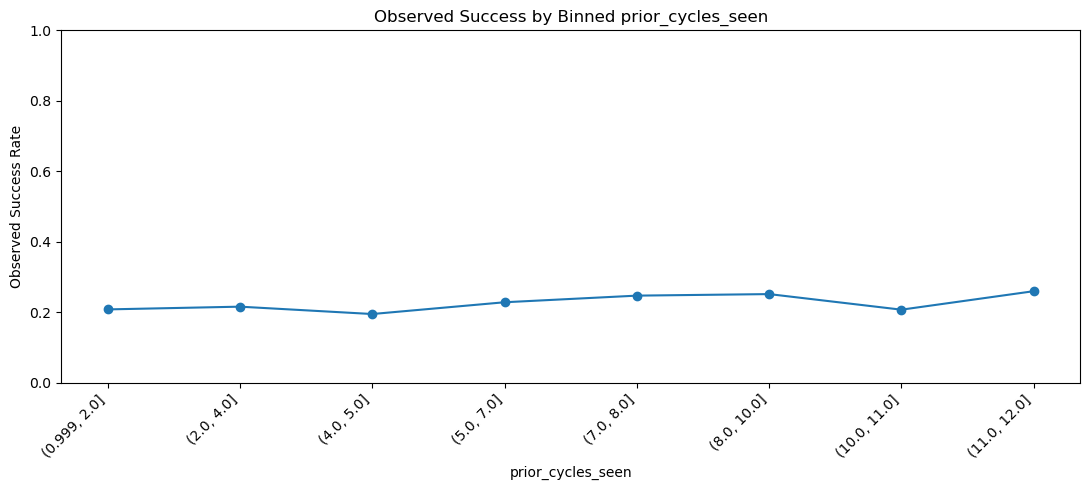

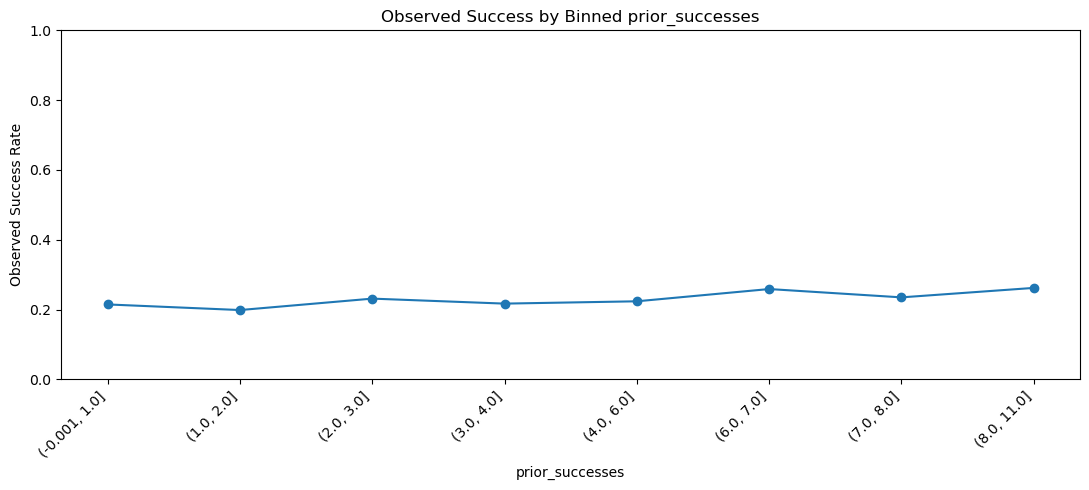

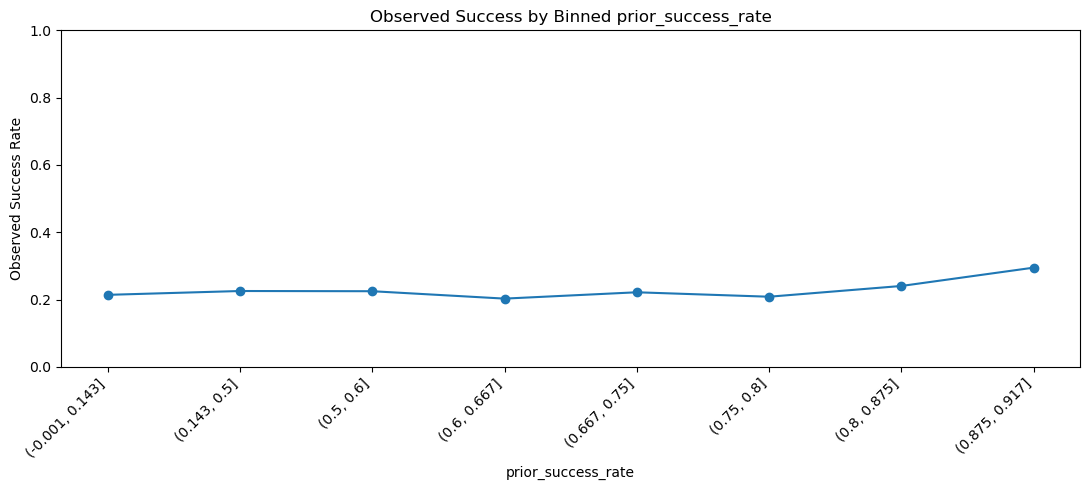

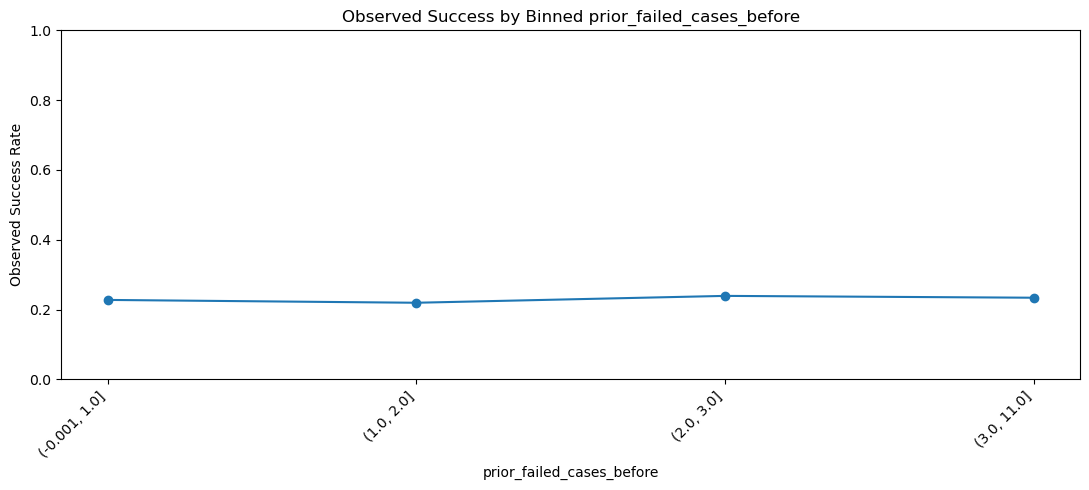

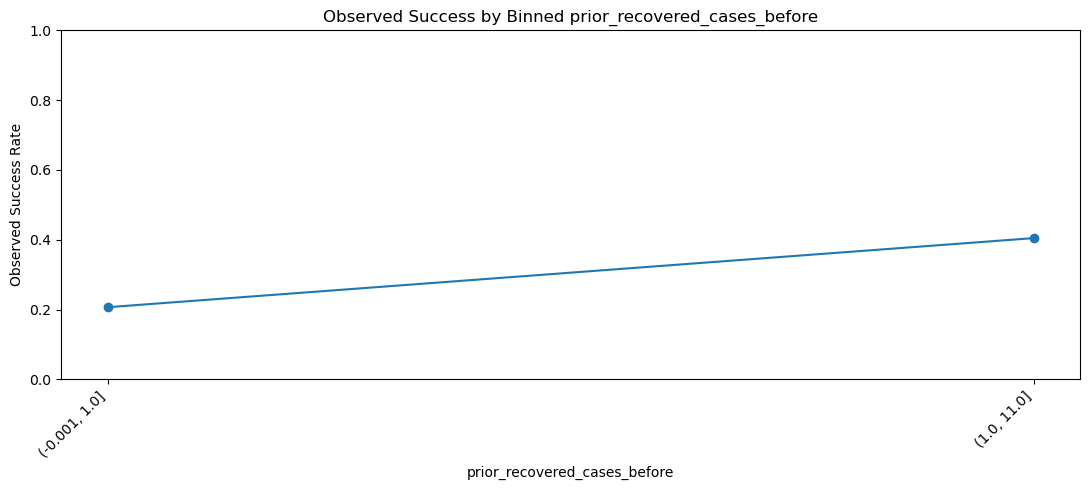

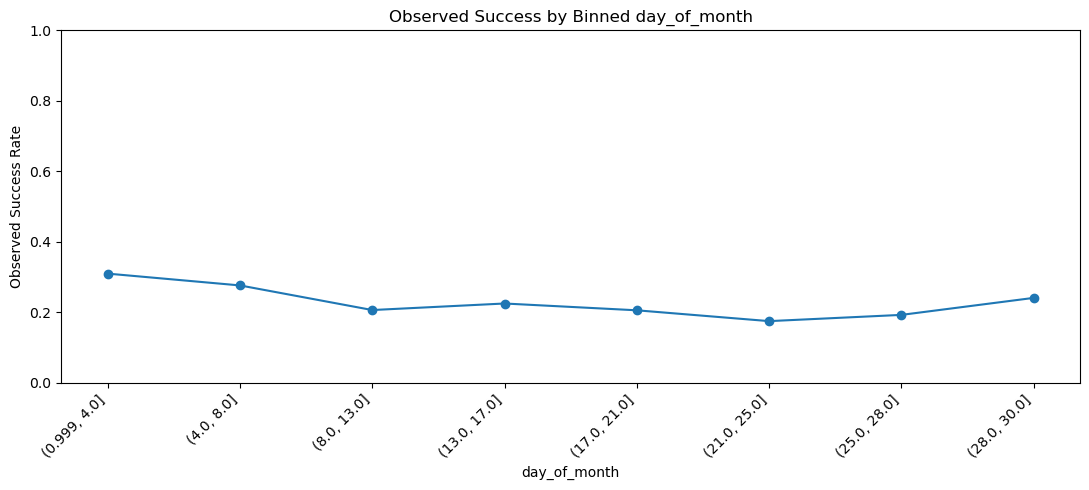

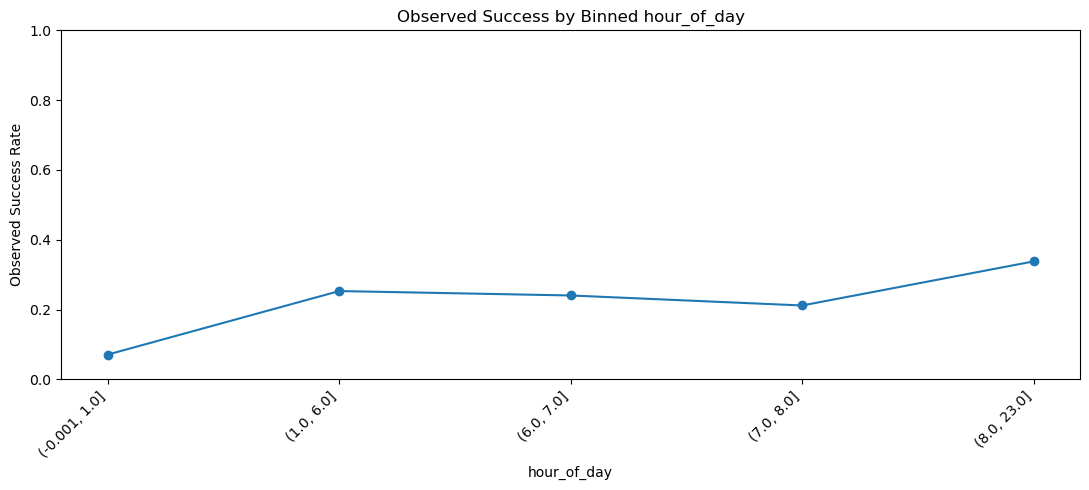

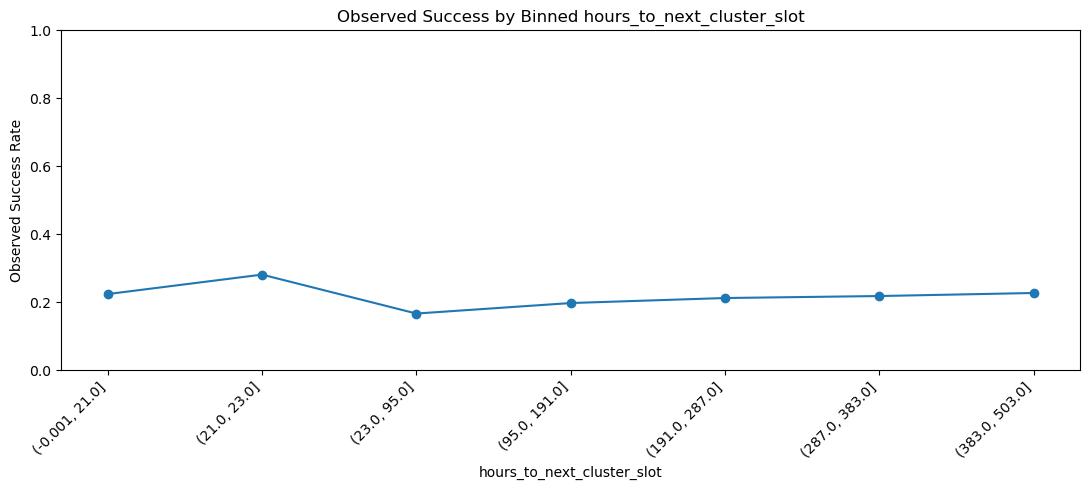

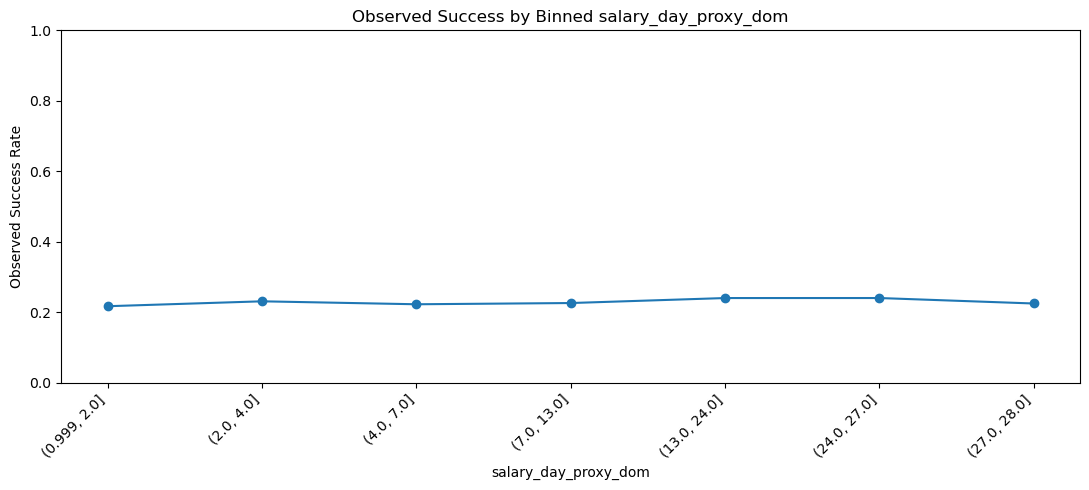

In [15]:

# Numeric features: binned observed success
for col in numeric_candidates:

    if col == target_col:
        continue

    temp = ml[[col, target_col]].dropna()

    if temp[col].nunique() < 8:
        continue

    try:
        temp["bin"] = pd.qcut(
            temp[col],
            q=8,
            duplicates="drop"
        )

        summary = (
            temp.groupby(
                "bin",
                observed=False
            )[target_col]
            .agg(
                observations="size",
                observed_success_rate="mean"
            )
            .reset_index()
        )

        summary = summary[
            summary["observations"] >= 30
        ]

        if len(summary) >= 2:

            plt.figure(figsize=(11, 5))
            plt.plot(
                range(len(summary)),
                summary["observed_success_rate"],
                marker="o"
            )
            plt.ylim(0, 1)
            plt.xticks(
                range(len(summary)),
                summary["bin"].astype(str),
                rotation=45,
                ha="right"
            )
            plt.xlabel(col)
            plt.ylabel("Observed Success Rate")
            plt.title(
                f"Observed Success by Binned {col}"
            )
            save_show(
                f"feature_target_binned_{col}.png"
            )

    except Exception as exc:
        print(
            f"Skipping binned target plot for {col}: {exc}"
        )


## 11. Recovery-Decision Interaction Graphs

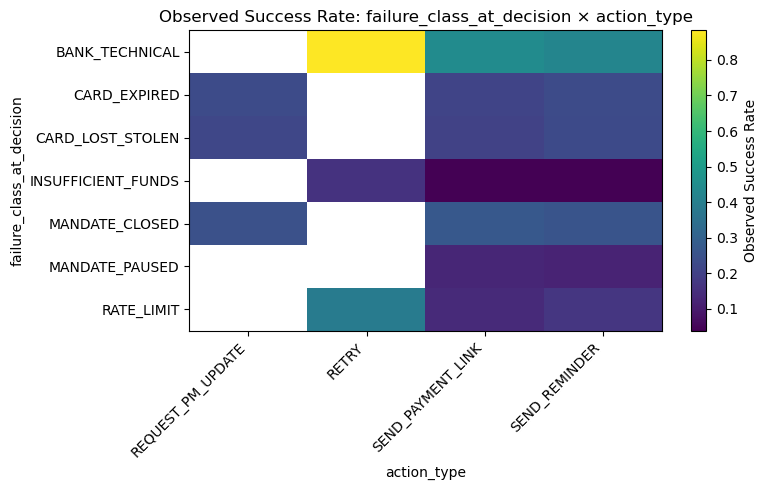

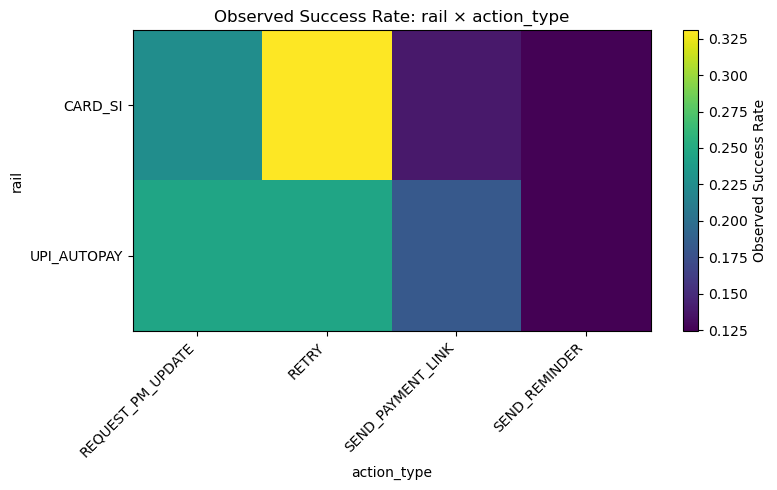

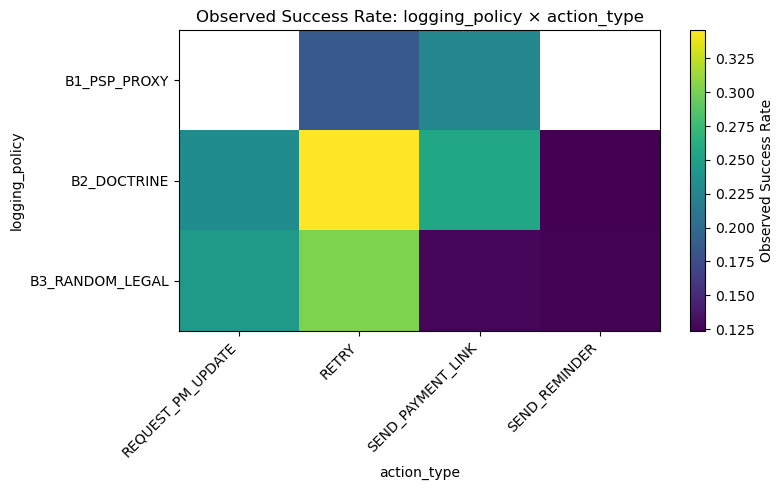

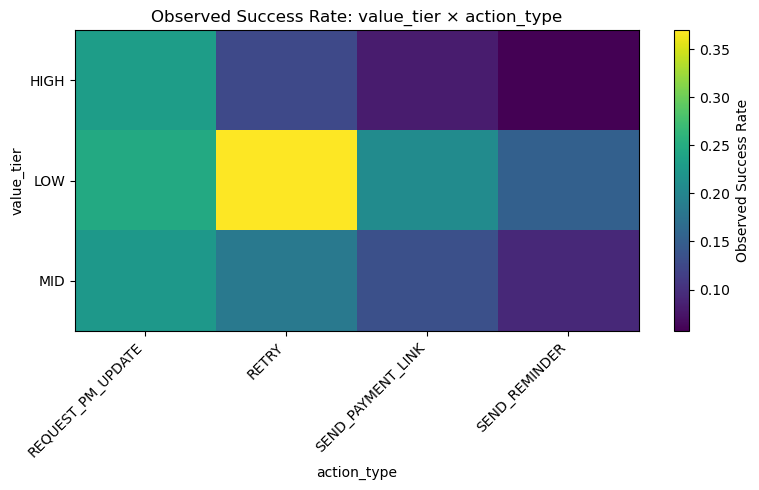

In [16]:

interaction_specs = [
    ("failure_class", "action_type"),
    ("failure_class_at_decision", "action_type"),
    ("rail", "action_type"),
    ("logging_policy", "action_type"),
    ("value_tier", "action_type"),
]

for x_col, y_col in interaction_specs:

    if not {x_col, y_col}.issubset(ml.columns):
        continue

    summary = (
        ml.groupby(
            [x_col, y_col],
            dropna=False
        )[target_col]
        .agg(
            observations="size",
            observed_success_rate="mean"
        )
        .reset_index()
    )

    pivot = summary.pivot(
        index=x_col,
        columns=y_col,
        values="observed_success_rate"
    )

    if pivot.empty:
        continue

    plt.figure(
        figsize=(
            max(8, len(pivot.columns) * 1.4),
            max(5, len(pivot.index) * 0.6)
        )
    )

    plt.imshow(
        pivot.values,
        aspect="auto",
    )

    plt.colorbar(
        label="Observed Success Rate"
    )

    plt.xticks(
        range(len(pivot.columns)),
        pivot.columns.astype(str),
        rotation=45,
        ha="right"
    )
    plt.yticks(
        range(len(pivot.index)),
        pivot.index.astype(str)
    )

    plt.xlabel(y_col)
    plt.ylabel(x_col)
    plt.title(
        f"Observed Success Rate: {x_col} × {y_col}"
    )

    save_show(
        f"interaction_{x_col}_by_{y_col}.png"
    )

    summary.to_csv(
        REPORT_DIR
        / f"interaction_{x_col}_by_{y_col}.csv",
        index=False,
    )


## 12. Salary / Timing Graphical Analysis

Use only observable salary proxies. Never use the latent true salary day.

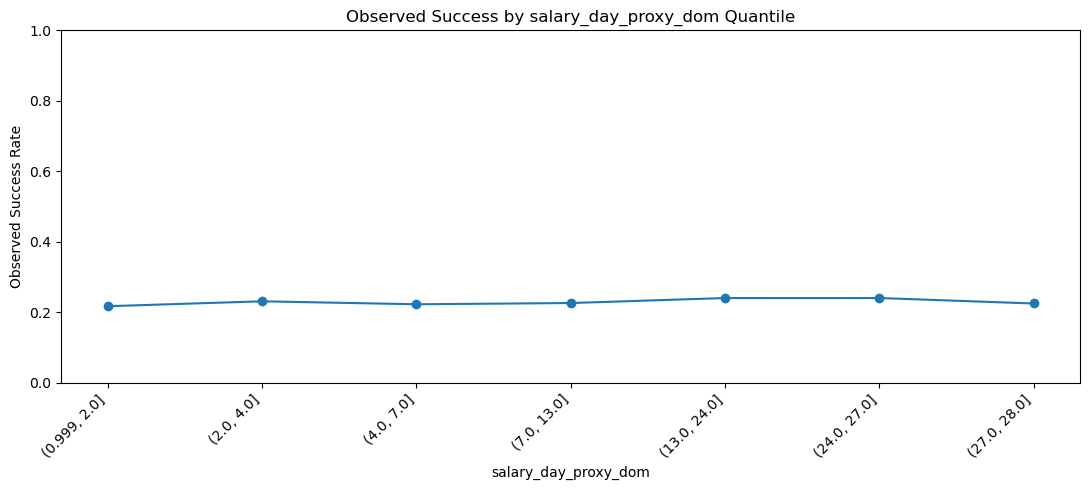

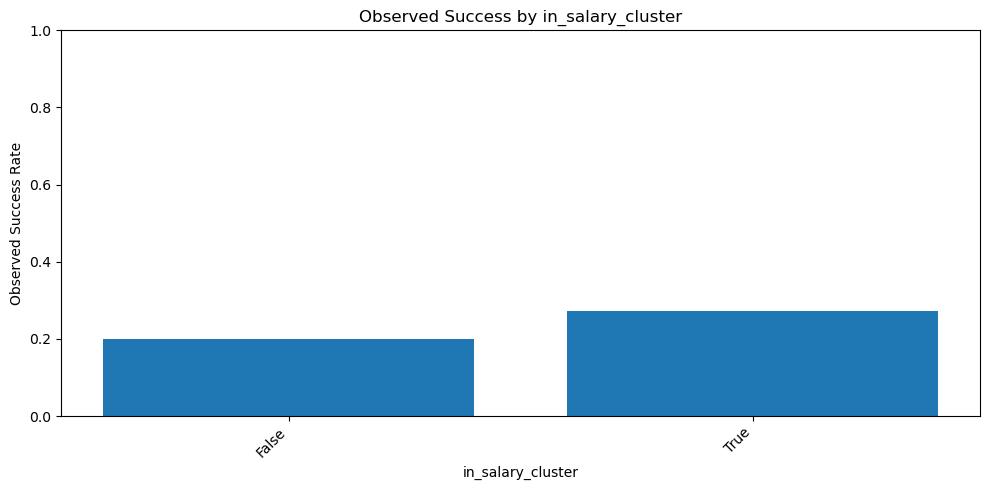

In [17]:

timing_specs = [
    "proxy_days_to_salary",
    "salary_day_proxy_dom",
    "time_since_first_failure_days",
    "tenure_months",
    "in_salary_cluster",
]

for col in timing_specs:

    if col not in ml.columns:
        continue

    s = ml[col]

    if (
        pd.api.types.is_numeric_dtype(s)
        and not pd.api.types.is_bool_dtype(s)
        and s.nunique(dropna=True) > 10
    ):

        temp = ml[[col, target_col]].dropna()

        if len(temp) < 50:
            continue

        try:
            temp["bin"] = pd.qcut(
                temp[col],
                q=8,
                duplicates="drop"
            )

            summary = (
                temp.groupby(
                    "bin",
                    observed=False
                )[target_col]
                .agg(
                    observations="size",
                    observed_success_rate="mean"
                )
                .reset_index()
            )

            plt.figure(figsize=(11, 5))
            plt.plot(
                range(len(summary)),
                summary["observed_success_rate"],
                marker="o"
            )
            plt.ylim(0, 1)
            plt.xticks(
                range(len(summary)),
                summary["bin"].astype(str),
                rotation=45,
                ha="right"
            )
            plt.xlabel(col)
            plt.ylabel("Observed Success Rate")
            plt.title(
                f"Observed Success by {col} Quantile"
            )
            save_show(
                f"timing_{col}_target.png"
            )

        except Exception as exc:
            print(
                f"Skipping timing plot for {col}: {exc}"
            )

    else:

        summary = (
            ml.groupby(
                col,
                dropna=False
            )[target_col]
            .agg(
                observations="size",
                observed_success_rate="mean"
            )
            .reset_index()
        )

        if len(summary) < 2:
            continue

        plt.figure(figsize=(10, 5))
        plt.bar(
            summary[col].astype(str),
            summary["observed_success_rate"]
        )
        plt.ylim(0, 1)
        plt.xlabel(col)
        plt.ylabel("Observed Success Rate")
        plt.title(
            f"Observed Success by {col}"
        )
        plt.xticks(
            rotation=45,
            ha="right"
        )
        save_show(
            f"timing_{col}_target.png"
        )


## 13. Target-Stratified Numeric Distributions

For selected high-value candidate features, compare distributions for
successful vs unsuccessful observed interventions.

C:\Users\Soham\AppData\Local\Temp\ipykernel_42744\1883906760.py:34: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


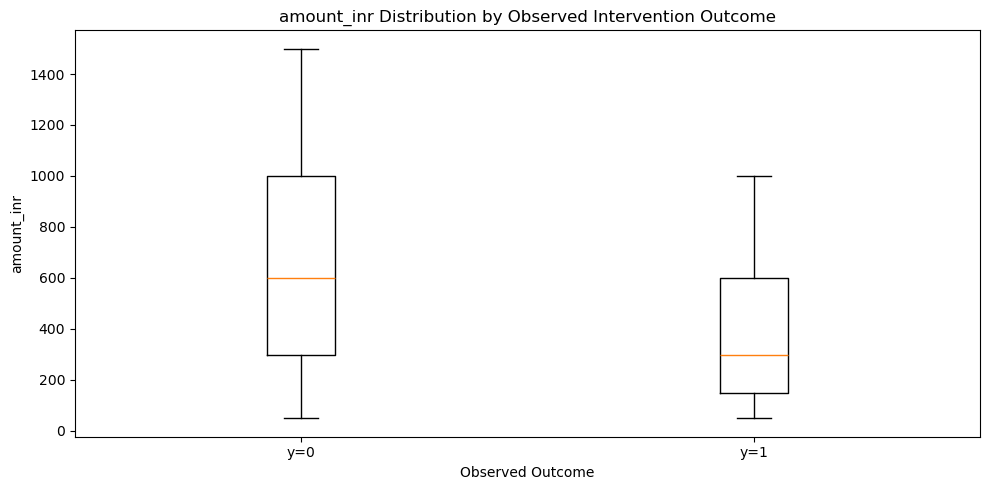

In [18]:

# Choose a small number of features with variation to avoid hundreds of plots.
preferred_numeric = [
    "amount_inr",
    "prior_failure_count",
    "tenure_months",
    "attempt_index",
    "time_since_first_failure_days",
    "proxy_days_to_salary",
]

for col in preferred_numeric:

    if col not in ml.columns:
        continue

    temp = ml[
        [col, target_col]
    ].dropna()

    if temp[col].nunique() < 5:
        continue

    success = temp.loc[
        temp[target_col] == 1,
        col
    ]

    failure = temp.loc[
        temp[target_col] == 0,
        col
    ]

    plt.figure(figsize=(10, 5))
    plt.boxplot(
        [failure, success],
        labels=["y=0", "y=1"],
        showfliers=False
    )
    plt.title(
        f"{col} Distribution by Observed Intervention Outcome"
    )
    plt.xlabel("Observed Outcome")
    plt.ylabel(col)
    save_show(
        f"target_stratified_{col}.png"
    )


## 14. Action Support Visualisation

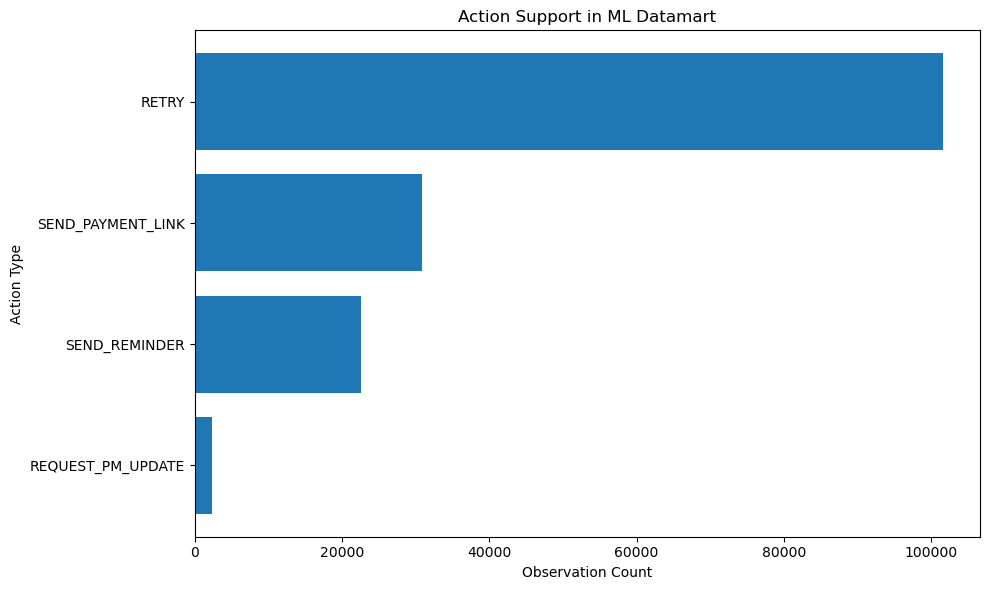

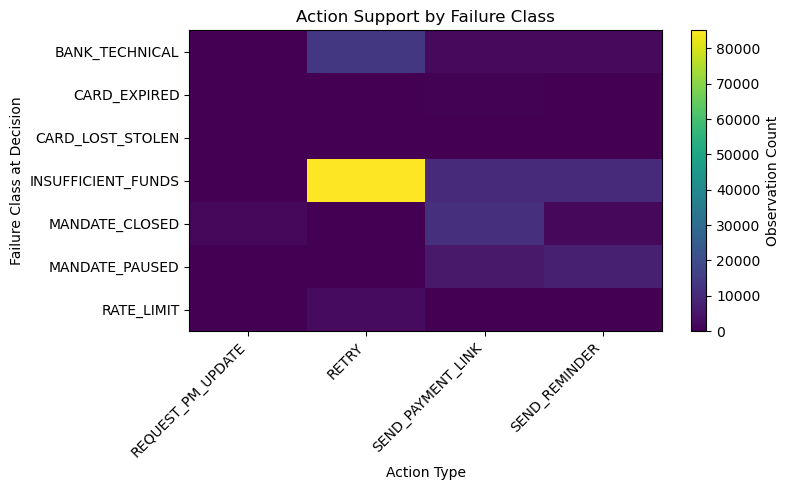

In [19]:

if "action_type" in ml.columns:

    support = (
        ml["action_type"]
        .value_counts()
        .sort_values()
    )

    plt.figure(figsize=(10, 6))
    plt.barh(
        support.index.astype(str),
        support.values
    )
    plt.xlabel("Observation Count")
    plt.ylabel("Action Type")
    plt.title("Action Support in ML Datamart")
    save_show(
        "action_support_overall.png"
    )

    if "failure_class_at_decision" in ml.columns:

        ct = pd.crosstab(
            ml["failure_class_at_decision"],
            ml["action_type"],
        )

        plt.figure(
            figsize=(
                max(8, len(ct.columns) * 1.5),
                max(5, len(ct.index) * 0.5),
            )
        )

        plt.imshow(
            ct.values,
            aspect="auto"
        )
        plt.colorbar(
            label="Observation Count"
        )
        plt.xticks(
            range(len(ct.columns)),
            ct.columns.astype(str),
            rotation=45,
            ha="right"
        )
        plt.yticks(
            range(len(ct.index)),
            ct.index.astype(str)
        )
        plt.xlabel("Action Type")
        plt.ylabel("Failure Class at Decision")
        plt.title(
            "Action Support by Failure Class"
        )
        save_show(
            "action_support_by_failure_class.png"
        )


## 15. C2B Output

This notebook saves only graphical/deep-dive EDA outputs under:

`reports/eda_graphical/`

C2B does not freeze features or train models.

After C2 + C2B are reviewed, proceed to **C3 — Feature Engineering + Final Feature Contract**.